In [4]:
import warnings
warnings.simplefilter("ignore")

import mlflow
import os
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt 
import pandas as pd
import numpy as np
from simulation_study_analysis_helpers import *

# move to project root directory to find the mlruns folder with mlflow experiments
notebook_path = Path().resolve()
project_root = notebook_path.parent  # adjust as needed
os.chdir(project_root)

from simulation_studies.generate_synthetic_vine_data import generate_synthetic_vine_data

## Analysis Functions

In [36]:
def get_data_original_and_bootstrap(df_runs,data="training_and_validation"):
    
    N_train = df_runs['tags.N_train'].astype(float).iloc[0].item()
    N_validate = df_runs['tags.N_validate'].astype(float).iloc[0].item()
    N_train_proportion = float(N_train / (N_train + N_validate))
    N_validate_proportion = float(N_validate / (N_train + N_validate))

    table_diffs_list = []
    table_original_dict = {}
    for seed in df_runs['tags.seed_value'].unique():
        
        df_of_seed = df_runs[df_runs['tags.seed_value']==str(seed)]
        df_of_seed = df_of_seed.sort_values("start_time", ascending=False) # Sort values so that it takes the artifact from the most recent run in case there where failed ones
        
        # TEMPORARY: for future bootstrap_warpspeed is a tag for now out of name
        if "tags.bootstrap_warpspeed" in df_of_seed.columns:
            bootstrap_bool = df_of_seed["tags.bootstrap_warpspeed"].str.contains("True")
        else:
            bootstrap_bool = df_of_seed["tags.mlflow.runName"].str.contains("bootstrap")
        df_run_bootstrap = df_of_seed[bootstrap_bool]
        df_run_original = df_of_seed[~bootstrap_bool]
        
        df_run_bootstrap = df_run_bootstrap.iloc[[0]]
        df_run_original = df_run_original.iloc[[0]]

        if data=="training_and_validation":
            # for train data and validate data
            #artifact_path = "conditional_independence_table_model_samples.csv" #"conditional_independence_table_data_train.csv"
            artifact_path = "conditional_independence_table_data_train.csv"
            table_bootstrap_train = pd.read_csv(mlflow.artifacts.download_artifacts(run_id=df_run_bootstrap['run_id'].item(), artifact_path=artifact_path))
            table_original_train = pd.read_csv(mlflow.artifacts.download_artifacts(run_id=df_run_original['run_id'].item(), artifact_path=artifact_path))
            #artifact_path = "conditional_independence_table_model_samples.csv" #"conditional_independence_table_data_validate.csv"
            artifact_path = "conditional_independence_table_data_validate.csv"
            table_bootstrap_validate = pd.read_csv(mlflow.artifacts.download_artifacts(run_id=df_run_bootstrap['run_id'].item(), artifact_path=artifact_path))
            table_original_validate = pd.read_csv(mlflow.artifacts.download_artifacts(run_id=df_run_original['run_id'].item(), artifact_path=artifact_path))
            
            # weight results together so its same data as used for training with GTM
            table_original = table_original_train.copy()
            table_bootstrap = table_bootstrap_train.copy()
            
            # check same ordering of var_row and var_col
            table_original.sort_values(by=['var_row', 'var_col'], inplace=True)
            table_bootstrap.sort_values(by=['var_row', 'var_col'], inplace=True)
            
            table_original.iloc[:, :3] = table_original.iloc[:, :3].astype(float)
            table_bootstrap.iloc[:, :3] = table_bootstrap.iloc[:, :3].astype(float)
            
            table_original.iloc[:, :3] = table_original_train.iloc[:, :3].astype(float) * N_train_proportion + table_original_validate.iloc[:, :3].astype(float) * N_validate_proportion
            table_bootstrap.iloc[:, :3] = table_bootstrap_train.iloc[:, :3].astype(float) * N_train_proportion + table_bootstrap_validate.iloc[:, :3].astype(float) * N_validate_proportion
        elif data=="synthetic":
            # for train data and validate data
            artifact_path = "conditional_independence_table_model_samples.csv" 
            table_bootstrap = pd.read_csv(mlflow.artifacts.download_artifacts(run_id=df_run_bootstrap['run_id'].item(), artifact_path=artifact_path))
            table_original = pd.read_csv(mlflow.artifacts.download_artifacts(run_id=df_run_original['run_id'].item(), artifact_path=artifact_path))
            
            # check same ordering of var_row and var_col
            table_original.sort_values(by=['var_row', 'var_col'], inplace=True)
            table_bootstrap.sort_values(by=['var_row', 'var_col'], inplace=True)
            
        # compute difference in tables for all except first 3 columns and last 3, laster are infors of dependence, tau of copula and copula
        table_diff = table_original.copy()
        table_diff = table_diff[['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'normed_hessian_abs_mean', 'hessian_abs_mean']]
        table_original = table_original[['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'normed_hessian_abs_mean', 'hessian_abs_mean']]
        table_bootstrap = table_bootstrap[['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'normed_hessian_abs_mean', 'hessian_abs_mean']]
        table_diff.iloc[:, 2:8] = table_original.iloc[:, 2:8] - table_bootstrap.iloc[:, 2:8]
            
        # across all seeds store the differences table in a joint array
        table_diffs_list.append(table_diff)
        table_original_dict[seed] = table_original
        
    return table_diffs_list, table_original_dict


In [37]:
def get_cleaned_runs_subset_bootstrap(experiment_name = "dvine_strong_10D_125obs_bootstrap_s0", 
                            mlruns_folder_name="mlruns_scratch",
                            seed_value=0,
                            vine_type="D-Vine",
                            Independence_tree=3):
    
    # Set Tracking URI Folder
    mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/"+mlruns_folder_name)
    
    # Get Experiment Runs
    experiment = mlflow.get_experiment_by_name(experiment_name) 
    df_runs = mlflow.search_runs([experiment.experiment_id])

    # subset only finished runs
    df_runs = df_runs[df_runs["end_time"].notna()]

    # get structure
    df_structure = generate_synthetic_vine_data(seed_value=seed_value,
                                                seed_value_copula=int(df_runs["tags.seed_value_copula"].iloc[0]),
                                                vine_type=vine_type,
                                                Independence_tree=Independence_tree)["df_true_structure"]
    
    # get all no lasso runs and split into bootstrap and origianl data runs
    subset_no = df_runs[["No" in df_runs.iloc[i]["tags.mlflow.runName"] for i in range(df_runs.shape[0])]]
    subset_no_original = subset_no[["Bootstrap" not in subset_no.iloc[i]["tags.mlflow.runName"] for i in range(subset_no.shape[0])]]
    subset_no_bootstrap = subset_no[["Bootstrap" in subset_no.iloc[i]["tags.mlflow.runName"] for i in range(subset_no.shape[0])]]

    # get all adaptive lasso runs and split into bootstrap and origianl data runs
    subset_adaptive = df_runs[["Adaptive" in df_runs.iloc[i]["tags.mlflow.runName"] for i in range(df_runs.shape[0])]]
    subset_adaptive_original = subset_adaptive[["Bootstrap" not in subset_adaptive.iloc[i]["tags.mlflow.runName"] for i in range(subset_adaptive.shape[0])]]
    subset_adaptive_bootstrap = subset_adaptive[["Bootstrap" in subset_adaptive.iloc[i]["tags.mlflow.runName"] for i in range(subset_adaptive.shape[0])]]

    # find out for which seeds we have all 4, done by seeing for which we have adaptive bootstrap as it is the last we run in simulations
    seeds_all_ran = np.unique(subset_adaptive_bootstrap["tags.seed_value"]).astype(int)
    print("The unique seeds are:", np.sort(seeds_all_ran))
    print("There are ", seeds_all_ran.shape[0], "nmber of unique seeds.")
    
    # subset the originals and bootstrap for the no and the orginals for the adaptive by the seeds where all ran    
    subset_no_original = subset_no_original[subset_no_original["tags.seed_value"].astype(int).isin(seeds_all_ran)]
    subset_no_bootstrap = subset_no_bootstrap[subset_no_bootstrap["tags.seed_value"].astype(int).isin(seeds_all_ran)]
    subset_adaptive_original = subset_adaptive_original[subset_adaptive_original["tags.seed_value"].astype(int).isin(seeds_all_ran)]

    return subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure

In [38]:
def get_data_original_and_bootstrap(df_original, df_bootstrap, data="training_and_validation", 
                                    columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'normed_hessian_abs_mean', 'hessian_abs_mean']):
    
    N_train = df_original['tags.N_train'].astype(float).iloc[0].item()
    N_validate = df_original['tags.N_validate'].astype(float).iloc[0].item()
    N_train_proportion = float(N_train / (N_train + N_validate))
    N_validate_proportion = float(N_validate / (N_train + N_validate))

    table_diffs_list = []
    table_original_dict = {}
    for seed in df_original['tags.seed_value'].unique():

        df_run_bootstrap = df_bootstrap[df_bootstrap['tags.seed_value']==str(seed)].iloc[[0]]
        df_run_original = df_original[df_original['tags.seed_value']==str(seed)].iloc[[0]]

        if data=="training_and_validation":
            # for train data and validate data
            #artifact_path = "conditional_independence_table_model_samples.csv" #"conditional_independence_table_data_train.csv"
            artifact_path = "conditional_independence_table_data_train.csv"
            table_bootstrap_train = pd.read_csv(mlflow.artifacts.download_artifacts(run_id=df_run_bootstrap['run_id'].item(), artifact_path=artifact_path))
            table_original_train = pd.read_csv(mlflow.artifacts.download_artifacts(run_id=df_run_original['run_id'].item(), artifact_path=artifact_path))
            #artifact_path = "conditional_independence_table_model_samples.csv" #"conditional_independence_table_data_validate.csv"
            artifact_path = "conditional_independence_table_data_validate.csv"
            table_bootstrap_validate = pd.read_csv(mlflow.artifacts.download_artifacts(run_id=df_run_bootstrap['run_id'].item(), artifact_path=artifact_path))
            table_original_validate = pd.read_csv(mlflow.artifacts.download_artifacts(run_id=df_run_original['run_id'].item(), artifact_path=artifact_path))
            
            # weight results together so its same data as used for training with GTM
            table_original = table_original_train.copy()
            table_bootstrap = table_bootstrap_train.copy()
            
            # check same ordering of var_row and var_col
            table_original.sort_values(by=['var_row', 'var_col'], inplace=True)
            table_bootstrap.sort_values(by=['var_row', 'var_col'], inplace=True)
            
            table_original.iloc[:, :3] = table_original.iloc[:, :3].astype(float)
            table_bootstrap.iloc[:, :3] = table_bootstrap.iloc[:, :3].astype(float)
            
            table_original.iloc[:, :3] = table_original_train.iloc[:, :3].astype(float) * N_train_proportion + table_original_validate.iloc[:, :3].astype(float) * N_validate_proportion
            table_bootstrap.iloc[:, :3] = table_bootstrap_train.iloc[:, :3].astype(float) * N_train_proportion + table_bootstrap_validate.iloc[:, :3].astype(float) * N_validate_proportion
        elif data=="synthetic":
            # for train data and validate data
            artifact_path = "conditional_independence_table_model_samples.csv" 
            table_bootstrap = pd.read_csv(mlflow.artifacts.download_artifacts(run_id=df_run_bootstrap['run_id'].item(), artifact_path=artifact_path))
            table_original = pd.read_csv(mlflow.artifacts.download_artifacts(run_id=df_run_original['run_id'].item(), artifact_path=artifact_path))
            
            # check same ordering of var_row and var_col
            table_original.sort_values(by=['var_row', 'var_col'], inplace=True)
            table_bootstrap.sort_values(by=['var_row', 'var_col'], inplace=True)
            
        # compute difference in tables for all except first 3 columns and last 3, laster are infors of dependence, tau of copula and copula
        table_diff = table_original.copy()
        table_diff = table_diff[columns_metrics]
        table_original = table_original[columns_metrics]
        table_bootstrap = table_bootstrap[columns_metrics]
        table_diff.iloc[:, 2:8] = table_original.iloc[:, 2:8] - table_bootstrap.iloc[:, 2:8]
            
        # across all seeds store the differences table in a joint array
        table_diffs_list.append(table_diff)
        table_original_dict[seed] = table_original
        
    return table_diffs_list, table_original_dict


In [39]:
def plot_metric_percentage_above_zero_bootstrap_intervals_across_seeds(table_original_dict,table_diffs_list,df_structure,metric,ylim=(-0.1,1.1)):
    
    seeds_list = list(table_original_dict.keys())
    
    df_structure.sort_values(by=['var_row', 'var_col'], inplace=True)
    dependence = df_structure["dependence"]
    #if dependence is 1 set to lightblue else to red
    colors = ['lightblue' if dep == 1 else 'red' for dep in dependence]
    
    first_table_original_dict = table_original_dict[next(iter(table_original_dict))]
    
    dict_diffs = {}
    for pair in zip(first_table_original_dict['var_row'], first_table_original_dict['var_col']):
        varrow = pair[0]
        varcol = pair[1]
        diffs_to_plot = []
        for table_diffs in table_diffs_list:
            diffs_value = table_diffs[(table_diffs['var_col'] == varcol) & (table_diffs['var_row'] == varrow)][metric].values[0]
            diffs_to_plot.append(diffs_value)
            
        dict_diffs[f"{int(varrow)}-{int(varcol)}"] = diffs_to_plot
    
    # for each seed plot boxplot of differences around orginal kld
    list_percentage_ci_above_0 = []
    for seed in seeds_list:
        table_original = table_original_dict[seed]

        # add vector to the 
        centered_data = pd.DataFrame(dict_diffs) + np.array(table_original[metric])
        
        percentage_ci_above_0 = (centered_data > 0).mean(0)
        
        list_percentage_ci_above_0.append(percentage_ci_above_0)

    df_percentage_ci_above_0 = pd.DataFrame(list_percentage_ci_above_0)

    # --- Boxplot with 90% interval (whis=[5, 95]) ---
    sns.boxplot(data=df_percentage_ci_above_0, whis=[5, 95], showfliers=False, palette=colors)
    # Colors on independence from above
    sns.stripplot(data=df_percentage_ci_above_0, palette=colors, alpha=0.4, edgecolor="black", dodge=True, jitter=0.25)

    plt.ylim(ylim)
    plt.axhline(0, color='red', linestyle='--')
    plt.ylabel("Percentage")
    plt.title("Boxplot of Percentage of the Bootstrap Interal Points above 0 {} per Pair across Seeds".format(metric))
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    

In [40]:
def plot_metric_values_across_seeds(table_original_dict,df_structure,metric,ylim=(-0.05,0.25)):
    
    seeds_list = list(table_original_dict.keys())
    
    df_structure.sort_values(by=['var_row', 'var_col'], inplace=True)
    dependence = df_structure["dependence"]
    #if dependence is 1 set to lightblue else to red
    colors = ['lightblue' if dep == 1 else 'red' for dep in dependence]
    
    list_average_ci = []
    for seed in seeds_list:
        table_original = table_original_dict[seed]

        # add vector to the 
        centered_data = np.array(table_original[metric]) #pd.DataFrame(dict_diffs) + 
        
        average_ci = centered_data#.mean(0)

        list_average_ci.append(average_ci)

    df_average_ci = pd.DataFrame(list_average_ci)
    # --- Boxplot with 90% interval (whis=[5, 95]) ---
    sns.boxplot(data=df_average_ci, whis=[5, 95], showfliers=False, palette=colors)
    # Colors on independence from above
    sns.stripplot(data=df_average_ci, palette=colors, alpha=0.4, edgecolor="black", dodge=True, jitter=0.25)

    plt.ylim(ylim)
    plt.axhline(0, color='red', linestyle='--')
    plt.ylabel("Value")
    plt.title("Boxplot of {}  per Pair across Seeds".format(metric))
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [41]:
def plot_metric_bootstrap_intervals_for_each_seed(table_original_dict,table_diffs_list,df_structure,metric,ylim=(-0.05,0.25)):
    
    seeds_list = list(table_original_dict.keys())
    
    df_structure.sort_values(by=['var_row', 'var_col'], inplace=True)
    dependence = df_structure["dependence"]
    #if dependence is 1 set to lightblue else to red
    colors = ['lightblue' if dep == 1 else 'red' for dep in dependence]
    
    first_table_original_dict = table_original_dict[next(iter(table_original_dict))]
    
    dict_diffs = {}
    for pair in zip(first_table_original_dict['var_row'], first_table_original_dict['var_col']):
        varrow = pair[0]
        varcol = pair[1]
        diffs_to_plot = []
        for table_diffs in table_diffs_list:
            diffs_value = table_diffs[(table_diffs['var_col'] == varcol) & (table_diffs['var_row'] == varrow)][metric].values[0]
            diffs_to_plot.append(diffs_value)
            
        dict_diffs[f"{int(varrow)}-{int(varcol)}"] = diffs_to_plot
        

    for seed in seeds_list:
        table_original = table_original_dict[seed]

        # add vector to the 
        centered_data = pd.DataFrame(dict_diffs) + np.array(table_original[metric])

        # check that the centering worked for all columns
        if all((pd.DataFrame(dict_diffs).iloc[:,0] + np.array(table_original[metric])[0]) == centered_data.iloc[:,0]):
            pass
        else:
            print("Centering failed.")
            
        if all((pd.DataFrame(dict_diffs).iloc[:,3] + np.array(table_original[metric])[3]) == centered_data.iloc[:,3]):
            pass
        else:
            print("Centering failed.")

        plt.figure(figsize=(12, 6))
        
        
        #sns.violinplot(data=centered_data)
        
        # --- Boxplot with 90% interval (whis=[5, 95]) ---
        sns.boxplot(data=centered_data, whis=[5, 95], showfliers=False, palette=colors)
        # Colors on independence from above

        # --- Show data points overlaid (jittered) ---
        # Use stripplot for point overlay; set jitter for clarity
        sns.stripplot(data=centered_data, palette=colors, alpha=0.4, edgecolor="black", dodge=True, jitter=0.25)
        
        
        plt.axhline(0, color='red', linestyle='--')
        plt.ylabel("Value")
        plt.title("{} Warpspeed Bootstrap Intervals around Original, Seed ".format(metric) + str(seed))
        plt.xticks(rotation=45)
        plt.ylim(ylim)
        plt.tight_layout()
        plt.show()

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

def plot_metric_values_across_seeds(
    table_original_dict,
    df_structure,
    metric,
    ylim=(-0.05, 0.25),
    plot_dependence="all"  # "all", "dependent", or "independent"
):
    
    seeds_list = list(table_original_dict.keys())
    
    df_structure_sorted = df_structure.sort_values(by=['var_row', 'var_col'])
    dependence = df_structure_sorted["dependence"].values
    colors = ['lightblue' if dep == 1 else 'red' for dep in dependence]

    # Determine pairs to keep
    if plot_dependence == "dependent":
        keep = dependence == 1
    elif plot_dependence == "independent":
        keep = dependence == 0
    else:  # "all"
        keep = np.ones(len(dependence), dtype=bool)

    # Collect metric values for each seed for selected pairs
    list_metric = []
    for seed in seeds_list:
        table_original = table_original_dict[seed]
        centered_data = np.array(table_original[metric])[keep]
        list_metric.append(centered_data)

    # Only plot if we have data
    if len(list_metric) == 0 or len(list_metric[0]) == 0:
        print("No data to plot for the requested subset.")
        return

    df_metric = pd.DataFrame(list_metric)
    selected_colors = [c for i, c in enumerate(colors) if keep[i]]

    plt.figure(figsize=(max(8, len(df_metric.columns)*0.25), 4))
    sns.boxplot(data=df_metric, whis=[5, 95], showfliers=False, palette=selected_colors)
    sns.stripplot(data=df_metric, palette=selected_colors, alpha=0.4, edgecolor="black", dodge=True, jitter=0.25)

    plt.ylim(ylim)
    plt.axhline(0, color='red', linestyle='--')
    plt.ylabel("Value")
    plt.title(f"Boxplot of {metric} per Pair across Seeds ({plot_dependence})")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [43]:
def plot_metric_values_no_vs_adaptive(
    table_original_dict_no,
    table_original_dict_adaptive,
    df_structure,
    metric,
    plot_dependence="all",  # "all", "dependent", "independent"
    ylim=(-0.05, 0.25),
    plot_title=True,
    threshold=0.05
):
    
    seeds_list = list(table_original_dict_no.keys())
    
    df_structure_sorted = df_structure.sort_values(by=['var_row', 'var_col'])
    dependence = df_structure_sorted["dependence"].values

    if plot_dependence == "dependent":
        keep = dependence == 1
    elif plot_dependence == "independent":
        keep = dependence == 0
    else:
        keep = np.ones(len(dependence), dtype=bool)

    # Prepare data: for each pair, two groups (no & adaptive), each as a list across seeds
    data_no = []
    data_adaptive = []
    pair_labels = []
    for col_idx, keep_idx in enumerate(keep):
        if not keep_idx:
            continue
        pair_labels.append(df_structure_sorted.iloc[col_idx][['var_row', 'var_col']].values)
        # For this pair, collect all seeds for 'no'
        col_no = []
        for seed in seeds_list:
            table = table_original_dict_no[str(seed)]
            col_no.append(np.array(table[metric])[col_idx])
        data_no.append(col_no)

        # For this pair, collect all seeds for 'adaptive'
        col_adaptive = []
        for seed in seeds_list:
            table = table_original_dict_adaptive[str(seed)]
            col_adaptive.append(np.array(table[metric])[col_idx])
        data_adaptive.append(col_adaptive)

    # convert to DataFrame for seaborn
    df_no = pd.DataFrame(data_no).T  # Each column = a pair, each row = seed
    df_adaptive = pd.DataFrame(data_adaptive).T

    # Prepare for side-by-side paired boxplots
    plt.figure(figsize=(max(8, len(df_no.columns) * 0.6), 5))
    positions = np.arange(len(df_no.columns))
    width = 0.35

    # Plot for 'No'
    parts_no = plt.boxplot(
    df_no.values, positions=positions - width/2, widths=width,
    patch_artist=True, showfliers=False, boxprops=dict(facecolor='#1f77b4'),
    whis=[10, 90])
    
    # Plot for 'Adaptive'
    parts_adaptive = plt.boxplot(
    df_adaptive.values, positions=positions + width/2, widths=width,
    patch_artist=True, showfliers=False, boxprops=dict(facecolor='#2ca02c'),
    whis=[10, 90])
    
    if threshold > 0:
        plt.axhline(threshold, color='green', linestyle='--', linewidth=1, label='Threshold')
    
    # Add the scatter points for observations
    for idx in range(df_no.shape[1]):
        # x positions for scatters (centered per boxplot group, with jitter)
        x_no = positions[idx] - width/2 + np.random.uniform(-0.07, 0.07, size=df_no.shape[0])
        x_adaptive = positions[idx] + width/2 + np.random.uniform(-0.07, 0.07, size=df_adaptive.shape[0])
        plt.scatter(x_no, df_no.iloc[:, idx], color='#1f77b4', s=12, alpha=0.7, label='_nolegend_')
        plt.scatter(x_adaptive, df_adaptive.iloc[:, idx], color='#2ca02c', s=12, alpha=0.7, label='_nolegend_')
    

    plt.axhline(0, color='red', linestyle='--')
    plt.xticks(positions, [f"({v[0]},{v[1]})" for v in pair_labels], rotation=45)
    plt.ylim(ylim)
    plt.legend([plt.Rectangle((0,0),1,1,facecolor='#1f77b4'),
                plt.Rectangle((0,0),1,1,facecolor='#2ca02c')], ['No Lasso', 'Adaptive Lasso'])
    plt.tight_layout()
    if plot_title == True:
        plt.title(f"Comparison of {metric} per Pair (No vs Adaptive, {plot_dependence})")
    plt.ylabel("Value")
    plt.show()

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, matthews_corrcoef

def prdplot_metric_score_vs_threshold(
    table_original_dict_no,
    table_original_dict_adaptive,
    df_structure,
    metric,
    plot_dependence="independent",  # or "dependent" or "all"
    ylim=(0, 1),
    thresholds=None,
    conf_percentiles=(5, 95),
    score_type="f1"  # "f1" or "mcc"
):
    
    seeds_list = list(table_original_dict_no.keys())
    
    # Set up thresholds if not provided
    if thresholds is None:
        all_vals = []
        for tbl in list(table_original_dict_no.values()) + list(table_original_dict_adaptive.values()):
            all_vals.extend(tbl[metric])
        thresholds = np.quantile(all_vals, np.linspace(0, 0.1, 101))
    thresholds = np.array(thresholds)
    
    df_structure_sorted = df_structure.sort_values(by=['var_row', 'var_col']).reset_index(drop=True)
    dependence = df_structure_sorted["dependence"].values
    if plot_dependence == "dependent":
        keep = dependence == 1
    elif plot_dependence == "independent":
        keep = dependence == 0
    else:
        keep = np.ones(len(dependence), dtype=bool)
    y_true = dependence[keep]

    score_funcs = {
        "f1": lambda y_true, pred: f1_score(y_true, pred, zero_division=0),
        "mcc": matthews_corrcoef
    }
    if score_type not in score_funcs:
        raise ValueError("score_type must be 'f1' or 'mcc'")

    def get_scores(table_dict):
        all_scores = np.zeros((len(seeds_list), len(thresholds)))
        for si, seed in enumerate(seeds_list):
            table = table_dict[str(seed)]
            metric_vals = np.array(table[metric])[keep]
            for ti, thresh in enumerate(thresholds):
                pred = (metric_vals >= thresh).astype(int)
                try:
                    score = score_funcs[score_type](y_true, pred)
                except Exception:
                    score = 0.0
                all_scores[si, ti] = score
        return all_scores

    scores_no = get_scores(table_original_dict_no)
    scores_adaptive = get_scores(table_original_dict_adaptive)

    mean_no = np.mean(scores_no, axis=0)
    lower_no = np.percentile(scores_no, conf_percentiles[0], axis=0)
    upper_no = np.percentile(scores_no, conf_percentiles[1], axis=0)
    mean_adaptive = np.mean(scores_adaptive, axis=0)
    lower_adaptive = np.percentile(scores_adaptive, conf_percentiles[0], axis=0)
    upper_adaptive = np.percentile(scores_adaptive, conf_percentiles[1], axis=0)

    plt.figure(figsize=(7, 5))
    plt.plot(thresholds, mean_no, label="No Lasso", color='#1f77b4') #2ca02c
    plt.fill_between(thresholds, lower_no, upper_no, color='#1f77b4', alpha=0.15)
    plt.plot(thresholds, mean_adaptive, label="Adaptive Lasso", color='#2ca02c')
    plt.fill_between(thresholds, lower_adaptive, upper_adaptive, color='#2ca02c', alpha=0.15)
    plt.xlabel(f"{metric} threshold")
    plt.ylabel(f"{score_type.upper()} Score")
    plt.legend()
    plt.ylim(ylim)
    plt.title(f"Prediction {score_type.upper()} for {metric} ({plot_dependence} pairs)")
    plt.grid(True, linestyle='--', linewidth=0.5)
    plt.tight_layout()
    plt.show()

In [45]:
def df_metric_percentage_above_zero_bootstrap_intervals_across_seeds(table_original_dict,table_diffs_list,df_structure,metric,ylim=(-0.1,1.1)):
    
    seeds_list = list(table_original_dict_no.keys())
    
    df_structure.sort_values(by=['var_row', 'var_col'], inplace=True)
    dependence = df_structure["dependence"]
    #if dependence is 1 set to lightblue else to red
    colors = ['lightblue' if dep == 1 else 'red' for dep in dependence]
    
    first_table_original_dict = table_original_dict[next(iter(table_original_dict))]
    
    dict_diffs = {}
    for pair in zip(first_table_original_dict['var_row'], first_table_original_dict['var_col']):
        varrow = pair[0]
        varcol = pair[1]
        diffs_to_plot = []
        for table_diffs in table_diffs_list:
            diffs_value = table_diffs[(table_diffs['var_col'] == varcol) & (table_diffs['var_row'] == varrow)][metric].values[0]
            diffs_to_plot.append(diffs_value)
            
        dict_diffs[f"{int(varrow)}-{int(varcol)}"] = diffs_to_plot
    
    # for each seed plot boxplot of differences around orginal kld
    list_percentage_ci_above_0 = []
    for seed in seeds_list:
        table_original = table_original_dict[seed]

        # add vector to the 
        centered_data = pd.DataFrame(dict_diffs) + np.array(table_original[metric])
        
        percentage_ci_above_0 = (centered_data > 0).mean(0)
        
        list_percentage_ci_above_0.append(percentage_ci_above_0)

    return  pd.DataFrame(list_percentage_ci_above_0), colors

In [46]:
def plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict, table_diffs_list, df_structure, metric, ylim=(-0.05, 0.25), n=125, plot_pvalues_histogramm_grid=False):
    
    df_structure.sort_values(by=['var_row', 'var_col'], inplace=True)
    dependence = df_structure["dependence"]
    colors = ['lightblue' if dep == 1 else 'red' for dep in dependence]
    
    first_table_original_dict = table_original_dict[next(iter(table_original_dict))]
    
    dict_diffs = {}
    dict_originals = {}
    for pair in zip(first_table_original_dict['var_row'], first_table_original_dict['var_col']):
        varrow = pair[0]
        varcol = pair[1]
        diffs_to_plot = []
        original_to_plot = []
        for table_diffs in table_diffs_list:
            diffs_value = table_diffs[(table_diffs['var_col'] == varcol) & (table_diffs['var_row'] == varrow)][metric].values[0]
            diffs_to_plot.append(diffs_value)
            
        for seed in table_original_dict.keys():
            original_value = table_original_dict[seed][(table_original_dict[seed]['var_col'] == varcol) & (table_original_dict[seed]['var_row'] == varrow)][metric].values[0]
            original_to_plot.append(original_value)
                
        dict_diffs[f"{int(varrow)}-{int(varcol)}"] = diffs_to_plot
        dict_originals[f"{int(varrow)}-{int(varcol)}"] = original_to_plot

    table_original = pd.DataFrame(dict_originals)
    bootstrap_centered_data = np.abs(pd.DataFrame(dict_diffs))

    # --- Compute p-values ---
    pvalue_records = []
    for pair in table_original.columns:
        varrow, varcol = pair.split("-")
        
        T_star_centered = np.sqrt(n) * bootstrap_centered_data[pair].values

        # get dependence for this pair
        dep = df_structure[
            (df_structure['var_row'] == int(varrow)) & 
            (df_structure['var_col'] == int(varcol))
        ]['dependence'].values[0]
        
        for seed in table_original_dict.keys():
            phi_original = table_original_dict[seed][
                (table_original_dict[seed]['var_col'] == int(varcol)) & 
                (table_original_dict[seed]['var_row'] == int(varrow))
            ][metric].values[0]
            
            T_n = np.sqrt(n) * np.abs(phi_original)
            p_value = np.mean(T_star_centered >= T_n)
            
            pvalue_records.append({
                "pair": pair,
                "var_row": int(varrow),
                "var_col": int(varcol),
                "seed": seed,
                "phi_original": phi_original,
                "T_n": T_n,
                "p_value": p_value,
                "dependence": dep,
                "reject_005": p_value < 0.05,
                "reject_010": p_value < 0.10,
            })
    
    df_pvalues = pd.DataFrame(pvalue_records)

    # --- Plot 1: Boxplot with bootstrap intervals ---
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=bootstrap_centered_data, whis=[0, 95], showfliers=False, palette=colors)
    sns.stripplot(data=table_original, color="black", alpha=0.4, edgecolor="black", dodge=True, jitter=0.25)
    plt.axhline(0, color='red', linestyle='--')
    plt.ylabel("Value")
    plt.title("{} Warpspeed Bootstrap Intervals around Original".format(metric))
    plt.xticks(rotation=45)
    plt.ylim(ylim)
    plt.tight_layout()
    plt.show()
    
    if plot_pvalues_histogramm_grid == True:

        # --- Plot 2: Histograms of p-values for each pair ---
        pairs = df_pvalues['pair'].unique()
        n_pairs = len(pairs)
        
        # compute grid size
        n_cols = min(4, n_pairs)
        n_rows = int(np.ceil(n_pairs / n_cols))
        
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows))
        axes = np.array(axes).flatten()  # handle both 1D and 2D axes arrays
        
        for idx, pair in enumerate(pairs):
            ax = axes[idx]
            
            pair_data = df_pvalues[df_pvalues['pair'] == pair]
            dep = pair_data['dependence'].values[0]
            
            color = 'lightblue' if dep == 1 else 'red'
            label = 'Independent' if dep == 1 else 'Dependent'
            
            ax.hist(
                pair_data['p_value'], 
                bins=20, 
                range=(0, 1),
                color=color, 
                edgecolor='black', 
                alpha=0.7
            )
            
            # significance lines
            ax.axvline(0.05, color='black', linestyle='--', linewidth=1.0, label='α=0.05')
            ax.axvline(0.10, color='grey', linestyle='--', linewidth=1.0, label='α=0.10')
            
            # rejection rate annotation
            reject_rate = pair_data['reject_005'].mean()
            ax.set_title(
                f"Pair {pair}\n{label} | Reject rate: {reject_rate:.0%}", 
                fontsize=9,
                color='black'
            )
            ax.set_xlabel("p-value", fontsize=8)
            ax.set_ylabel("Count", fontsize=8)
            ax.set_xlim(0, 1)
            ax.legend(fontsize=7)
        
        # hide unused axes
        for idx in range(n_pairs, len(axes)):
            axes[idx].set_visible(False)
        
        fig.suptitle(
            f"{metric} — P-value Histograms per Pair\n"
            ,
            fontsize=11
        )
        plt.tight_layout()
        plt.show()
    
    return df_pvalues

In [47]:
def plot_differences_percentage_bootstrap_intervals_above_zero(table_original_dict_no, table_diffs_list_no,
                                                               df_structure,
                                                               table_original_dict_adaptive, table_diffs_list_adaptive,
                                                               metric="hessian_abs_mean"
                                                               ):
    df_percentage_ci_above_0, colors = df_metric_percentage_above_zero_bootstrap_intervals_across_seeds(
                                                                   table_original_dict_no, table_diffs_list_no,
                                                                   df_structure,
                                                                   metric=metric)

    df_percentage_ci_above_0_adaptive, colors = df_metric_percentage_above_zero_bootstrap_intervals_across_seeds(
                                                                    table_original_dict_adaptive, table_diffs_list_adaptive,
                                                                    df_structure,
                                                                    metric=metric)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # --- Left: Independent pairs (lightblue) ---
    diff_independent = (
        np.mean(df_percentage_ci_above_0_adaptive.T[np.array(colors) == "lightblue"].T, 0) - 
        np.mean(df_percentage_ci_above_0.T[np.array(colors) == "lightblue"].T, 0)
    )
    axes[0].hist(diff_independent, edgecolor='black', color='lightblue', alpha=0.7)
    axes[0].axvline(0, color='red', linestyle='--', linewidth=1.0)
    axes[0].set_title("Dependent Pairs (lightblue)\nAdaptive - Original CI above 0", fontsize=10)
    axes[0].set_xlabel("Difference in % CI above 0")
    axes[0].set_ylabel("Count")

    # --- Right: Dependent pairs (red) ---
    diff_dependent = (
        np.mean(df_percentage_ci_above_0_adaptive.T[np.array(colors) == "red"].T, 0) - 
        np.mean(df_percentage_ci_above_0.T[np.array(colors) == "red"].T, 0)
    )
    axes[1].hist(diff_dependent, edgecolor='black', color='red', alpha=0.7)
    axes[1].axvline(0, color='black', linestyle='--', linewidth=1.0)
    axes[1].set_title("Independent Pairs (red)\nAdaptive - Original CI above 0", fontsize=10)
    axes[1].set_xlabel("Difference in % CI above 0")
    axes[1].set_ylabel("Count")

    fig.suptitle(
        "Effect of Adaptive Penalty on CI above 0",
        fontsize=11
    )
    plt.tight_layout()
    plt.show()

In [48]:
def plot_pvalue_differences(df_pvalues_adaptive, df_pvalues_no, title_suffix=""):
    """
    Plots histograms of p-value differences between adaptive and no-penalty bootstrap
    for dependent and independent pairs side by side.
    
    Parameters
    ----------
    df_pvalues_adaptive : pd.DataFrame
        P-value dataframe from adaptive bootstrap (output of plot_metric_bootstrap_interval_test_for_each_seed)
    df_pvalues_no : pd.DataFrame
        P-value dataframe from no-penalty bootstrap
    title_suffix : str
        Optional suffix for the plot title, e.g. metric name
    
    Returns
    -------
    pd.DataFrame with mean differences per group
    """
    
    # --- Compute differences ---
    pvalue_diff_dependence = (
        df_pvalues_adaptive[df_pvalues_adaptive["dependence"] == 1]["p_value"].values - 
        df_pvalues_no[df_pvalues_no["dependence"] == 1]["p_value"].values
    )
    pvalue_diff_independence = (
        df_pvalues_adaptive[df_pvalues_adaptive["dependence"] == 0]["p_value"].values - 
        df_pvalues_no[df_pvalues_no["dependence"] == 0]["p_value"].values
    )
    
    # --- Print mean differences ---
    mean_diff_dep = np.mean(pvalue_diff_dependence)
    mean_diff_indep = np.mean(pvalue_diff_independence)
    
    print("=" * 50)
    print(f"P-value Differences: Adaptive - No Penalty")
    if title_suffix:
        print(f"Metric: {title_suffix}")
    print("=" * 50)
    print(f"Dependent   pairs | mean diff: {mean_diff_dep:+.4f}  (n={len(pvalue_diff_dependence)})")
    print(f"Independent pairs | mean diff: {mean_diff_indep:+.4f}  (n={len(pvalue_diff_independence)})")
    print("=" * 50)
    
    # --- Plot ---
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    # Left: Dependent pairs
    axes[0].hist(pvalue_diff_dependence, bins=20, color='lightblue', edgecolor='black', alpha=0.7)
    axes[0].axvline(0, color='black', linestyle='--', linewidth=1.0, label='zero')
    axes[0].axvline(mean_diff_dep, color='black', linestyle='-', linewidth=1.5, 
                    label=f'mean={mean_diff_dep:+.4f}')
    axes[0].set_title(f"Dependent Pairs\np-value diff (adaptive - no penalty)", fontsize=10)
    axes[0].set_xlabel("Difference in p-value")
    axes[0].set_ylabel("Count")
    axes[0].legend(fontsize=8)
    
    # Right: Independent pairs
    axes[1].hist(pvalue_diff_independence, bins=20, color='red', edgecolor='black', alpha=0.7)
    axes[1].axvline(0, color='black', linestyle='--', linewidth=1.0, label='zero')
    axes[1].axvline(mean_diff_indep, color='black', linestyle='-', linewidth=1.5,
                    label=f'mean={mean_diff_indep:+.4f}')
    axes[1].set_title(f"Independent Pairs\np-value diff (adaptive - no penalty)", fontsize=10)
    axes[1].set_xlabel("Difference in p-value")
    axes[1].set_ylabel("Count")
    axes[1].legend(fontsize=8)
    
    fig.suptitle(
        f"Effect of Adaptive Penalty on P-values {title_suffix}\n"
        f"Dependent: positive shift = adaptive correctly increases p-values (less rejection)\n"
        f"Independent: negative shift = adaptive correctly decreases p-values (more rejection)",
        fontsize=10
    )
    plt.tight_layout()
    plt.show()
    
    # --- Return summary dataframe ---
    df_summary = pd.DataFrame([
        {
            "group": "dependent",
            "dependence": 1,
            "mean_diff": mean_diff_dep,
            "n": len(pvalue_diff_dependence),
            "pct_positive": np.mean(pvalue_diff_dependence > 0),
            "pct_negative": np.mean(pvalue_diff_dependence < 0),
        },
        {
            "group": "independent",
            "dependence": 0,
            "mean_diff": mean_diff_indep,
            "n": len(pvalue_diff_independence),
            "pct_positive": np.mean(pvalue_diff_independence > 0),
            "pct_negative": np.mean(pvalue_diff_independence < 0),
        }
    ])
    
    return df_summary

In [49]:
# -------------------------------------------------------------------------
# Sub-functions
# -------------------------------------------------------------------------

def _build_keep_mask(df_structure, plot_dependence):
    """
    Sort structure and build boolean mask for which pairs to keep.
    
    Returns:
        df_structure_sorted : sorted DataFrame
        dependence          : np.array of 0/1 dependence labels
        keep                : boolean mask of which pairs to include
        y_true              : dependence labels for kept pairs
    """
    df_structure_sorted = df_structure.sort_values(by=['var_row', 'var_col']).reset_index(drop=True)
    dependence = df_structure_sorted["dependence"].values

    if plot_dependence == "dependent":
        keep = dependence == 1
    elif plot_dependence == "independent":
        keep = dependence == 0
    else:
        keep = np.ones(len(dependence), dtype=bool)

    y_true = dependence[keep]

    return df_structure_sorted, dependence, keep, y_true


def _build_threshold_grid(table_original_dict_no, table_original_dict_adaptive, metric, keep, n_thresholds):
    """
    Build threshold grid from the actual metric values of kept pairs.
    Covers 0th to 100th percentile of observed metric values.

    Returns:
        thresholds : np.array of shape (n_thresholds,)
    """
    all_vals = []
    for tbl in list(table_original_dict_no.values()) + list(table_original_dict_adaptive.values()):
        all_vals.extend(np.array(tbl[metric])[keep])
    thresholds = np.quantile(all_vals, np.linspace(0.0, 1, n_thresholds))
    return np.array(thresholds)


def _build_quantile_bootstrap_interval_grid(n_quantile_bootstrap_intervals):
    """
    Build grid of quantile levels used to summarise the bootstrap distribution.

    quantile_bootstrap_interval is the quantile level taken from the centered 
    bootstrap distribution for each pair. It is then compared to the threshold
    to make the dependence/independence decision:

        predict DEPENDENT   if quantile(bootstrap_centered, quantile_bootstrap_interval) >= threshold
        predict INDEPENDENT if quantile(bootstrap_centered, quantile_bootstrap_interval) <  threshold

    Equivalently:
        predict DEPENDENT if more than (1 - quantile_bootstrap_interval)% 
        of bootstrap points exceed the threshold

    So:
        low  quantile_bootstrap_interval → low quantile value → hard to exceed threshold → conservative
        high quantile_bootstrap_interval → high quantile value → easy to exceed threshold → liberal

    Returns:
        quantile_bootstrap_intervals : np.array of shape (n_quantile_bootstrap_intervals,)
    """
    return np.linspace(0.01, 0.99, n_quantile_bootstrap_intervals)


def _build_diff_and_original_arrays(table_original_dict, table_diffs_list, metric, seeds_list):
    """
    For each pair, collect the metric diffs and original values across seeds.

    diffs[p][s]     = original[p,s] - bootstrap[p,s]
    originals[p][s] = original metric value for pair p at seed s

    bootstrap_centered[p, s] = original[p, s] + diffs[p, :]
        → recreates the bootstrap distribution centered on seed s's original estimate
        → we use ALL seeds' diffs to estimate the shape of the bootstrap distribution
           and then center it on the specific seed's original value when scoring

    Returns:
        diffs_dict     : {pair_key: np.array of shape (n_seeds,)}
        originals_dict : {pair_key: np.array of shape (n_seeds,)}
    """
    first_table = table_original_dict[next(iter(table_original_dict))]
    pairs = list(zip(first_table['var_row'], first_table['var_col']))

    diffs_dict = {}
    originals_dict = {}

    for varrow, varcol in pairs:
        pair_key = f"{int(varrow)}-{int(varcol)}"
        diffs_across_seeds = []
        originals_across_seeds = []

        for si, seed in enumerate(seeds_list):
            diff_val = table_diffs_list[si][
                (table_diffs_list[si]['var_col'] == varcol) &
                (table_diffs_list[si]['var_row'] == varrow)
            ][metric].values[0]

            orig_val = table_original_dict[str(seed)][
                (table_original_dict[str(seed)]['var_col'] == varcol) &
                (table_original_dict[str(seed)]['var_row'] == varrow)
            ][metric].values[0]

            diffs_across_seeds.append(diff_val)
            originals_across_seeds.append(orig_val)

        diffs_dict[pair_key]     = np.array(diffs_across_seeds)
        originals_dict[pair_key] = np.array(originals_across_seeds)

    return diffs_dict, originals_dict


def _compute_score_matrix(diffs_dict, originals_dict, kept_pair_keys,
                           seeds_list, thresholds, quantile_bootstrap_intervals, 
                           y_true, score_fn):
    """
    Compute score matrix of shape (n_seeds, n_thresholds, n_quantile_bootstrap_intervals).

    For each seed s, pair p, threshold t, quantile_bootstrap_interval q:

        bootstrap_centered[p, :] = original[p, s] + diffs[p, :]
            shape: (n_kept_pairs, n_seeds)
            → bootstrap distribution of pair p centered on seed s's original

        ci_quantile[p, q] = quantile(bootstrap_centered[p, :], q)
            shape: (n_kept_pairs, n_quantile_bootstrap_intervals)
            → the q-th percentile of the bootstrap distribution

        pred[p] = 1 (dependent)   if ci_quantile[p, q] >= threshold
                = 0 (independent) if ci_quantile[p, q] <  threshold

        Equivalent statement:
            predict dependent if more than (1 - q)% of bootstrap points exceed threshold

    Returns:
        score_matrix : np.array of shape (n_seeds, n_thresholds, n_quantile_bootstrap_intervals)
    """
    score_matrix = np.zeros((len(seeds_list), len(thresholds), len(quantile_bootstrap_intervals)))

    # Pre-stack diffs across kept pairs: shape (n_kept_pairs, n_seeds)
    diffs_stacked = np.array([diffs_dict[pk] for pk in kept_pair_keys])

    for si, seed in enumerate(seeds_list):

        # Original values for this seed: shape (n_kept_pairs,)
        orig_vals = np.array([originals_dict[pk][si] for pk in kept_pair_keys])

        # Bootstrap centered on this seed's original: shape (n_kept_pairs, n_seeds)
        bootstrap_centered = orig_vals[:, np.newaxis] + diffs_stacked

        # quantile_bootstrap_interval-quantile per pair: shape (n_kept_pairs, n_quantile_bootstrap_intervals)
        # np.quantile over axis=1 → (n_quantile_bootstrap_intervals, n_pairs) → .T → (n_pairs, n_quantile_bootstrap_intervals)
        ci_quantiles = np.quantile(bootstrap_centered, quantile_bootstrap_intervals, axis=1).T

        for ti, thresh in enumerate(thresholds):
            for qi in range(len(quantile_bootstrap_intervals)):
                pred = (ci_quantiles[:, qi] >= thresh).astype(int)
                try:
                    score = score_fn(y_true, pred)
                except Exception:
                    score = 0.0
                score_matrix[si, ti, qi] = score

    return score_matrix


def _compute_mean_diff(scores_adaptive, scores_no):
    """
    Compute mean score difference (adaptive - no) across seeds.

    Returns:
        mean_diff : np.array of shape (n_thresholds, n_quantile_bootstrap_intervals)
    """
    return np.mean(scores_adaptive - scores_no, axis=0)


def _plot_heatmap(mean_diff, thresholds, quantile_bootstrap_intervals, 
                  metric, plot_dependence, score_type, n_seeds, figsize, cmap, center,
                  show_colorbar=True,      # whether to show the colorbar
                  vmin=None,               # min value for colorbar scaling
                  vmax=None,               # max value for colorbar scaling
                  ):
    """
    Plot the heatmap of mean score differences.

    Axes:
        x-axis : metric threshold                (higher → harder to predict dependent)
        y-axis : quantile_bootstrap_interval     (lower  → conservative,
                                                  higher → liberal)
    Colormap:
        Green (positive) : Adaptive Lasso scores higher
        Red   (negative) : No Lasso scores higher
    """
    fig, ax = plt.subplots(figsize=figsize)

    threshold_labels              = [f"{t:.3f}" for t in thresholds]
    #quantile_bootstrap_interval_labels = [f"{(1-q)*100:.0f}" for q in quantile_bootstrap_intervals] #makes them alpha levels 
    #quantile_bootstrap_interval_labels = [f"{(q)*100:.0f}" for q in quantile_bootstrap_intervals] #makes them alpha levels 
    quantile_bootstrap_interval_labels = [f"{q:.2f}" for q in quantile_bootstrap_intervals] #makes them alpha levels 
        
    
    # Build colorbar kwargs only if showing it
    cbar_kws = {"label": f"Mean Δ {score_type.upper()} ($\Delta$ Adaptive)"} if show_colorbar else {}

    # Transpose: rows=quantile_bootstrap_interval, cols=threshold 
    # → (n_quantile_bootstrap_intervals, n_thresholds)
    heatmap_data = mean_diff.T

    sns.heatmap(
        heatmap_data,
        ax=ax,
        xticklabels=threshold_labels,
        yticklabels=quantile_bootstrap_interval_labels,
        cmap=cmap,
        center=center,
        vmin=vmin,          # fix min color level — same value across plots = same color
        vmax=vmax,          # fix max color level — same value across plots = same color
        linewidths=0.3,
        linecolor='grey',
        annot=(len(thresholds) * len(quantile_bootstrap_intervals) <= 400),
        fmt=".2f",
        cbar=show_colorbar,  # show or hide colorbar
        cbar_kws=cbar_kws,
    )

    # Low quantile_bootstrap_interval at bottom, high at top
    ax.invert_yaxis()

    # Reduce tick density for large grids
    xtick_step = max(1, len(thresholds)                    // min(10, len(thresholds)))
    ytick_step = max(1, len(quantile_bootstrap_intervals)  // min(10, len(quantile_bootstrap_intervals)))

    ax.set_xticks(np.arange(0, len(thresholds), xtick_step) + 0.5)
    ax.set_xticklabels(
        [threshold_labels[i] for i in range(0, len(thresholds), xtick_step)],
        rotation=45, ha='right', fontsize=8
    )
    ax.set_yticks(np.arange(0, len(quantile_bootstrap_intervals), ytick_step) + 0.5)
    ax.set_yticklabels(
        [quantile_bootstrap_interval_labels[i] for i in range(0, len(quantile_bootstrap_intervals), ytick_step)],
        rotation=0, fontsize=8
    )

    ax.set_xlabel(
        f"{metric} Threshold\n"
        #f"(higher → harder to predict dependence)"
        ,
        fontsize=10
    )
    ax.set_ylabel(
        f"Alpha Level\n"
        #f"Bootstrap Interval Quantile Level\n"
        #f"(low → conservative | high → liberal)\n"
        #f"predict dependent if more than (1-q)% of bootstrap points exceed threshold"
        ,
        fontsize=10
    )
    #ax.set_title(
    #    f"Mean Δ {score_type.upper()} (Adaptive − No Lasso)\n"
    #    f"metric={metric} | pairs={plot_dependence} | n_seeds={n_seeds}\n"
    #    f"Green = Adaptive better | Red = No Lasso better",
    #    fontsize=10
    #)

    plt.tight_layout()
    #plt.show()


# -------------------------------------------------------------------------
# Main function
# -------------------------------------------------------------------------

def plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric,
    plot_dependence="all",
    thresholds=None,
    quantile_bootstrap_intervals=None,
    score_type="f1",
    n_thresholds=30,
    n_quantile_bootstrap_intervals=20,
    figsize=(12, 7),
    cmap="RdYlGn",
    center=0.0,
    show_colorbar=False,      # whether to show the colorbar
    vmin=None,               # min value for colorbar scaling
    vmax=None,               # max value for colorbar scaling
):
    """
    For each combination of (metric_threshold, quantile_bootstrap_interval):

        1. Center the bootstrap distribution on each seed's original estimate:
               bootstrap_centered[p, s] = original[p, s] + diffs[p, :]

        2. Take the quantile_bootstrap_interval-th quantile of that distribution:
               ci_quantile[p, q] = quantile(bootstrap_centered[p, :], q)

        3. Predict dependence if that quantile exceeds the threshold:
               predict DEPENDENT   if ci_quantile[p, q] >= threshold
               predict INDEPENDENT if ci_quantile[p, q] <  threshold

           Equivalently:
               predict DEPENDENT if more than (1-q)% of bootstrap points exceed threshold

        4. Compute F1/MCC score per seed, then plot the mean difference
           (Adaptive - No Lasso) as a heatmap over the (threshold, q) grid.
    """
    seeds_list = list(table_original_dict_no.keys())

    # 1. Structure and keep mask
    df_structure_sorted, dependence, keep, y_true = _build_keep_mask(
        df_structure, plot_dependence
    )

    # 2. Threshold grid
    if thresholds is None:
        thresholds = _build_threshold_grid(
            table_original_dict_no, table_original_dict_adaptive, metric, keep, n_thresholds
        )
    thresholds = np.array(thresholds)

    # 3. Quantile bootstrap interval grid
    if quantile_bootstrap_intervals is None:
        quantile_bootstrap_intervals = _build_quantile_bootstrap_interval_grid(
            n_quantile_bootstrap_intervals
        )
    quantile_bootstrap_intervals = np.array(quantile_bootstrap_intervals)

    # 4. Score function
    score_funcs = {
        "f1":  lambda yt, yp: f1_score(yt, yp, zero_division=0),
        "mcc": matthews_corrcoef,
    }
    if score_type not in score_funcs:
        raise ValueError("score_type must be 'f1' or 'mcc'")
    score_fn = score_funcs[score_type]

    # 5. Pair keys aligned with structure, filtered by keep mask
    all_pair_keys = [
        f"{int(row)}-{int(col)}"
        for row, col in zip(
            df_structure_sorted['var_row'].values,
            df_structure_sorted['var_col'].values
        )
    ]
    kept_pair_keys = [pk for pk, k in zip(all_pair_keys, keep) if k]

    # 6. Build diff and original arrays
    print("Building bootstrap arrays for No Lasso...")
    diffs_dict_no, originals_dict_no = _build_diff_and_original_arrays(
        table_original_dict_no, table_diffs_list_no, metric, seeds_list
    )
    print("Building bootstrap arrays for Adaptive Lasso...")
    diffs_dict_adaptive, originals_dict_adaptive = _build_diff_and_original_arrays(
        table_original_dict_adaptive, table_diffs_list_adaptive, metric, seeds_list
    )

    # 7. Compute score matrices
    print("Computing score matrix for No Lasso...")
    scores_no = _compute_score_matrix(
        diffs_dict_no, originals_dict_no, kept_pair_keys,
        seeds_list, thresholds, quantile_bootstrap_intervals, y_true, score_fn
    )
    print("Computing score matrix for Adaptive Lasso...")
    scores_adaptive = _compute_score_matrix(
        diffs_dict_adaptive, originals_dict_adaptive, kept_pair_keys,
        seeds_list, thresholds, quantile_bootstrap_intervals, y_true, score_fn
    )

    # 8. Mean difference across seeds
    mean_diff = _compute_mean_diff(scores_adaptive, scores_no)

    # 9. Plot
    _plot_heatmap(
        mean_diff, thresholds, quantile_bootstrap_intervals,
        metric, plot_dependence, score_type, len(seeds_list), figsize, cmap, center,
        show_colorbar=show_colorbar, vmin=vmin, vmax=vmax
    )

    return {
        "mean_diff":                    mean_diff,
        "scores_adaptive":              scores_adaptive,
        "scores_no":                    scores_no,
        "thresholds":                   thresholds,
        "quantile_bootstrap_intervals": quantile_bootstrap_intervals,
    }

# Experiments

## Example of all plots 
using dvine_strong_10D_125obs_bootstrap_s0

In [32]:
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = "dvine_strong_10D_125obs_bootstrap_s0", 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="D-Vine",
                                                                                                                                              Independence_tree=3)

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 50 51 52 53 54 55 56 57 58 59
 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75 76 77 78 79 80 81 82 83
 84 85 86 87 88 89 90 91 92 93 94 95 96 97 98 99]
There are  64 nmber of unique seeds.


In [33]:
table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(subset_no_original, subset_no_bootstrap,
                                                                        data="synthetic")

table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(subset_adaptive_original, subset_adaptive_bootstrap,
                                                                        data="synthetic")

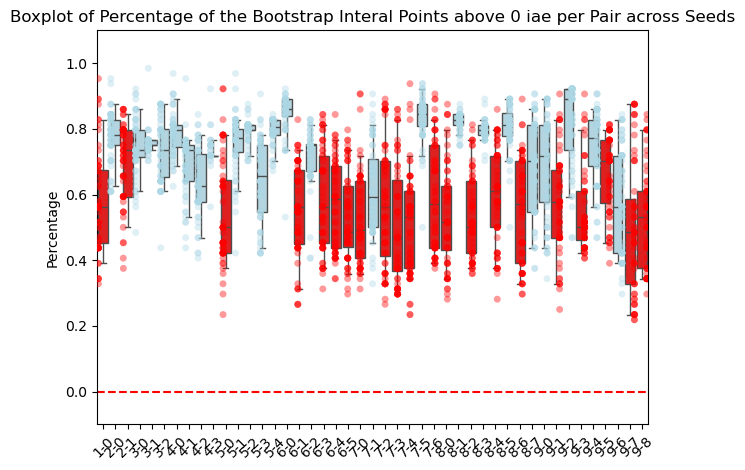

In [34]:
plot_metric_percentage_above_zero_bootstrap_intervals_across_seeds(table_original_dict_no,
                                                                   table_diffs_list_no,
                                                                   df_structure,
                                                                   metric="iae")

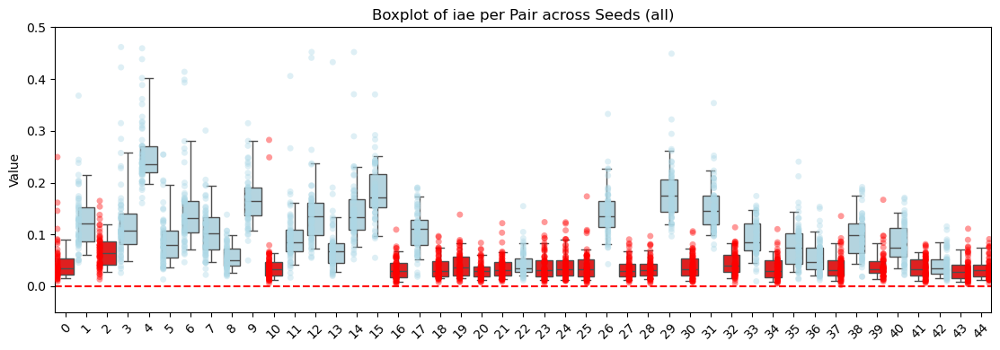

In [35]:
plot_metric_values_across_seeds(table_original_dict_no,df_structure,metric="iae",ylim=(-0.05,0.5))

KeyboardInterrupt: 

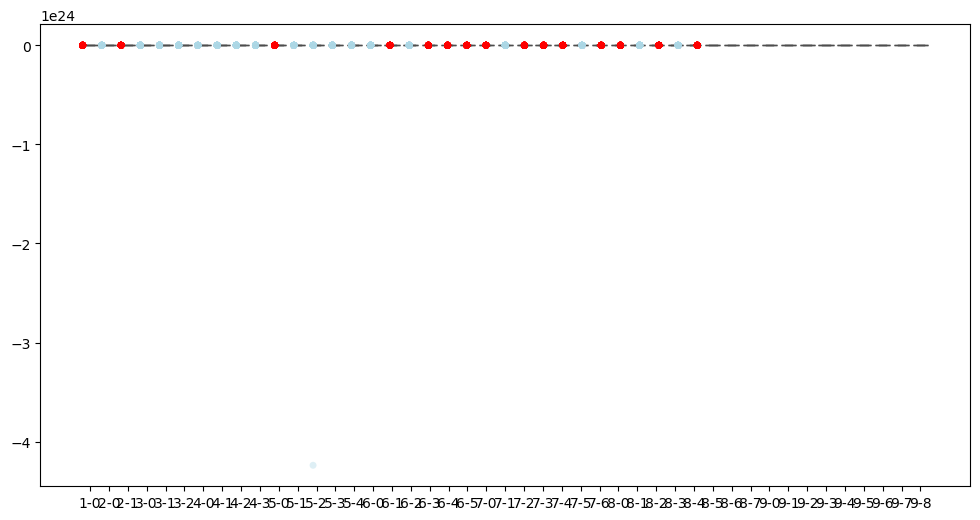

In [36]:
plot_metric_bootstrap_intervals_for_each_seed(table_original_dict_no,table_diffs_list_no,df_structure,metric="iae")

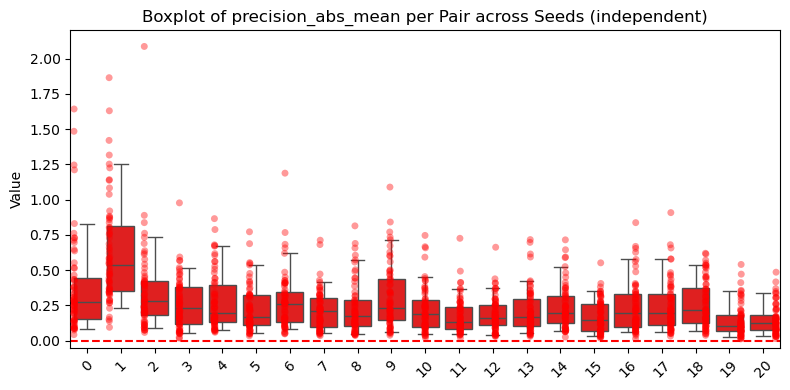

In [ ]:
plot_metric_values_across_seeds(table_original_dict_no,df_structure,metric="precision_abs_mean",ylim=(-0.05,2.2), plot_dependence="independent")

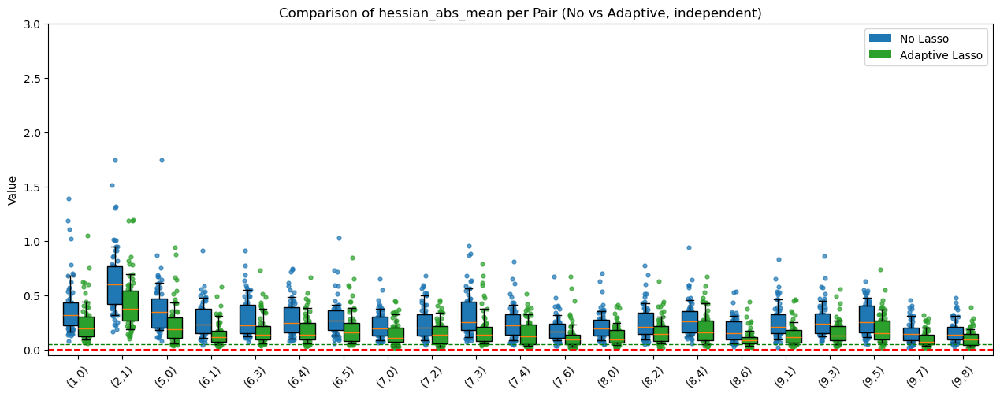

In [ ]:
plot_metric_values_no_vs_adaptive(
table_original_dict_no,
table_original_dict_adaptive,
    df_structure,
    metric='hessian_abs_mean',
    plot_dependence="independent",
    ylim=(-0.05, 3)
)

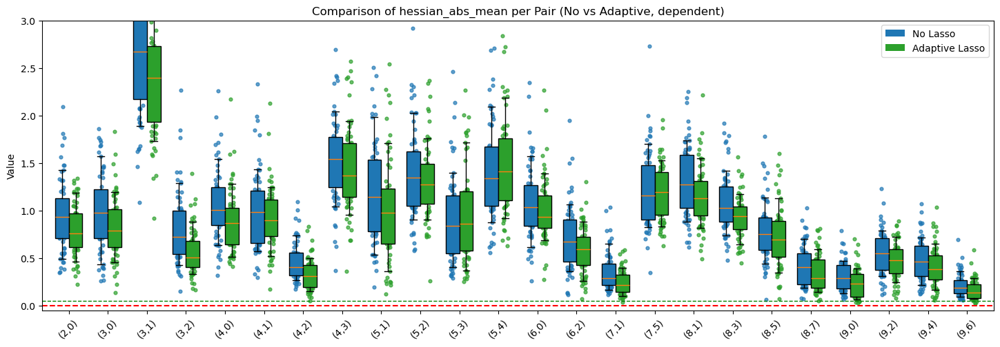

In [ ]:
plot_metric_values_no_vs_adaptive(
table_original_dict_no,
table_original_dict_adaptive,
    df_structure,
    metric='hessian_abs_mean',
    plot_dependence="dependent",
    ylim=(-0.05, 3)
)

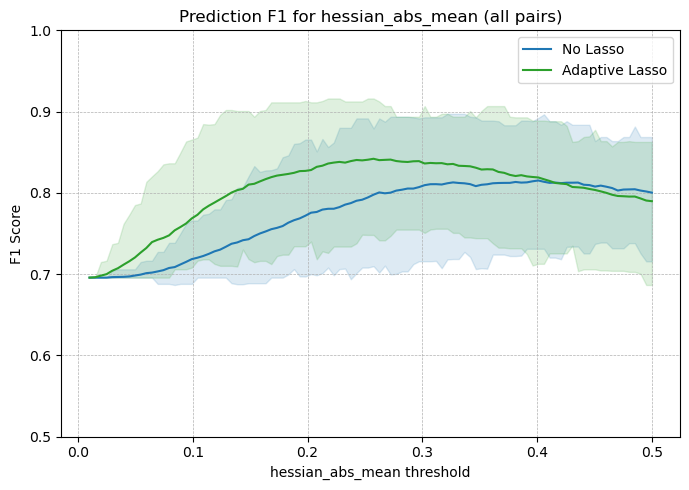

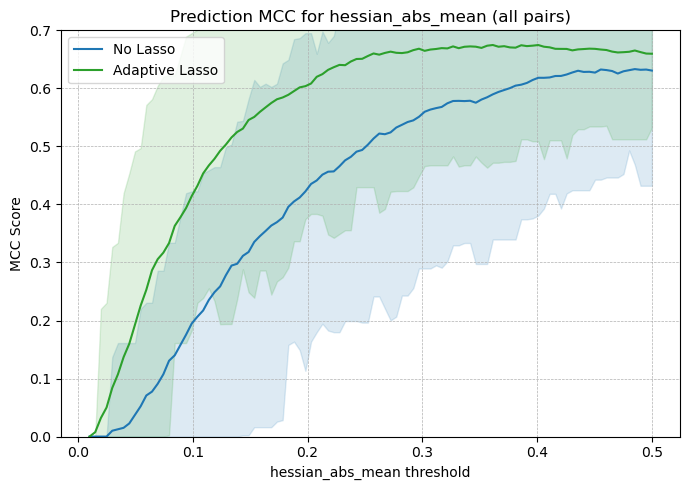

In [ ]:
prdplot_metric_score_vs_threshold(
     table_original_dict_no, table_original_dict_adaptive,
     df_structure, metric="hessian_abs_mean", plot_dependence="all", score_type="f1",
     thresholds=np.linspace(0.01,0.5,100), ylim=(0.5, 1),
)
prdplot_metric_score_vs_threshold(
     table_original_dict_no, table_original_dict_adaptive,
     df_structure, metric="hessian_abs_mean", plot_dependence="all", score_type="mcc",
     thresholds=np.linspace(0.01,0.5,100), ylim=(0., 0.7),
)

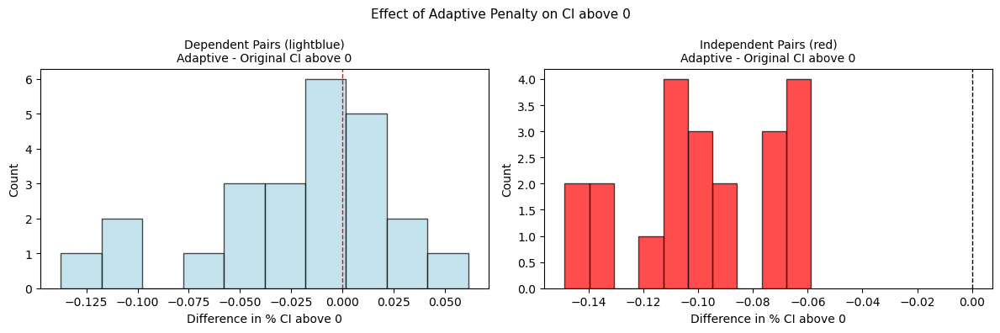

In [ ]:
plot_differences_percentage_bootstrap_intervals_above_zero(table_original_dict_no, table_diffs_list_no,
                                                               df_structure,
                                                               table_original_dict_adaptive, table_diffs_list_adaptive,
                                                               metric="hessian_abs_mean"
                                                               )

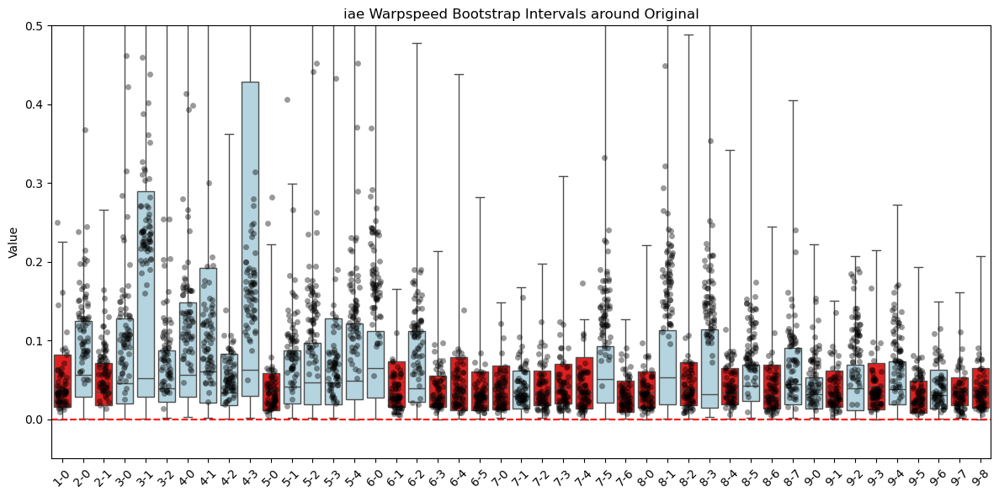

In [ ]:
df_pvalues_no = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_no, table_diffs_list_no, df_structure, metric="iae", ylim=(-0.05, 0.5), n=125)

## What Runs do I even have?

In [ ]:
experiment_name = "rvine_10D_125obs_bootstrap_s0"
mlruns_folder_name = "mlruns_scratch"

# Set Tracking URI Folder
mlflow.set_tracking_uri("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/"+mlruns_folder_name)
    
# Get Experiment Runs
experiment = mlflow.get_experiment_by_name(experiment_name) 
df_runs = mlflow.search_runs([experiment.experiment_id])

# subset only finished runs
df_runs = df_runs[df_runs["end_time"].notna()]

    
# get all no lasso runs and split into bootstrap and origianl data runs
subset_no = df_runs[["No" in df_runs.iloc[i]["tags.mlflow.runName"] for i in range(df_runs.shape[0])]]
subset_no_original = subset_no[["Bootstrap" not in subset_no.iloc[i]["tags.mlflow.runName"] for i in range(subset_no.shape[0])]]
subset_no_bootstrap = subset_no[["Bootstrap" in subset_no.iloc[i]["tags.mlflow.runName"] for i in range(subset_no.shape[0])]]

# get all adaptive lasso runs and split into bootstrap and origianl data runs
subset_adaptive = df_runs[["Adaptive" in df_runs.iloc[i]["tags.mlflow.runName"] for i in range(df_runs.shape[0])]]
subset_adaptive_original = subset_adaptive[["Bootstrap" not in subset_adaptive.iloc[i]["tags.mlflow.runName"] for i in range(subset_adaptive.shape[0])]]
subset_adaptive_bootstrap = subset_adaptive[["Bootstrap" in subset_adaptive.iloc[i]["tags.mlflow.runName"] for i in range(subset_adaptive.shape[0])]]

# find out for which seeds we have all 4, done by seeing for which we have adaptive bootstrap as it is the last we run in simulations
print("No  unique seeds are:", 
      np.sort(np.unique(subset_no_original["tags.seed_value"]).astype(int))
      )
print(len(np.unique(subset_no_original["tags.seed_value"])))

print("No Bootstrap unique seeds are:", 
      np.sort(np.unique(subset_no_bootstrap["tags.seed_value"]).astype(int))
      )
print(len(np.unique(subset_no_bootstrap["tags.seed_value"])))

print("Adaptive unique seeds are:", 
      np.sort(np.unique(subset_adaptive["tags.seed_value"]).astype(int))
      )
print(len(np.unique(subset_adaptive["tags.seed_value"])))

print("Adaptive Bootstrap unique seeds are:", 
      np.sort(np.unique(subset_adaptive_bootstrap["tags.seed_value"]).astype(int))
      )
print(len(np.unique(subset_adaptive_bootstrap["tags.seed_value"])))
    

No  unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 50 51 52 53
 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69]
40
No Bootstrap unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 50 51 52 53
 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69]
40
Adaptive unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 50 51 52 53
 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69]
40
Adaptive Bootstrap unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 50 51 52 53
 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69]
40


In [ ]:
np.sort(np.unique(subset_no_original["tags.seed_value"]).astype(int))

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50,
       51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67,
       68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81])

### Seed Copula 0 
so mostly with the likelihood metrics

In [ ]:
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = "rvine_strong_10D_125obs_bootstrap_s0", 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="R-Vine",
                                                                                                                                              Independence_tree=3)

The unique seeds are: [ 0 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72
 73 74 75 76 77 78 79 80]
There are  32 nmber of unique seeds.


In [ ]:
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = "cvine_strong_10D_125obs_bootstrap_s0", 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="C-Vine",
                                                                                                                                              Independence_tree=3)

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 50
 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74
 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95 96 97 98
 99]
There are  97 nmber of unique seeds.


In [ ]:
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = "dvine_strong_10D_125obs_bootstrap_s0", 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="D-Vine",
                                                                                                                                              Independence_tree=3)

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 50 51 52 53 54 55 56 57 58 59
 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75 76 77 78 79 80 81 82 83
 84 85 86 87 88 89 90 91 92 93 94 95 96 97 98 99]
There are  64 nmber of unique seeds.


#### normal

In [ ]:
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = "rvine_10D_125obs_bootstrap_s0", 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="R-Vine",
                                                                                                                                              Independence_tree=3)

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 50 51 52 53
 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69]
There are  40 nmber of unique seeds.


In [ ]:
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = "cvine_10D_125obs_bootstrap_s0", 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="C-Vine",
                                                                                                                                              Independence_tree=3)

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 50 51 52 53
 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69]
There are  40 nmber of unique seeds.


### Seed Copula 1
no likelihood metrics

In [ ]:
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = "rvine_strong_10D_125obs_bootstrap_s1", 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=1,
                                                                                                                                              vine_type="R-Vine",
                                                                                                                                              Independence_tree=3)

KeyError: 'tags.seed_value'

In [ ]:
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = "cvine_strong_10D_125obs_bootstrap_s1", 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=1,
                                                                                                                                              vine_type="C-Vine",
                                                                                                                                              Independence_tree=3)
# error as there are no adpative bootstrap runs!

KeyError: 'tags.seed_value'

In [ ]:
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = "dvine_strong_10D_125obs_bootstrap_s1", 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=1,
                                                                                                                                              vine_type="D-Vine",
                                                                                                                                              Independence_tree=3)

The unique seeds are: [50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73
 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95 96 97
 98 99]
There are  50 nmber of unique seeds.


#### normal

In [ ]:
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = "rvine_10D_125obs_bootstrap_s1", 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=1,
                                                                                                                                              vine_type="R-Vine",
                                                                                                                                              Independence_tree=3)

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49]
There are  50 nmber of unique seeds.


In [ ]:
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = "cvine_10D_125obs_bootstrap_s1", 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=1,
                                                                                                                                              vine_type="C-Vine",
                                                                                                                                              Independence_tree=3)
# error as there are no adpative bootstrap runs!

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49]
There are  50 nmber of unique seeds.


In [ ]:
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = "dvine_10D_125obs_bootstrap_s1", 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=1,
                                                                                                                                              vine_type="D-Vine",
                                                                                                                                              Independence_tree=3)
# error as there are no adpative bootstrap runs!

KeyError: 'tags.seed_value'

### Seed 2 Copula

In [ ]:
experiment_name = "rvine_10D_125obs_bootstrap_s2"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="R-Vine",
                                                                                                                                              Independence_tree=3)

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
There are  100 nmber of unique seeds.


In [ ]:
experiment_name = "rvine_10D_125obs_bootstrap_s3"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="R-Vine",
                                                                                                                                              Independence_tree=3)

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
There are  100 nmber of unique seeds.


In [ ]:
experiment_name = "rvine_strong_10D_125obs_bootstrap_s2"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="R-Vine",
                                                                                                                                              Independence_tree=3)

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
There are  100 nmber of unique seeds.


In [ ]:
experiment_name = "rvine_strong_10D_125obs_bootstrap_s3"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="R-Vine",
                                                                                                                                              Independence_tree=3)

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [  0   1   2   3   4   5   6   7   8  10  11  12  13  14  15  16  17  18
  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36
  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54
  55  56  57  58  59  60  61  62  63  64  65  66  67  68  70  71  72  73
  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90  91
  92  93  94  95  96  97  98  99 100 101]
There are  100 nmber of unique seeds.


In [ ]:
experiment_name = "dvine_10D_125obs_bootstrap_s2"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="D-Vine",
                                                                                                                                              Independence_tree=3)

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
There are  100 nmber of unique seeds.


In [ ]:
experiment_name = "dvine_10D_125obs_bootstrap_s3"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="D-Vine",
                                                                                                                                              Independence_tree=3)

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
There are  100 nmber of unique seeds.


In [ ]:
experiment_name = "dvine_strong_10D_125obs_bootstrap_s2"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="D-Vine",
                                                                                                                                              Independence_tree=3)

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90
  91  92  93  94  95  96  97  98  99 100]
There are  100 nmber of unique seeds.


In [ ]:
experiment_name = "dvine_strong_10D_125obs_bootstrap_s3"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="D-Vine",
                                                                                                                                              Independence_tree=3)

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
There are  100 nmber of unique seeds.


In [ ]:
experiment_name = "cvine_10D_125obs_bootstrap_s2"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="C-Vine",
                                                                                                                                              Independence_tree=3)

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
There are  100 nmber of unique seeds.


In [ ]:
experiment_name = "cvine_10D_125obs_bootstrap_s3"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="C-Vine",
                                                                                                                                              Independence_tree=3)

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
There are  100 nmber of unique seeds.


In [ ]:
experiment_name = "cvine_strong_10D_125obs_bootstrap_s2"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="C-Vine",
                                                                                                                                              Independence_tree=3)

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
There are  100 nmber of unique seeds.


In [ ]:
experiment_name = "cvine_strong_10D_125obs_bootstrap_s3"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="C-Vine",
                                                                                                                                              Independence_tree=3)

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
There are  100 nmber of unique seeds.


## Analysis of Experiments

#### Seed 0 D-Vine Strong

In [ ]:
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = "dvine_strong_10D_125obs_bootstrap_s0", 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="D-Vine",
                                                                                                                                              Independence_tree=3)

table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(subset_no_original, subset_no_bootstrap,
                                                                        data="synthetic")

table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(subset_adaptive_original, subset_adaptive_bootstrap,
                                                                        data="synthetic")

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 50 51 52 53 54 55 56 57 58 59
 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75 76 77 78 79 80 81 82 83
 84 85 86 87 88 89 90 91 92 93 94 95 96 97 98 99]
There are  64 nmber of unique seeds.


Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


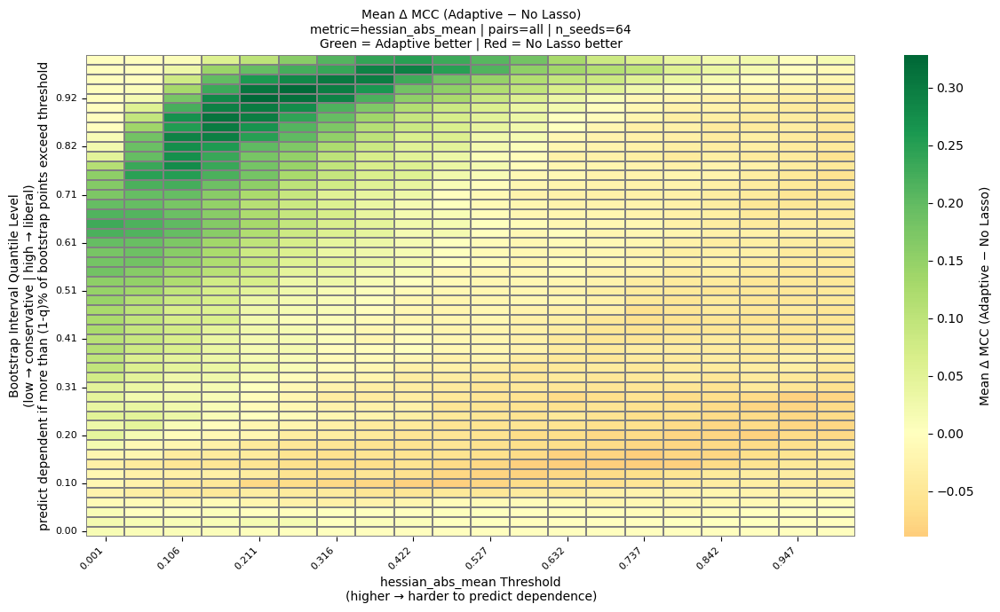

In [ ]:
_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
)

Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


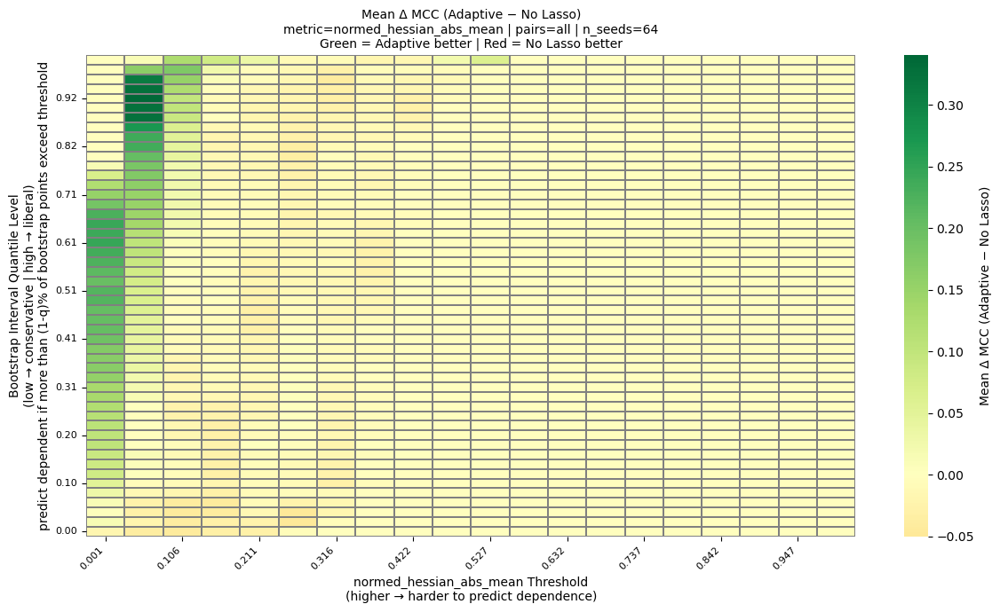

In [ ]:
_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
)

Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


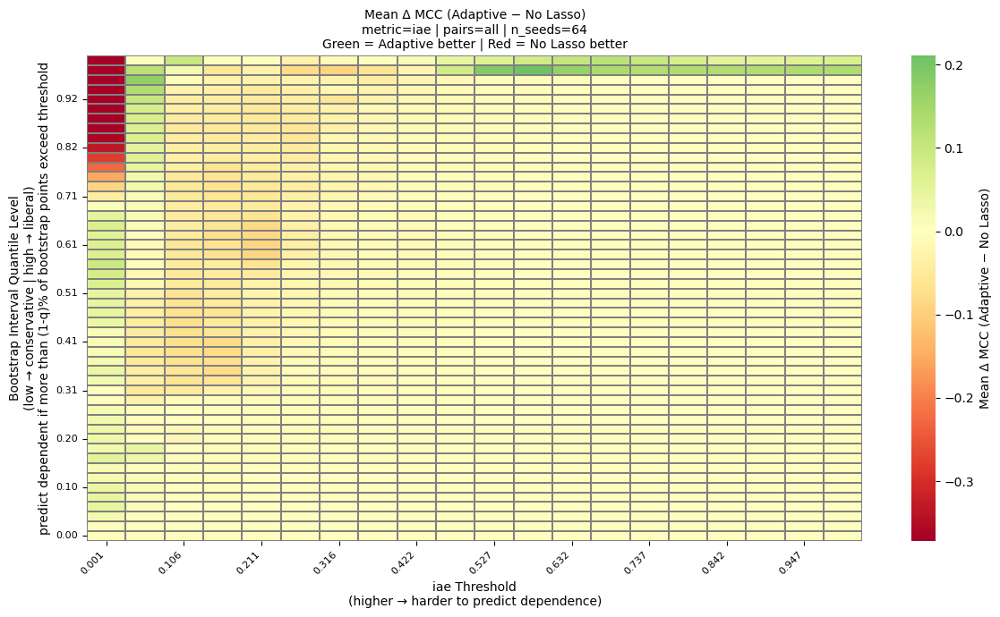

In [ ]:
_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="iae",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
)

##### hessian_abs_mean

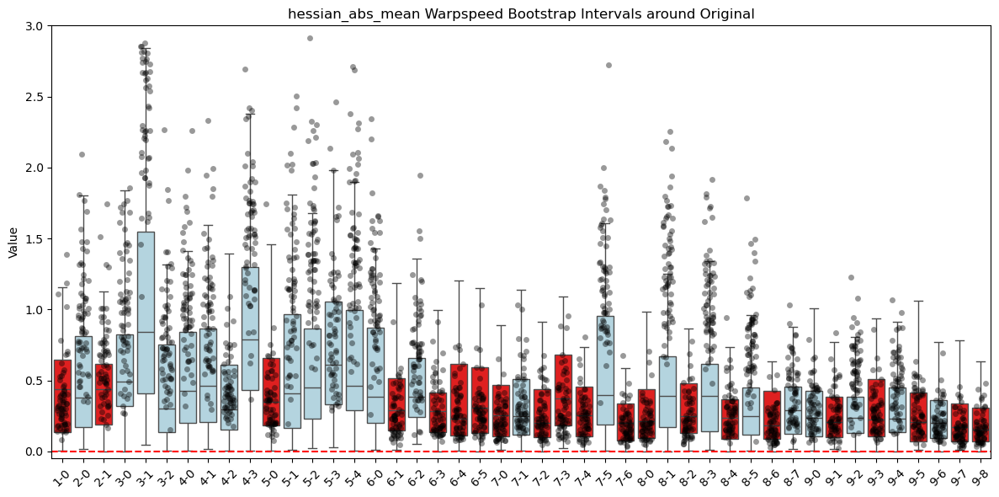

In [ ]:
df_pvalues_no = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_no, table_diffs_list_no, df_structure, metric="hessian_abs_mean", ylim=(-0.05, 3), n=125)

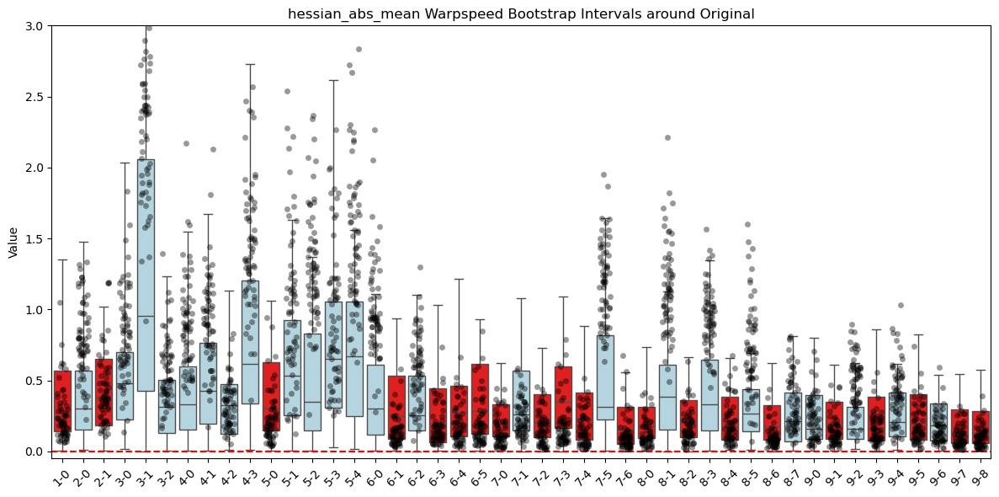

In [ ]:
df_pvalues_adaptive = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_adaptive, table_diffs_list_adaptive, df_structure, metric="hessian_abs_mean", ylim=(-0.05, 3), n=125)

P-value Differences: Adaptive - No Penalty
Metric: — MyMetric
Dependent   pairs | mean diff: -0.0218  (n=1536)
Independent pairs | mean diff: +0.1263  (n=1344)


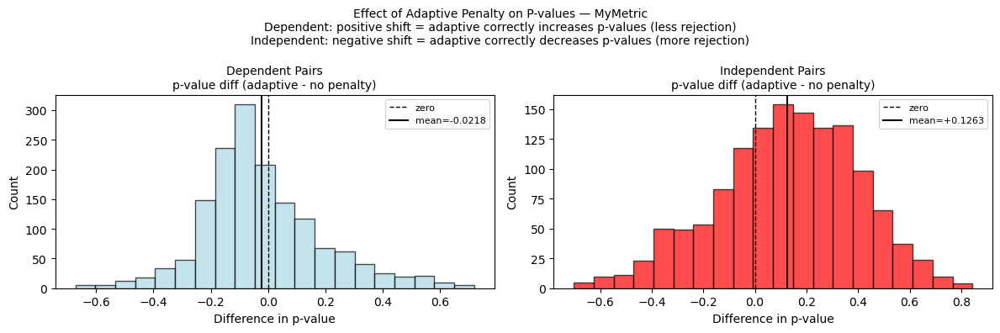

         group  dependence  mean_diff     n  pct_positive  pct_negative
0    dependent           1  -0.021820  1536      0.367188      0.602214
1  independent           0   0.126256  1344      0.686012      0.298363


In [ ]:
# --- Usage ---
df_summary = plot_pvalue_differences(
    df_pvalues_adaptive, 
    df_pvalues_no, 
    title_suffix="— MyMetric"
)
print(df_summary)

##### normed_hessian_abs_mean

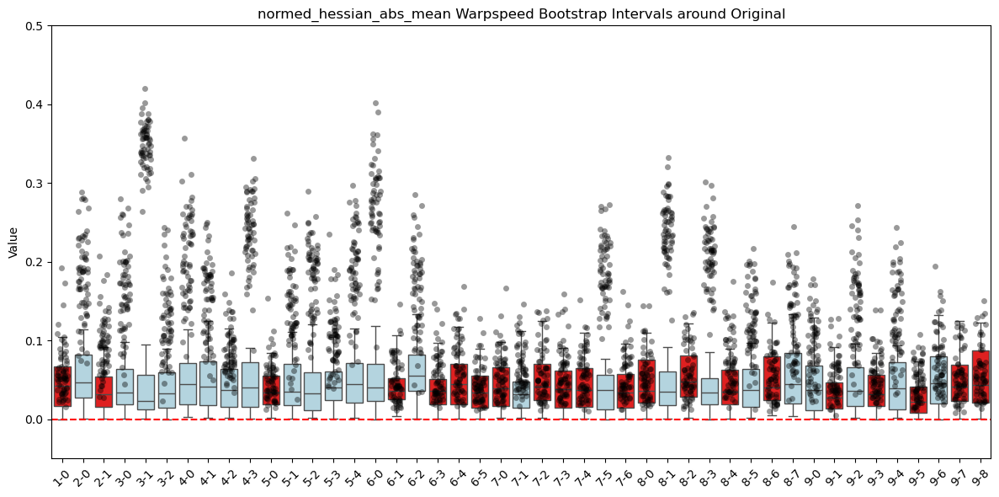

In [ ]:
df_pvalues_no = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_no, table_diffs_list_no, df_structure, metric="normed_hessian_abs_mean", ylim=(-0.05, 0.5), n=125)

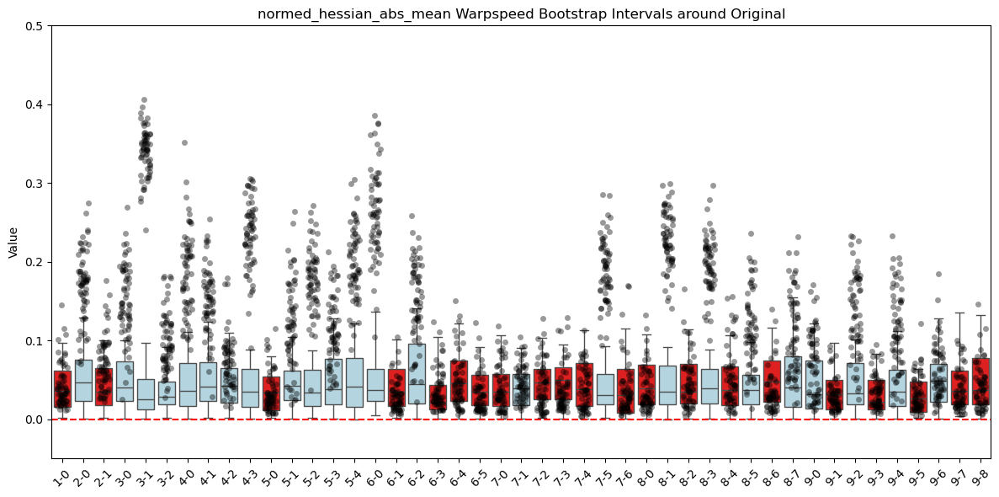

In [ ]:
df_pvalues_adaptive = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_adaptive, table_diffs_list_adaptive, df_structure, metric="normed_hessian_abs_mean", ylim=(-0.05, 0.5), n=125)

P-value Differences: Adaptive - No Penalty
Metric: — MyMetric
Dependent   pairs | mean diff: +0.0324  (n=1536)
Independent pairs | mean diff: +0.1539  (n=1344)


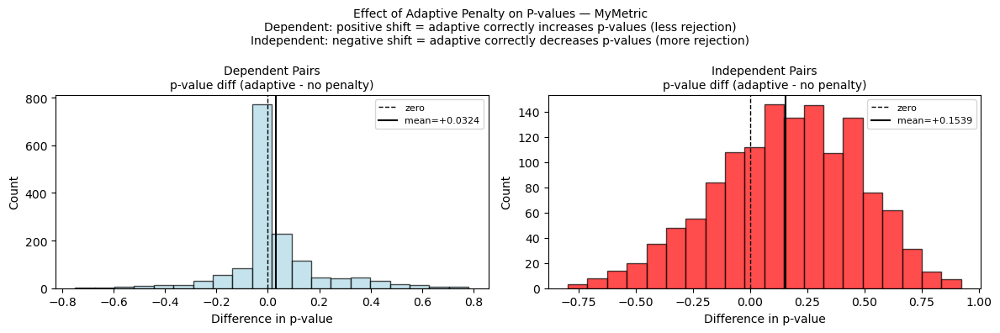

         group  dependence  mean_diff     n  pct_positive  pct_negative
0    dependent           1   0.032420  1536      0.356120      0.237630
1  independent           0   0.153902  1344      0.690476      0.291667


In [ ]:
# --- Usage ---
df_summary = plot_pvalue_differences(
    df_pvalues_adaptive, 
    df_pvalues_no, 
    title_suffix="— MyMetric"
)
print(df_summary)

##### iae

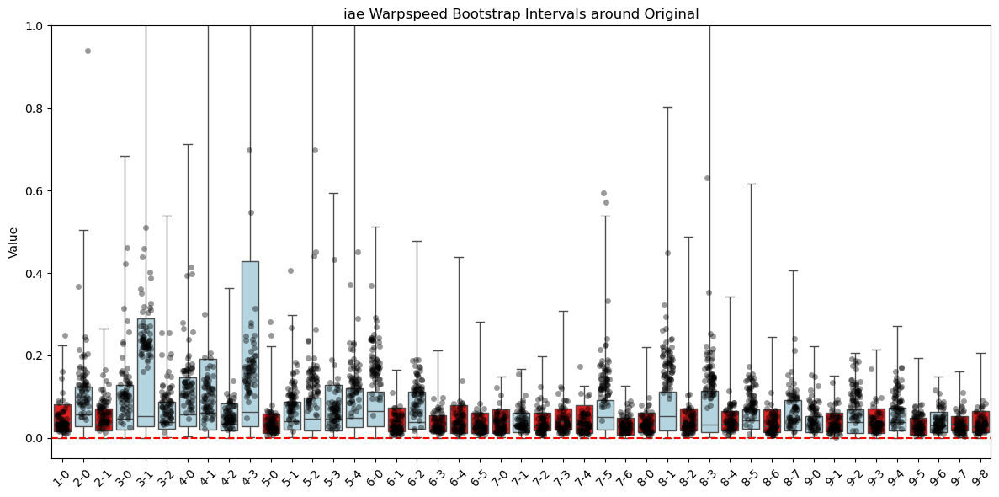

In [ ]:
df_pvalues_no = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_no, table_diffs_list_no, df_structure, metric="iae", ylim=(-0.05, 1), n=125)

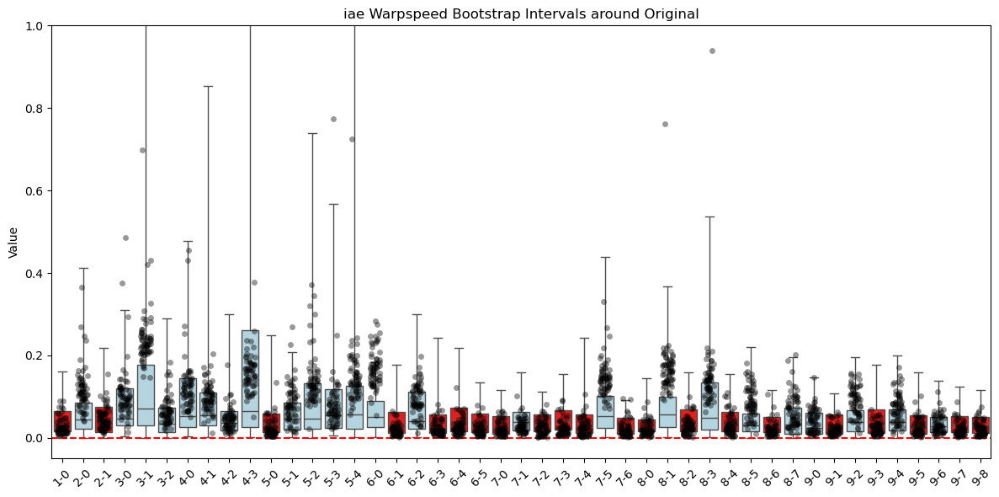

In [ ]:
df_pvalues_adaptive = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_adaptive, table_diffs_list_adaptive, df_structure, metric="iae", ylim=(-0.05, 1), n=125)

P-value Differences: Adaptive - No Penalty
Metric: — MyMetric
Dependent   pairs | mean diff: +0.0161  (n=1536)
Independent pairs | mean diff: +0.1241  (n=1344)


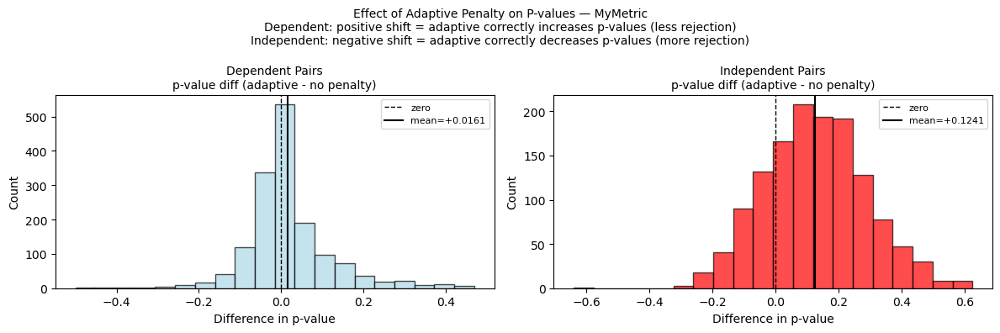

         group  dependence  mean_diff     n  pct_positive  pct_negative
0    dependent           1   0.016083  1536      0.471354      0.444661
1  independent           0   0.124128  1344      0.757440      0.212054


In [ ]:
# --- Usage ---
df_summary = plot_pvalue_differences(
    df_pvalues_adaptive, 
    df_pvalues_no, 
    title_suffix="— MyMetric"
)
print(df_summary)

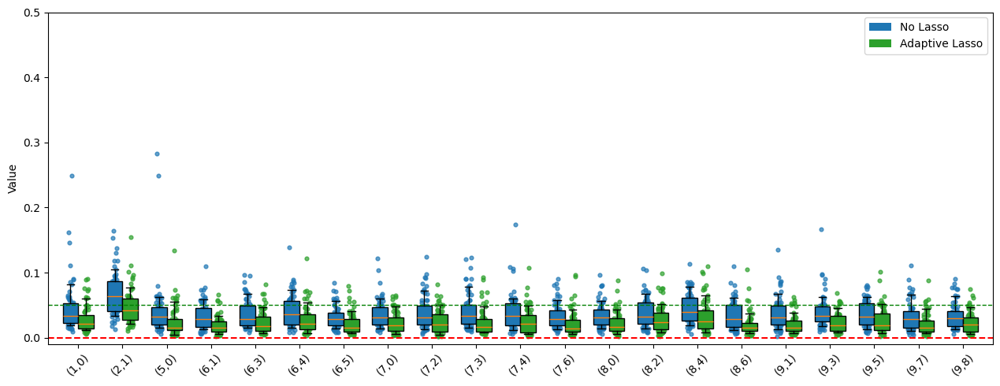

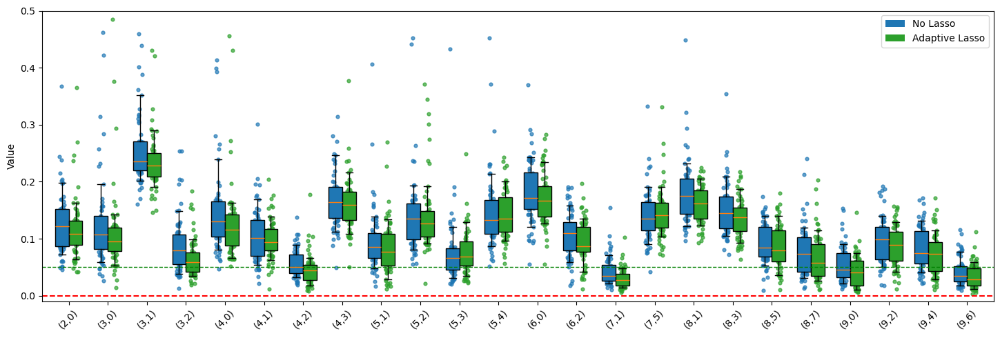

In [ ]:
plot_metric_values_no_vs_adaptive(
table_original_dict_no,
table_original_dict_adaptive,
    df_structure,
    metric='iae',
    plot_dependence="independent",
    ylim=(-0.01, 0.5),
    plot_title=False,
    threshold=0.05
)

plot_metric_values_no_vs_adaptive(
table_original_dict_no,
table_original_dict_adaptive,
    df_structure,
    metric='iae',
    plot_dependence="dependent",
    ylim=(-0.01, 0.5),
    plot_title=False,
    threshold=0.05
)

#### Seed 0 C-Vine Strong

In [ ]:
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = "cvine_strong_10D_125obs_bootstrap_s0", 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="C-Vine",
                                                                                                                                              Independence_tree=3)

table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(subset_no_original, subset_no_bootstrap,
                                                                        data="synthetic")

table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(subset_adaptive_original, subset_adaptive_bootstrap,
                                                                        data="synthetic")

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 50
 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74
 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95 96 97 98
 99]
There are  97 nmber of unique seeds.


Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


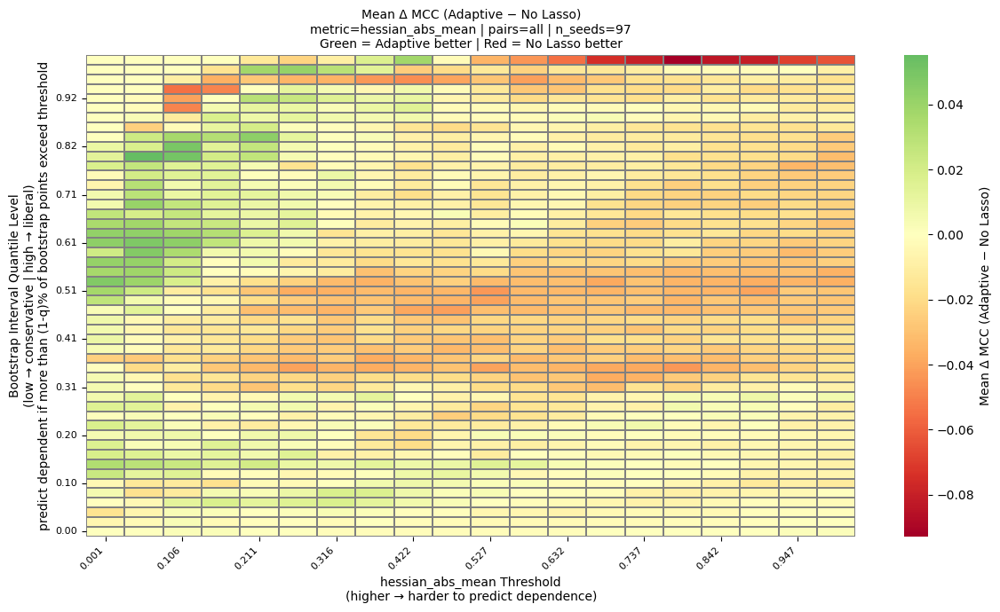

In [ ]:
_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
)

Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


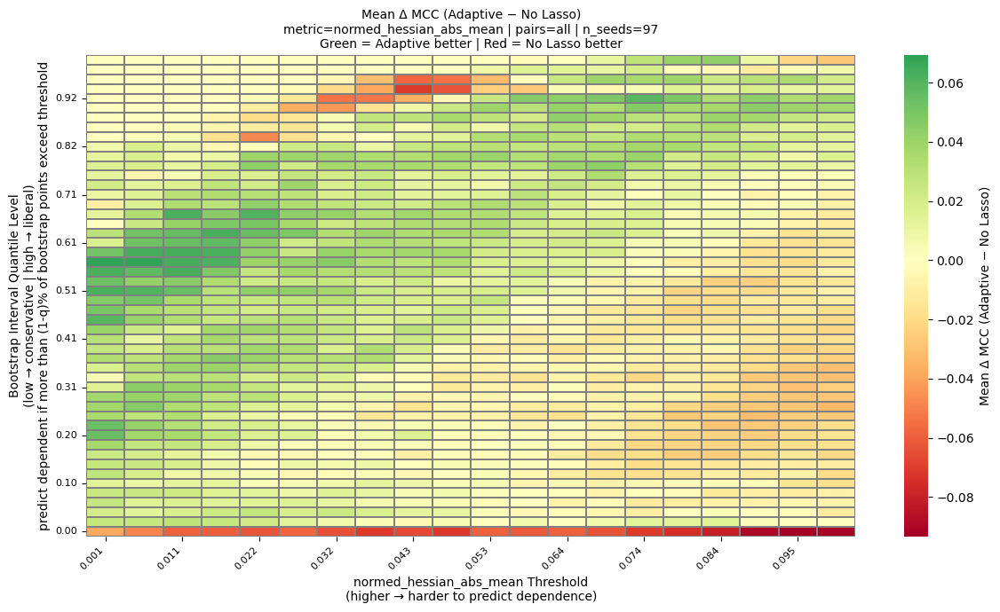

In [ ]:
_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
)

Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


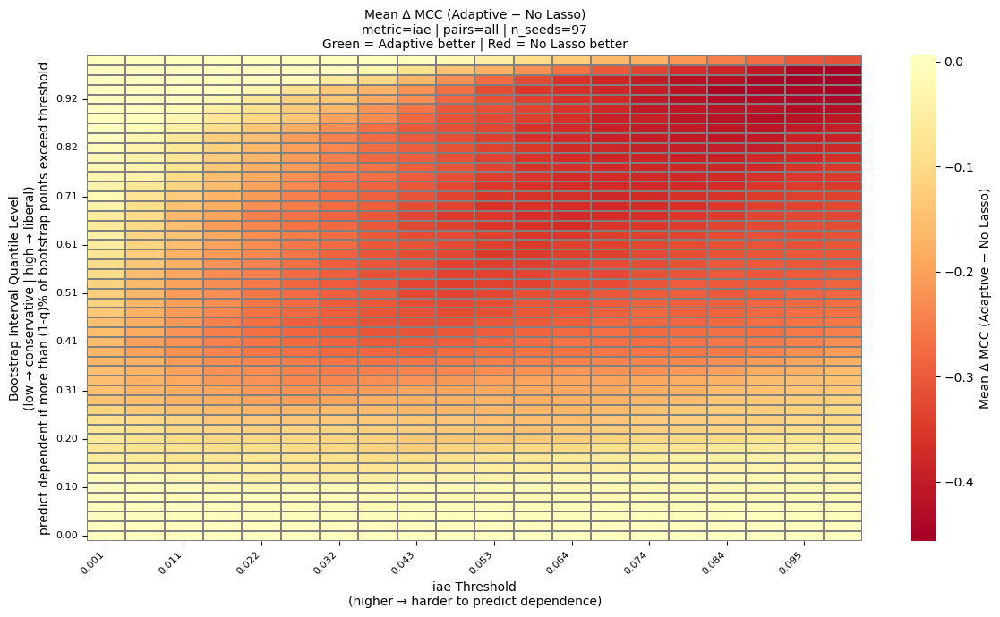

In [ ]:
_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="iae",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
)

##### hessian_abs_mean

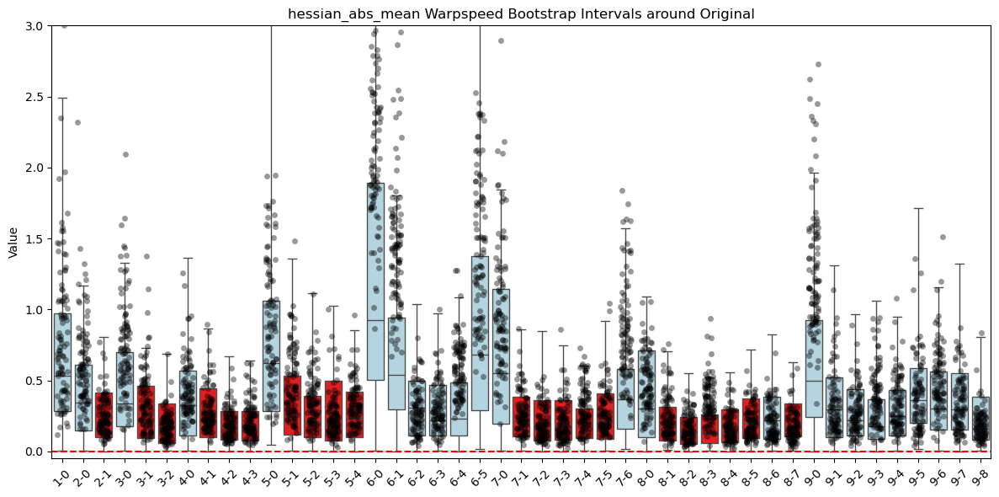

In [ ]:
df_pvalues_no = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_no, table_diffs_list_no, df_structure, metric="hessian_abs_mean", ylim=(-0.05, 3), n=125)

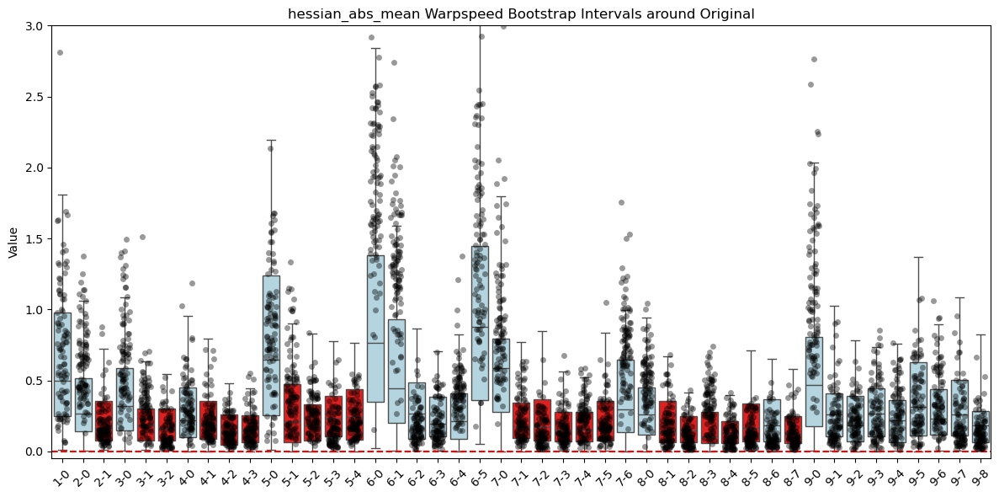

In [ ]:
df_pvalues_adaptive = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_adaptive, table_diffs_list_adaptive, df_structure, metric="hessian_abs_mean", ylim=(-0.05, 3), n=125)

P-value Differences: Adaptive - No Penalty
Metric: — MyMetric
Dependent   pairs | mean diff: +0.0345  (n=2328)
Independent pairs | mean diff: +0.0587  (n=2037)


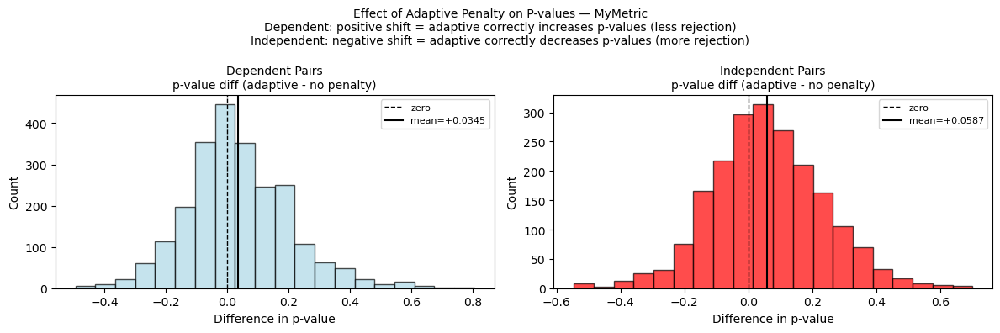

         group  dependence  mean_diff     n  pct_positive  pct_negative
0    dependent           1   0.034541  2328      0.544674      0.420962
1  independent           0   0.058733  2037      0.618066      0.351497


In [ ]:
# --- Usage ---
df_summary = plot_pvalue_differences(
    df_pvalues_adaptive, 
    df_pvalues_no, 
    title_suffix="— MyMetric"
)
print(df_summary)

##### normed_hessian_abs_mean

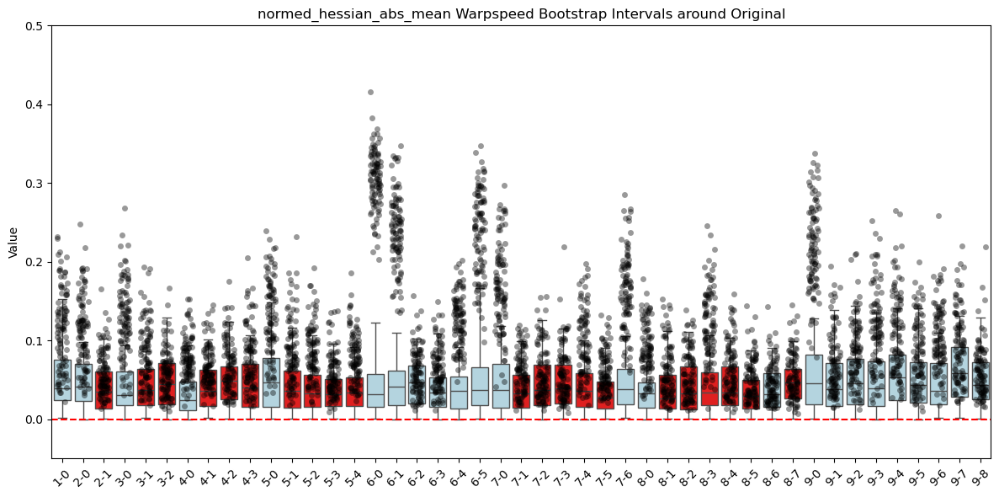

In [ ]:
df_pvalues_no = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_no, table_diffs_list_no, df_structure, metric="normed_hessian_abs_mean", ylim=(-0.05, 0.5), n=125)

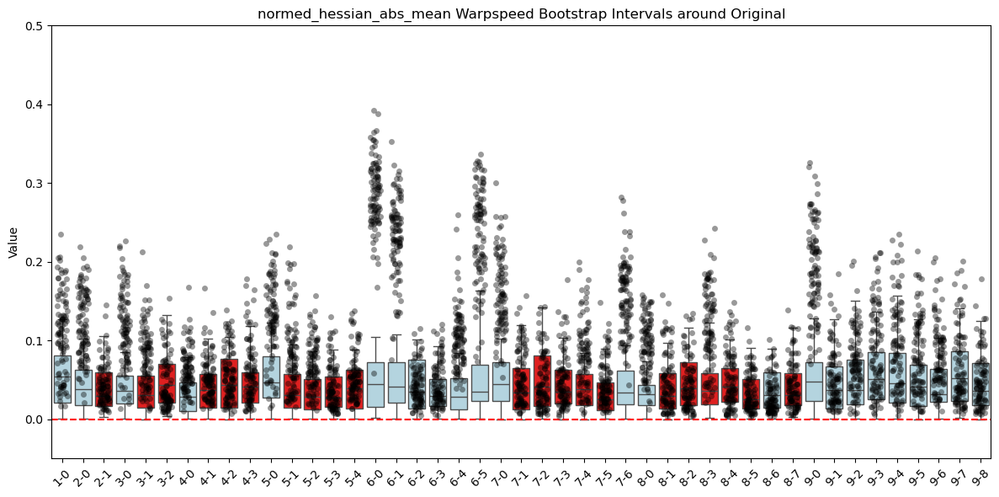

In [ ]:
df_pvalues_adaptive = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_adaptive, table_diffs_list_adaptive, df_structure, metric="normed_hessian_abs_mean", ylim=(-0.05, 0.5), n=125)

P-value Differences: Adaptive - No Penalty
Metric: — MyMetric
Dependent   pairs | mean diff: +0.0585  (n=2328)
Independent pairs | mean diff: +0.1005  (n=2037)


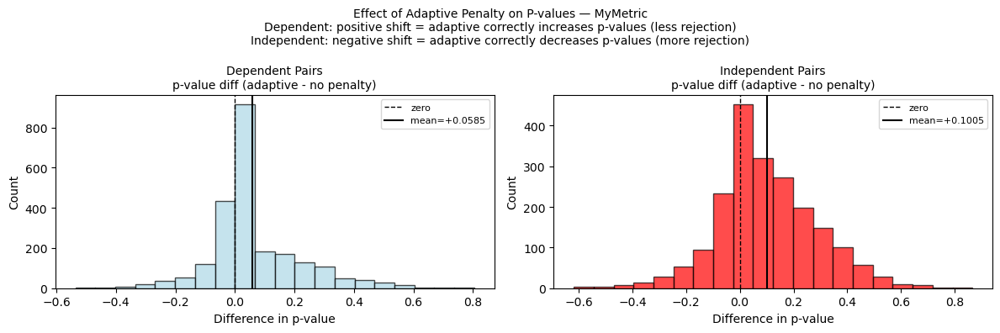

         group  dependence  mean_diff     n  pct_positive  pct_negative
0    dependent           1   0.058486  2328      0.500859      0.289948
1  independent           0   0.100517  2037      0.676485      0.270005


In [ ]:
# --- Usage ---
df_summary = plot_pvalue_differences(
    df_pvalues_adaptive, 
    df_pvalues_no, 
    title_suffix="— MyMetric"
)
print(df_summary)

##### iae

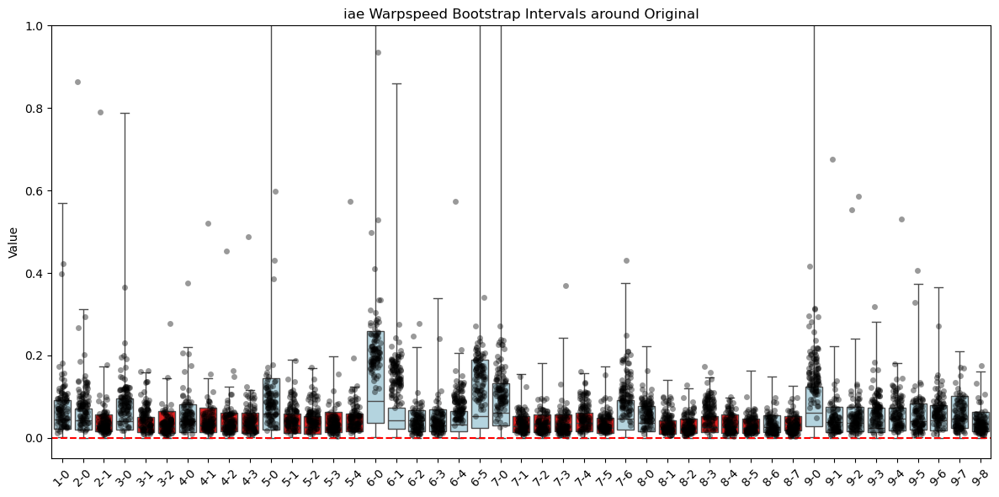

In [ ]:
df_pvalues_no = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_no, table_diffs_list_no, df_structure, metric="iae", ylim=(-0.05, 1), n=125)

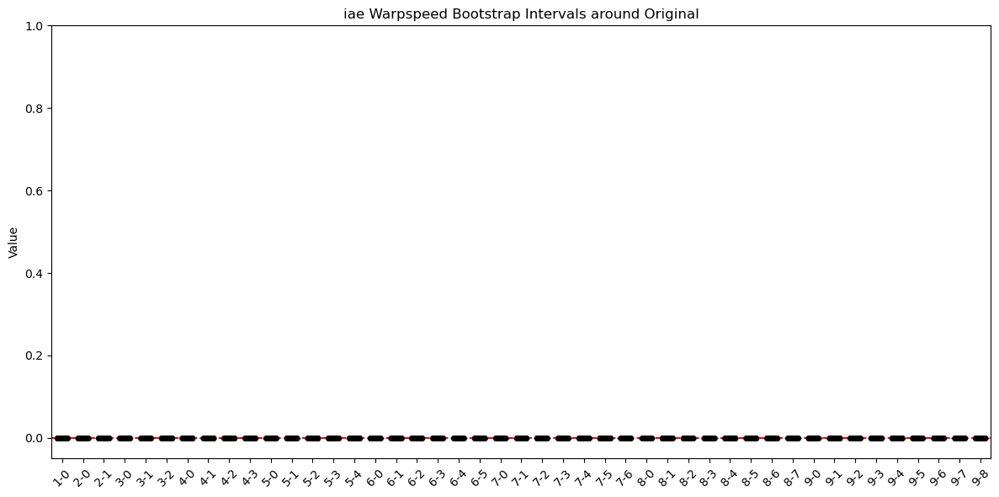

In [ ]:
df_pvalues_adaptive = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_adaptive, table_diffs_list_adaptive, df_structure, metric="iae", ylim=(-0.05, 1), n=125)

P-value Differences: Adaptive - No Penalty
Metric: — MyMetric
Dependent   pairs | mean diff: +0.6278  (n=2328)
Independent pairs | mean diff: +0.5724  (n=2037)


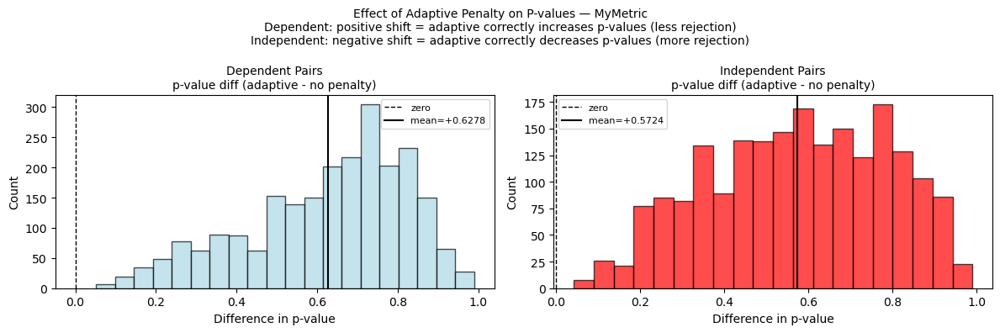

         group  dependence  mean_diff     n  pct_positive  pct_negative
0    dependent           1   0.627759  2328           1.0           0.0
1  independent           0   0.572436  2037           1.0           0.0


In [ ]:
# --- Usage ---
df_summary = plot_pvalue_differences(
    df_pvalues_adaptive, 
    df_pvalues_no, 
    title_suffix="— MyMetric"
)
print(df_summary)

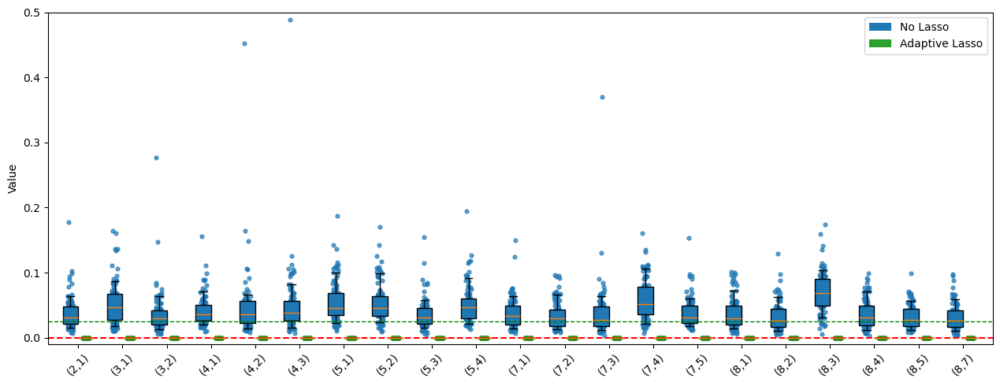

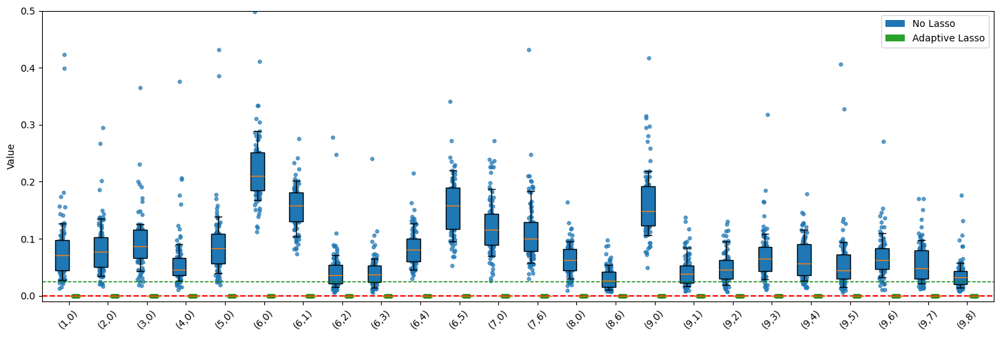

In [ ]:
plot_metric_values_no_vs_adaptive(
table_original_dict_no,
table_original_dict_adaptive,
    df_structure,
    metric='iae',
    plot_dependence="independent",
    ylim=(-0.01, 0.5),
    plot_title=False,
    threshold=0.025
)

plot_metric_values_no_vs_adaptive(
table_original_dict_no,
table_original_dict_adaptive,
    df_structure,
    metric='iae',
    plot_dependence="dependent",
    ylim=(-0.01, 0.5),
    plot_title=False,
    threshold=0.025
)

#### Seed 0 R-Vine Strong

In [ ]:
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = "rvine_strong_10D_125obs_bootstrap_s0", 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="R-Vine",
                                                                                                                                              Independence_tree=3)

table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(subset_no_original, subset_no_bootstrap,
                                                                        data="synthetic")

table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(subset_adaptive_original, subset_adaptive_bootstrap,
                                                                        data="synthetic")

The unique seeds are: [ 0 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72
 73 74 75 76 77 78 79 80]
There are  32 nmber of unique seeds.


Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


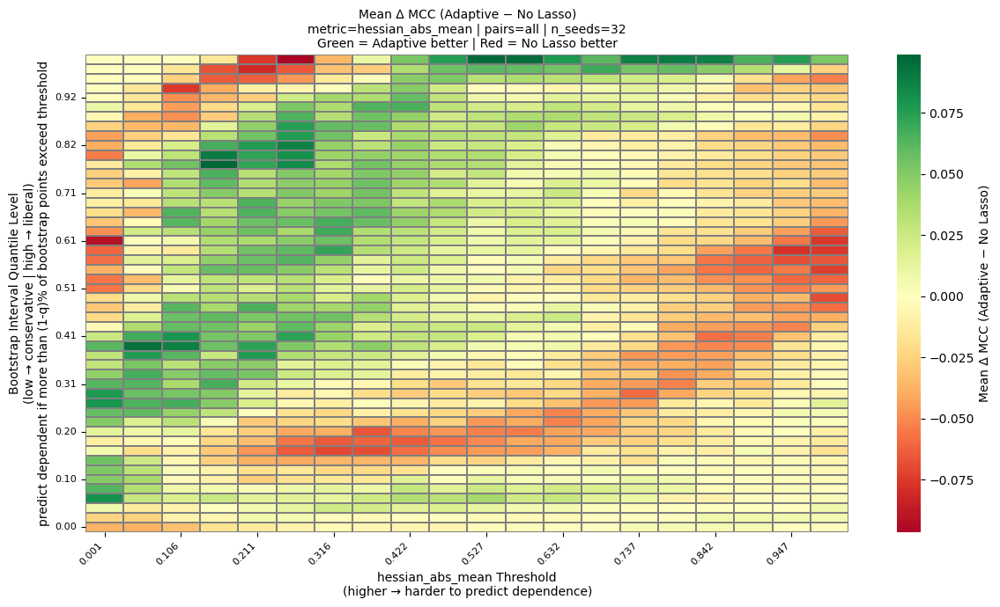

In [ ]:
_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
)

Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


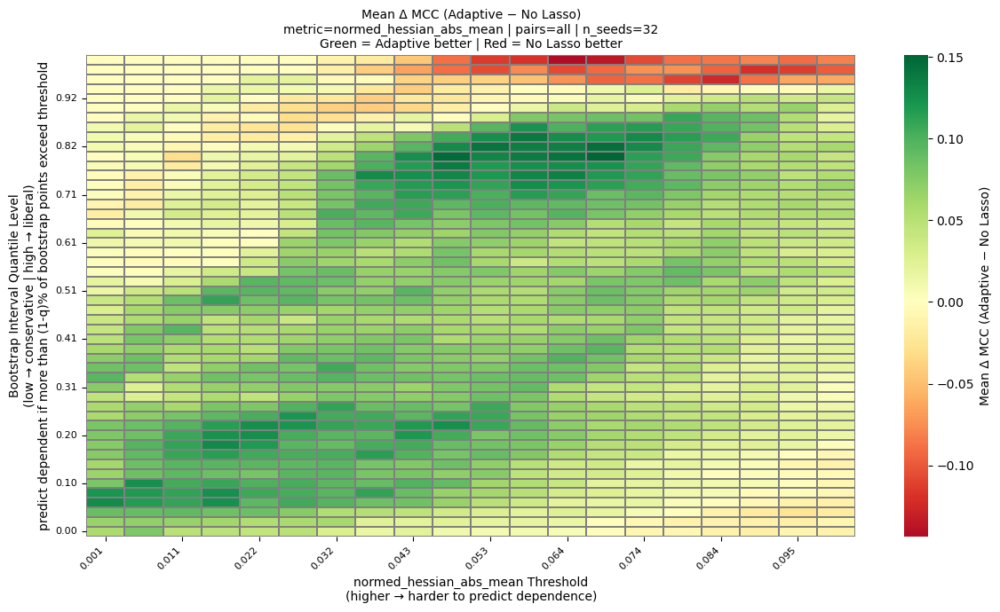

In [ ]:
_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
)

Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


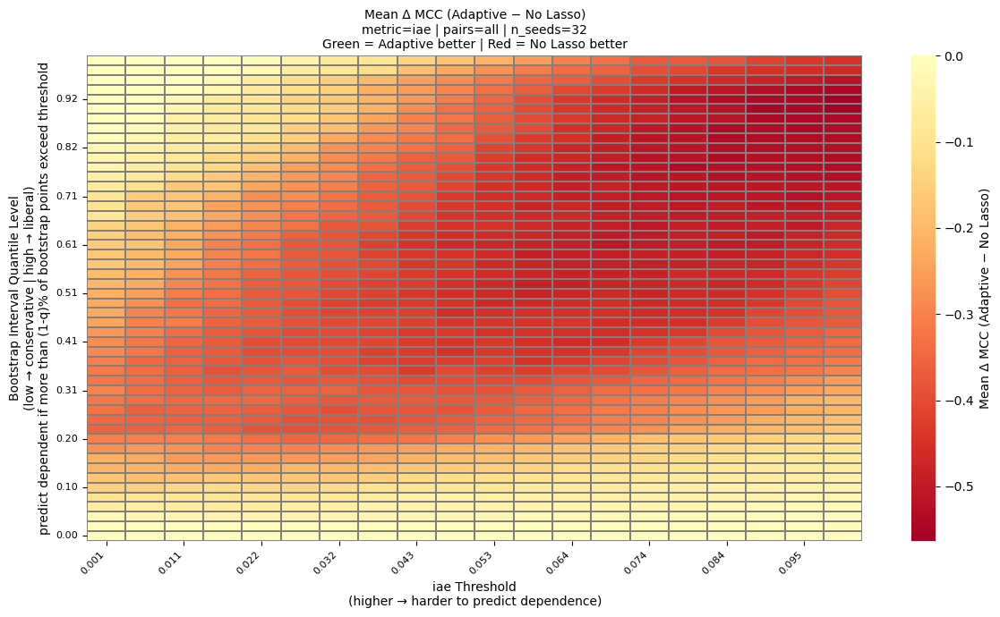

In [ ]:
_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="iae",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
)

#### Seed 0 R-Vine

In [ ]:
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = "rvine_10D_125obs_bootstrap_s0", 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="R-Vine",
                                                                                                                                              Independence_tree=3)

table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(subset_no_original, subset_no_bootstrap,
                                                                        data="synthetic")

table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(subset_adaptive_original, subset_adaptive_bootstrap,
                                                                        data="synthetic")

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 50 51 52 53
 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69]
There are  40 nmber of unique seeds.


Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


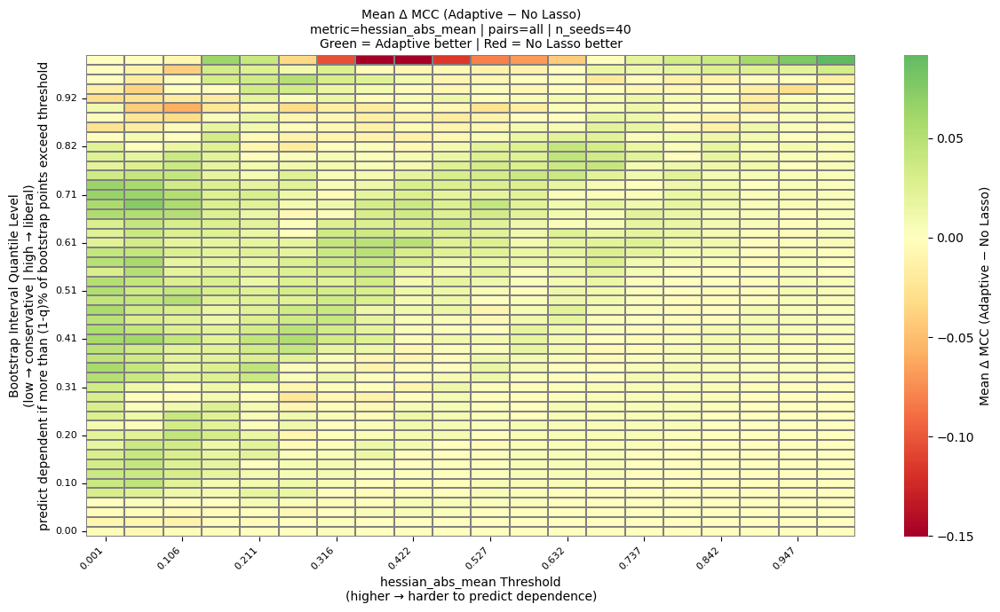

In [ ]:
_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
)

Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


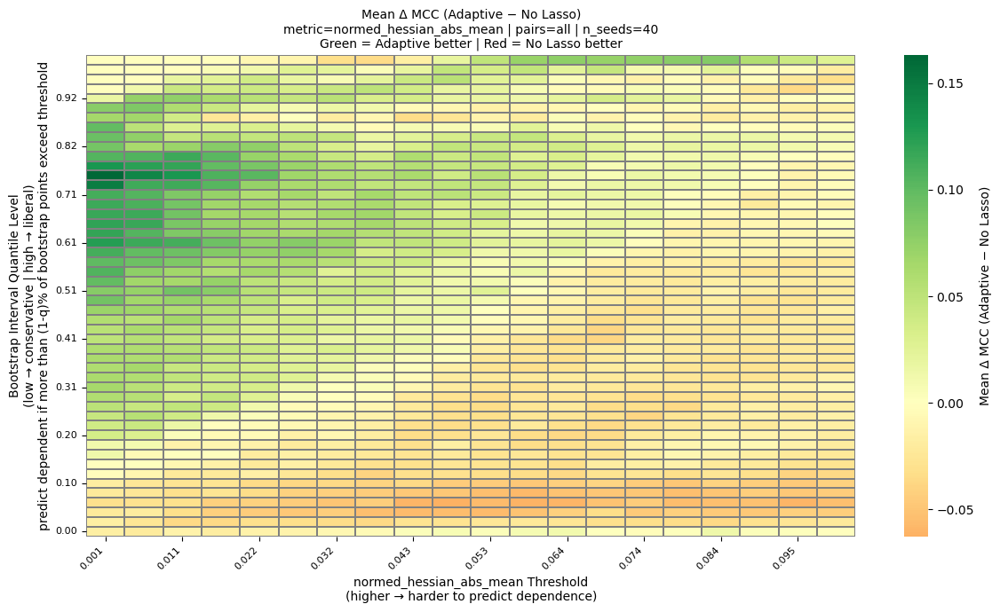

In [ ]:
_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
)

Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


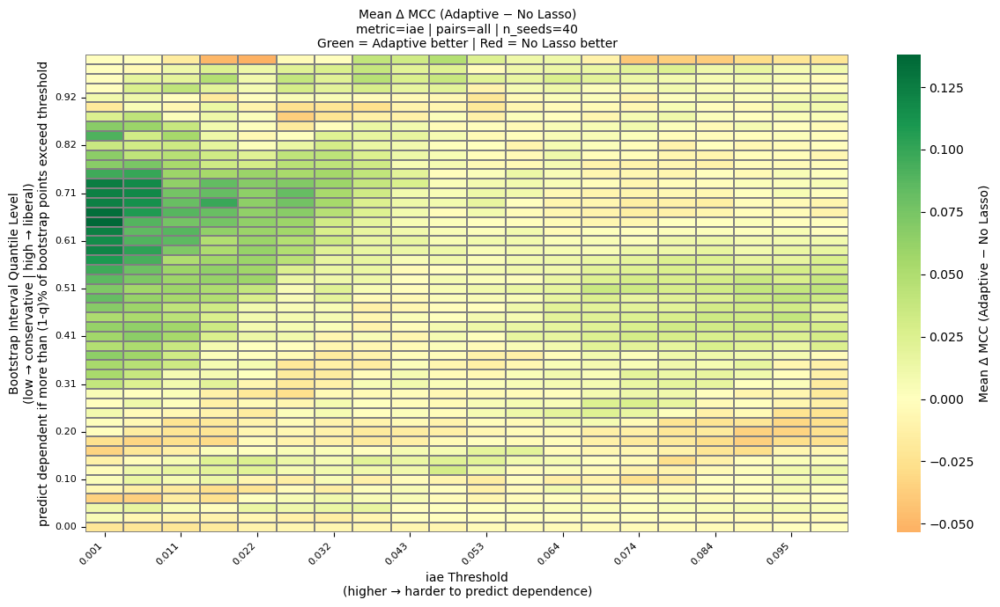

In [ ]:
_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="iae",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
)

##### hessian_abs_mean

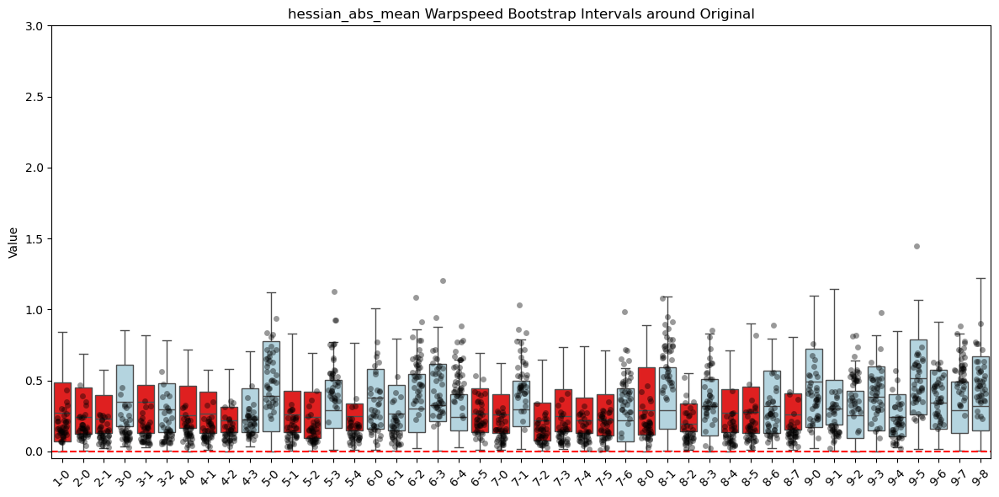

In [ ]:
df_pvalues_no = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_no, table_diffs_list_no, df_structure, metric="hessian_abs_mean", ylim=(-0.05, 3), n=125)

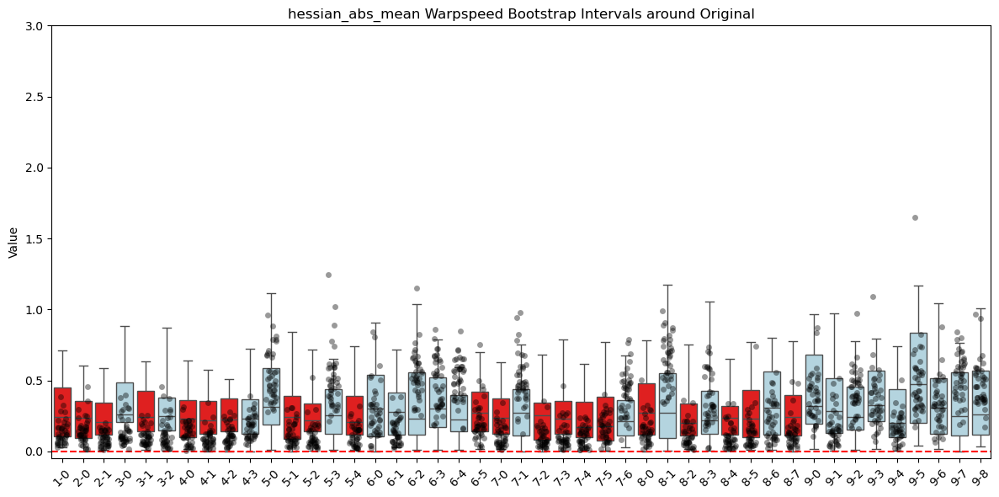

In [ ]:
df_pvalues_adaptive = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_adaptive, table_diffs_list_adaptive, df_structure, metric="hessian_abs_mean", ylim=(-0.05, 3), n=125)

P-value Differences: Adaptive - No Penalty
Metric: — MyMetric
Dependent   pairs | mean diff: -0.0034  (n=960)
Independent pairs | mean diff: +0.0346  (n=840)


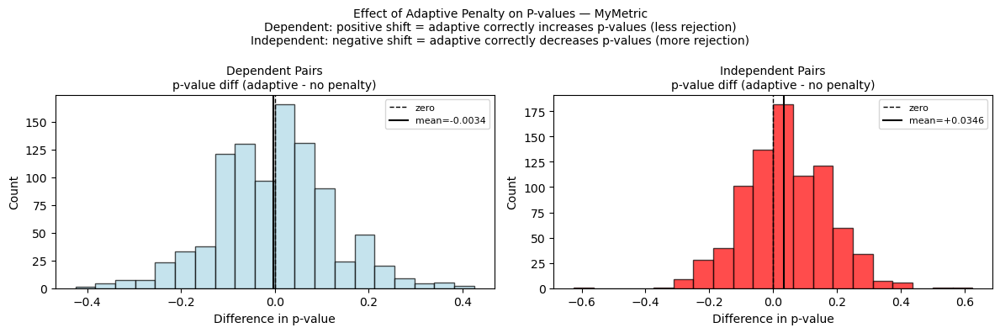

         group  dependence  mean_diff    n  pct_positive  pct_negative
0    dependent           1  -0.003438  960      0.438542      0.480208
1  independent           0   0.034583  840      0.560714      0.377381


In [ ]:
# --- Usage ---
df_summary = plot_pvalue_differences(
    df_pvalues_adaptive, 
    df_pvalues_no, 
    title_suffix="— MyMetric"
)
print(df_summary)

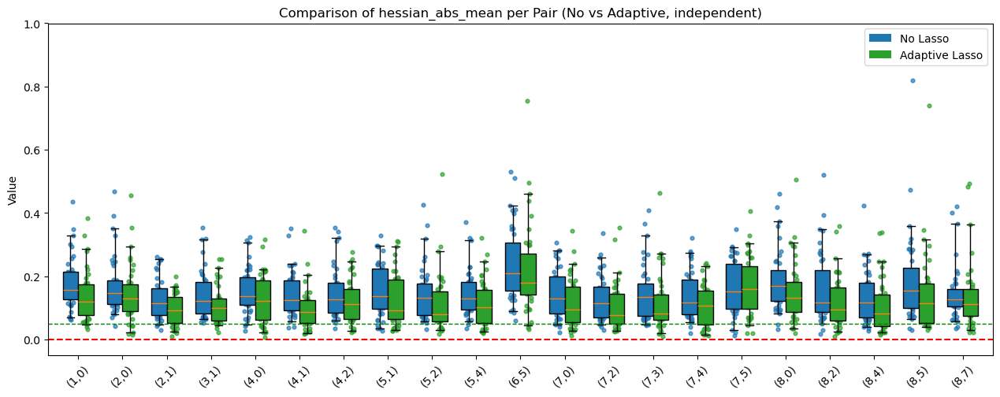

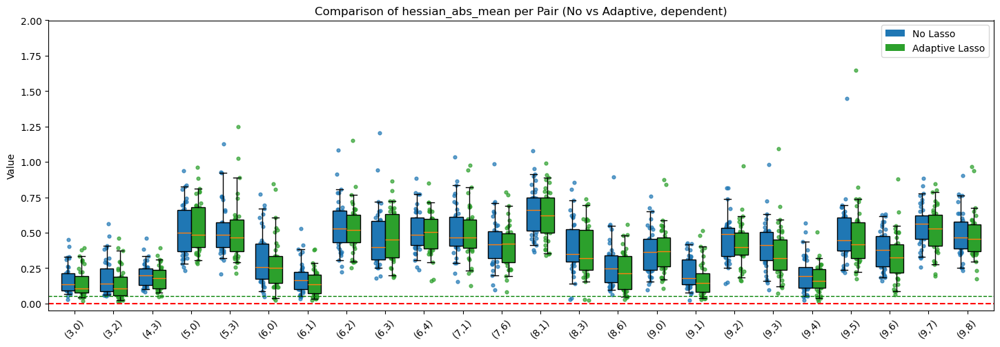

In [ ]:
plot_metric_values_no_vs_adaptive(
table_original_dict_no,
table_original_dict_adaptive,
    df_structure,
    metric='hessian_abs_mean',
    plot_dependence="independent",
    ylim=(-0.05, 1)
)

plot_metric_values_no_vs_adaptive(
table_original_dict_no,
table_original_dict_adaptive,
    df_structure,
    metric='hessian_abs_mean',
    plot_dependence="dependent",
    ylim=(-0.05, 2)
)

##### normed_hessian_abs_mean

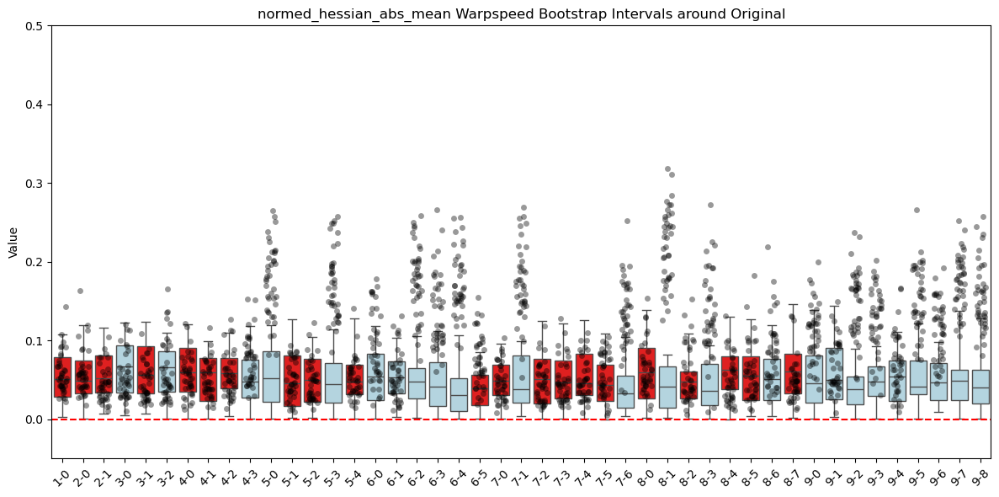

In [ ]:
df_pvalues_no = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_no, table_diffs_list_no, df_structure, metric="normed_hessian_abs_mean", ylim=(-0.05, 0.5), n=125)

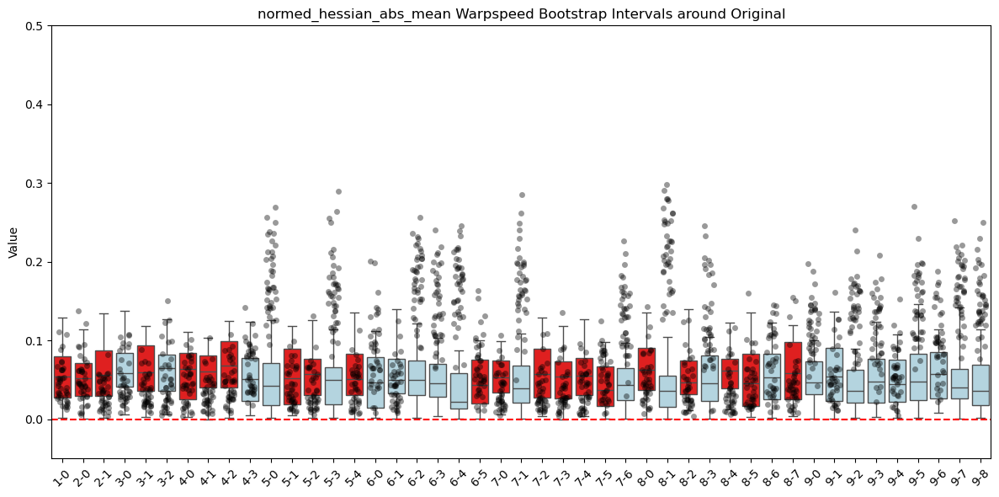

In [ ]:
df_pvalues_adaptive = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_adaptive, table_diffs_list_adaptive, df_structure, metric="normed_hessian_abs_mean", ylim=(-0.05, 0.5), n=125)

P-value Differences: Adaptive - No Penalty
Metric: — MyMetric
Dependent   pairs | mean diff: +0.0336  (n=960)
Independent pairs | mean diff: +0.1062  (n=840)


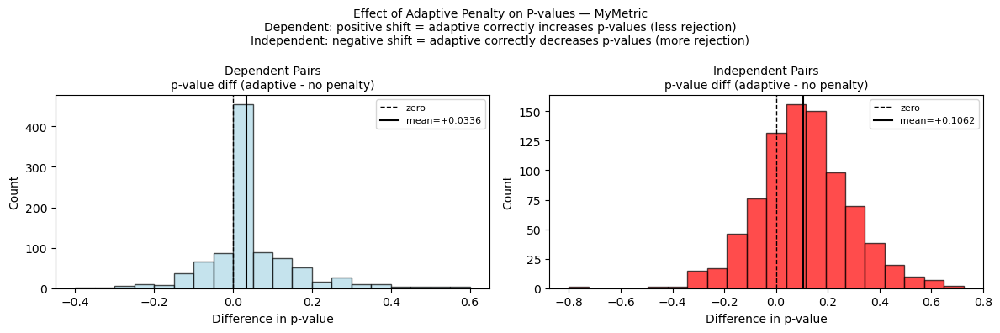

         group  dependence  mean_diff    n  pct_positive  pct_negative
0    dependent           1   0.033594  960      0.396875      0.222917
1  independent           0   0.106161  840      0.725000      0.223810


In [ ]:
# --- Usage ---
df_summary = plot_pvalue_differences(
    df_pvalues_adaptive, 
    df_pvalues_no, 
    title_suffix="— MyMetric"
)
print(df_summary)

##### iae

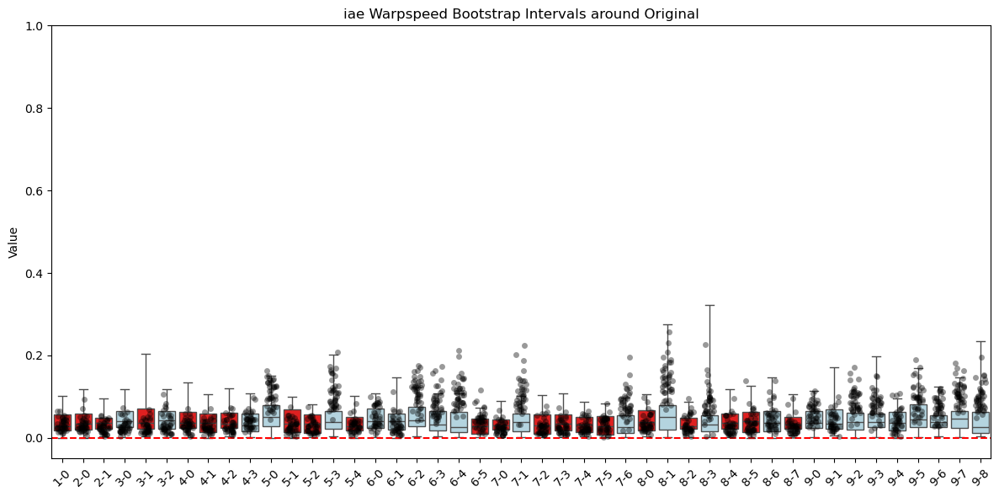

In [ ]:
df_pvalues_no = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_no, table_diffs_list_no, df_structure, metric="iae", ylim=(-0.05, 1), n=125)

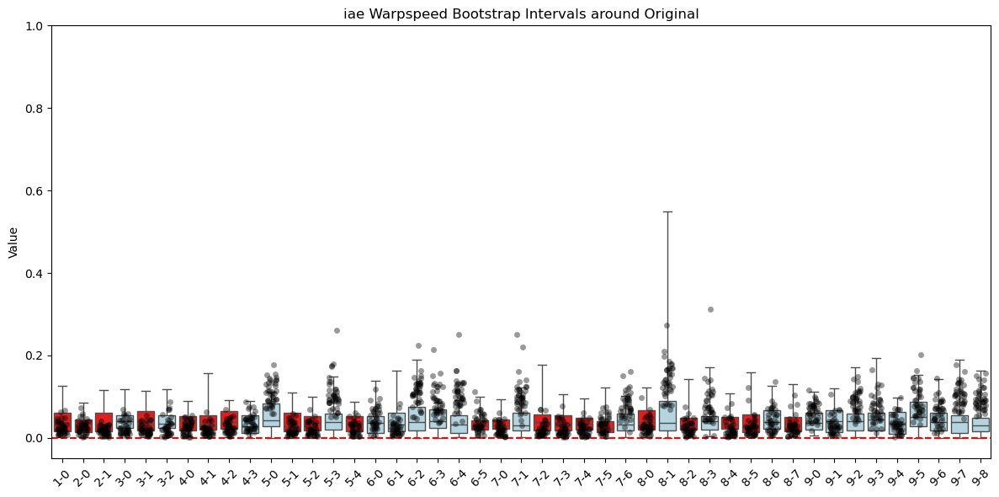

In [ ]:
df_pvalues_adaptive = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_adaptive, table_diffs_list_adaptive, df_structure, metric="iae", ylim=(-0.05, 1), n=125)

P-value Differences: Adaptive - No Penalty
Metric: — MyMetric
Dependent   pairs | mean diff: +0.0195  (n=960)
Independent pairs | mean diff: +0.0810  (n=840)


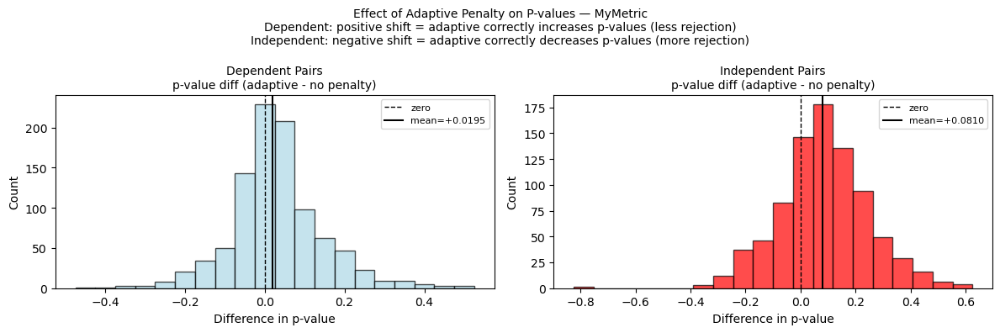

         group  dependence  mean_diff    n  pct_positive  pct_negative
0    dependent           1   0.019505  960      0.487500      0.375000
1  independent           0   0.080952  840      0.677381      0.263095


In [ ]:
# --- Usage ---
df_summary = plot_pvalue_differences(
    df_pvalues_adaptive, 
    df_pvalues_no, 
    title_suffix="— MyMetric"
)
print(df_summary)

#### Seed 0 C-Vine

In [ ]:
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = "cvine_10D_125obs_bootstrap_s0", 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=0,
                                                                                                                                              vine_type="C-Vine",
                                                                                                                                              Independence_tree=3)

table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(subset_no_original, subset_no_bootstrap,
                                                                        data="synthetic")

table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(subset_adaptive_original, subset_adaptive_bootstrap,
                                                                        data="synthetic")

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 50 51 52 53
 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69]
There are  40 nmber of unique seeds.


Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


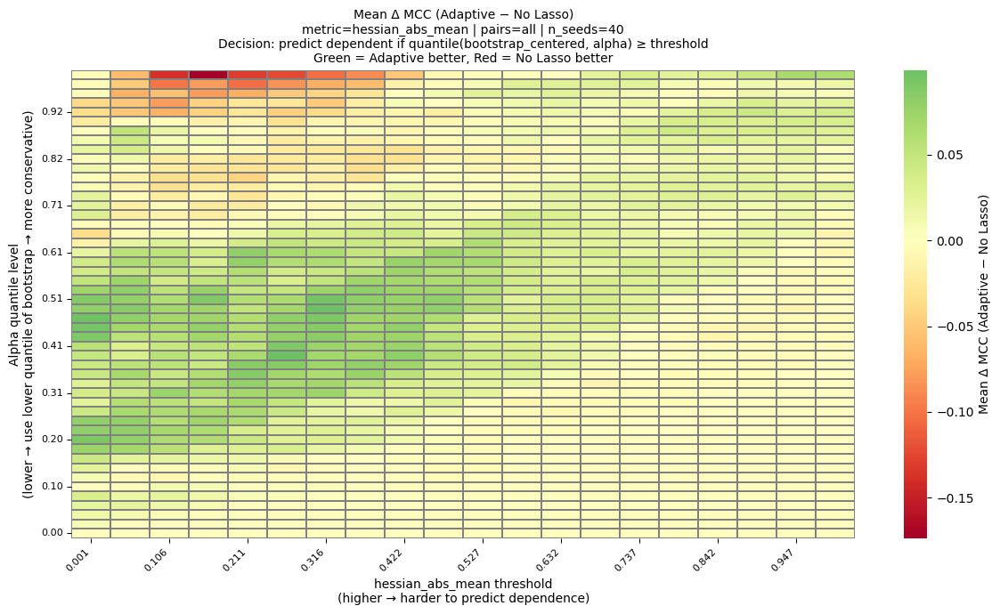

{'mean_diff': array([[ 0.00000000e+00,  7.05095094e-03,  1.56198426e-02,
          2.21376162e-02,  3.39662400e-02, -1.78403853e-03,
          6.79298063e-03,  2.38797596e-02,  4.36468329e-02,
          7.38550756e-02,  9.16013584e-02,  7.90732628e-02,
          8.03511509e-02,  4.37525512e-02,  2.51935457e-02,
          3.75141872e-02,  2.98924860e-02,  4.50400455e-02,
          4.53226509e-02,  4.98944955e-02,  5.66669203e-02,
          8.95347634e-02,  9.59545094e-02,  9.81260883e-02,
          8.01106021e-02,  8.70623871e-02,  7.20646528e-02,
          5.13163323e-02,  3.95995974e-02,  4.04747945e-02,
          2.07926908e-02, -1.56744221e-02, -3.50800175e-02,
         -3.98872875e-03,  3.11807705e-02,  2.36729259e-02,
          2.29981763e-02,  6.54752488e-03,  3.35911958e-03,
          1.39472284e-02,  4.08895254e-03,  2.06966706e-02,
          1.17388482e-02, -1.05402776e-04, -2.16278765e-02,
         -3.53267475e-02, -3.82836134e-02, -4.02911482e-03,
         -4.02911482e-03, -

In [ ]:
plot_heatmap_score_diff_threshold_vs_alpha(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    alphas=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    n_thresholds=30,             # number of threshold grid points if not provided
    n_alphas=20,                 # number of alpha grid points if not provided
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
)

Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


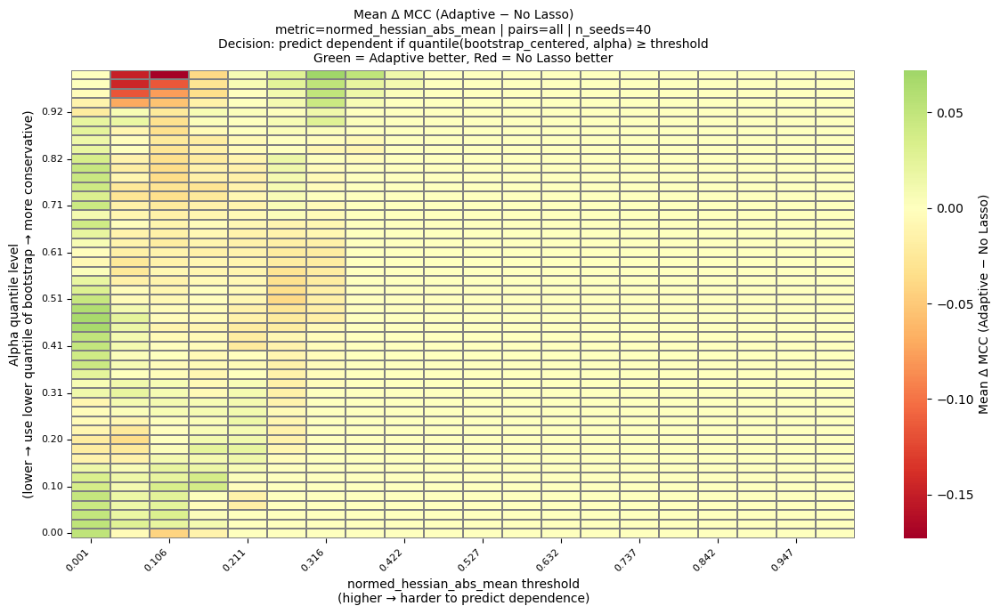

{'mean_diff': array([[ 5.19980636e-02,  5.18366990e-02,  4.90407283e-02,
          4.30385057e-02,  4.77684284e-02,  3.71586823e-02,
          3.27315188e-02,  1.49062286e-02, -1.23392423e-02,
         -1.87724943e-02, -2.07904386e-02, -1.01837240e-02,
         -4.94877149e-03, -3.31695415e-03, -1.05101885e-02,
          1.31218065e-02,  6.18681403e-03,  2.35810645e-02,
          4.31070665e-02,  4.09188334e-02,  4.85802927e-02,
          5.11170008e-02,  6.69843532e-02,  6.57655095e-02,
          6.08056835e-02,  4.69732518e-02,  3.07543931e-02,
          1.93201243e-02,  3.19805425e-03, -7.54113571e-03,
         -2.17471072e-03,  7.00940390e-03,  1.97342619e-02,
          4.07112804e-02,  1.08268632e-02,  4.27528454e-02,
          3.13606452e-02,  4.24239650e-02,  4.46900672e-02,
          4.65857969e-02,  3.55584551e-02,  1.93688622e-02,
          1.50213727e-02,  2.29156994e-02,  2.04358761e-02,
         -2.14396435e-02, -1.20873445e-02, -4.02911482e-03,
          0.00000000e+00,  

In [ ]:
plot_heatmap_score_diff_threshold_vs_alpha(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    alphas=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    n_thresholds=30,             # number of threshold grid points if not provided
    n_alphas=20,                 # number of alpha grid points if not provided
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
)

##### hessian_abs_mean

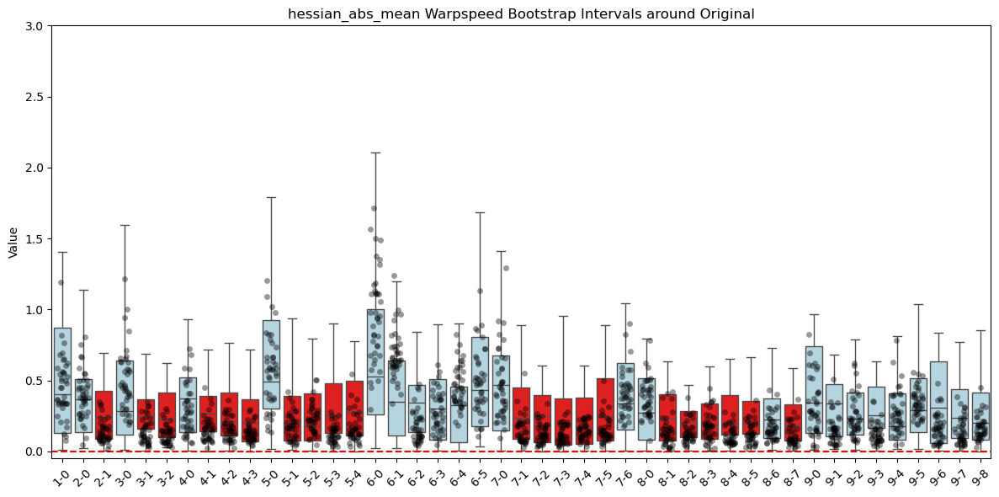

In [ ]:
df_pvalues_no = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_no, table_diffs_list_no, df_structure, metric="hessian_abs_mean", ylim=(-0.05, 3), n=125)

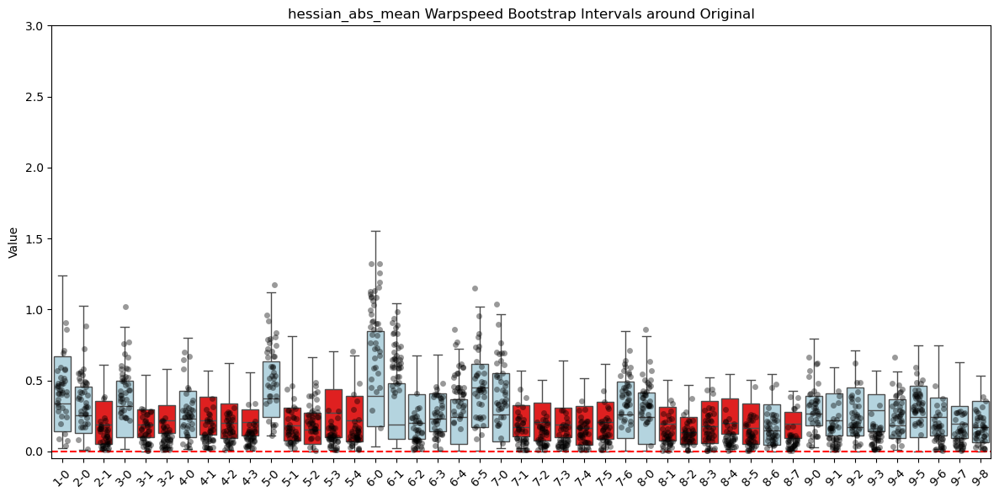

In [ ]:
df_pvalues_adaptive = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_adaptive, table_diffs_list_adaptive, df_structure, metric="hessian_abs_mean", ylim=(-0.05, 3), n=125)

P-value Differences: Adaptive - No Penalty
Metric: — MyMetric
Dependent   pairs | mean diff: -0.0457  (n=960)
Independent pairs | mean diff: +0.0053  (n=840)


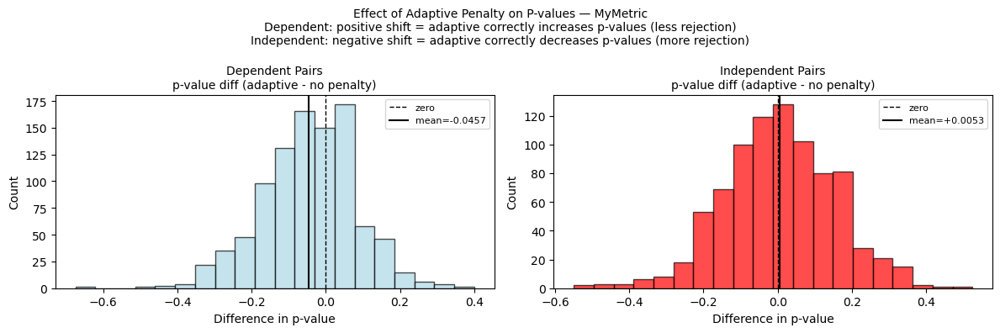

         group  dependence  mean_diff    n  pct_positive  pct_negative
0    dependent           1  -0.045677  960      0.314583      0.607292
1  independent           0   0.005327  840      0.461905      0.453571


In [ ]:
# --- Usage ---
df_summary = plot_pvalue_differences(
    df_pvalues_adaptive, 
    df_pvalues_no, 
    title_suffix="— MyMetric"
)
print(df_summary)

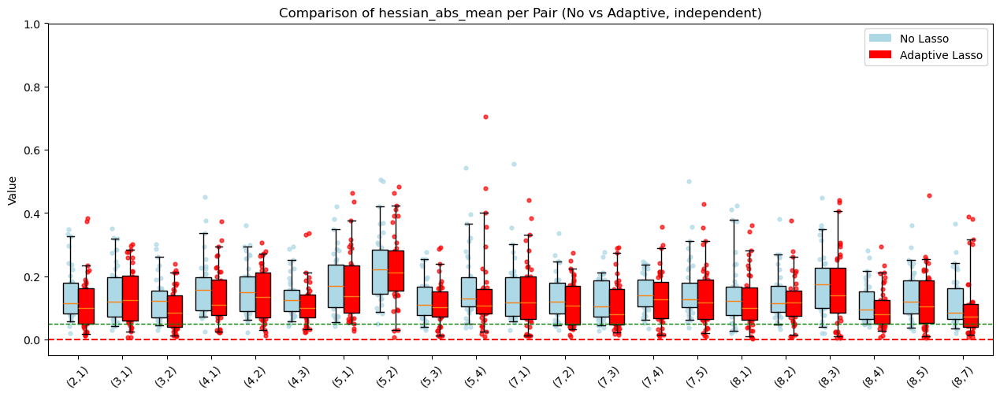

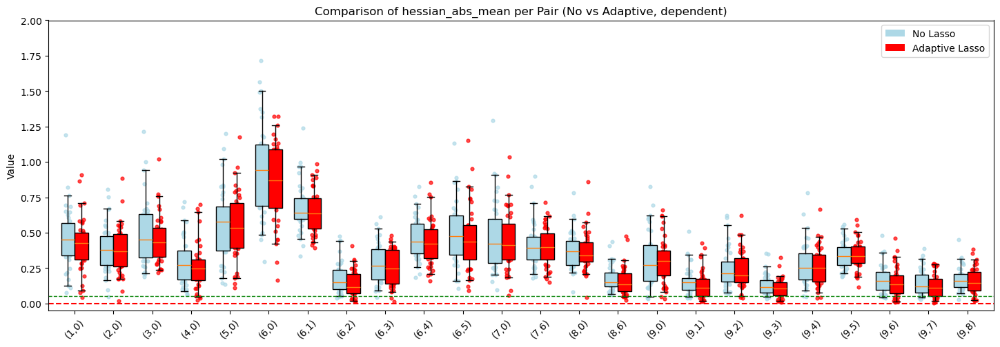

In [ ]:
plot_metric_values_no_vs_adaptive(
table_original_dict_no,
table_original_dict_adaptive,
    df_structure,
    metric='hessian_abs_mean',
    plot_dependence="independent",
    ylim=(-0.05, 1)
)

plot_metric_values_no_vs_adaptive(
table_original_dict_no,
table_original_dict_adaptive,
    df_structure,
    metric='hessian_abs_mean',
    plot_dependence="dependent",
    ylim=(-0.05, 2)
)

##### normed_hessian_abs_mean

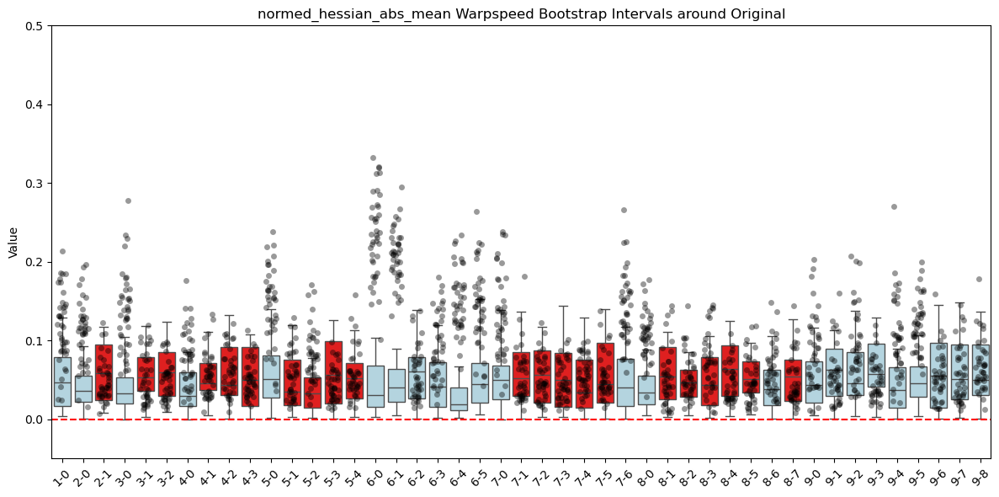

In [ ]:
df_pvalues_no = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_no, table_diffs_list_no, df_structure, metric="normed_hessian_abs_mean", ylim=(-0.05, 0.5), n=125)

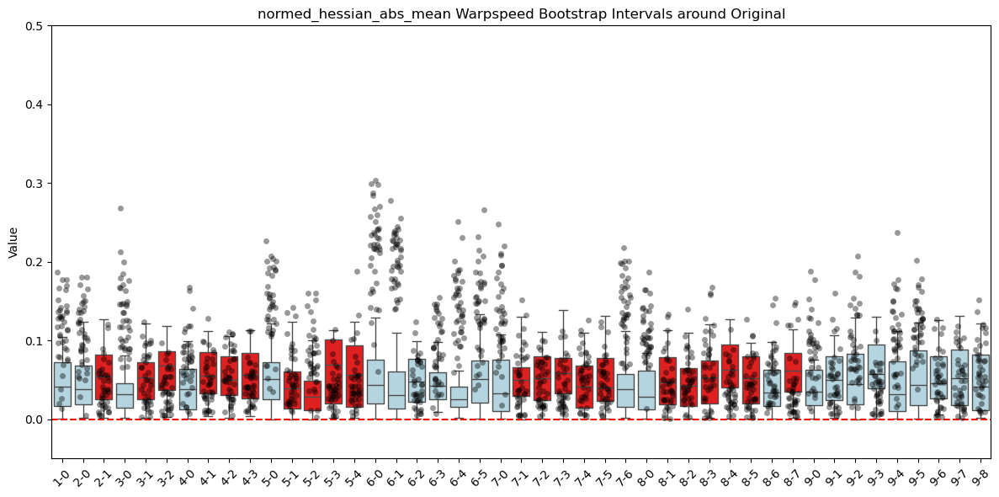

In [ ]:
df_pvalues_adaptive = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_adaptive, table_diffs_list_adaptive, df_structure, metric="normed_hessian_abs_mean", ylim=(-0.05, 0.5), n=125)

P-value Differences: Adaptive - No Penalty
Metric: — MyMetric
Dependent   pairs | mean diff: +0.0052  (n=960)
Independent pairs | mean diff: +0.0510  (n=840)


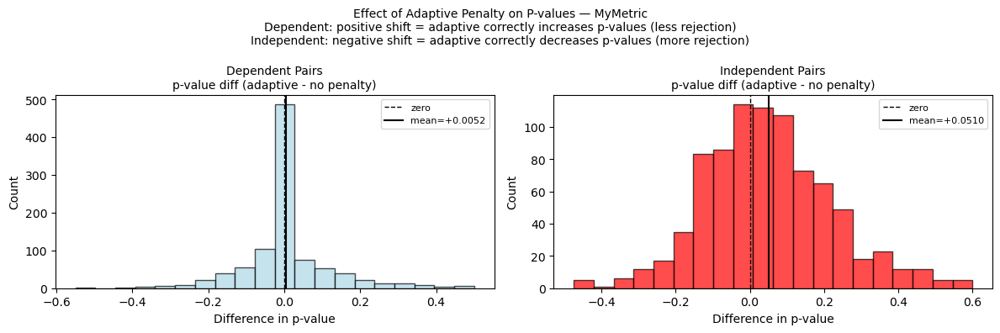

         group  dependence  mean_diff    n  pct_positive  pct_negative
0    dependent           1   0.005234  960      0.344792      0.358333
1  independent           0   0.051042  840      0.572619      0.358333


In [ ]:
# --- Usage ---
df_summary = plot_pvalue_differences(
    df_pvalues_adaptive, 
    df_pvalues_no, 
    title_suffix="— MyMetric"
)
print(df_summary)

##### iae

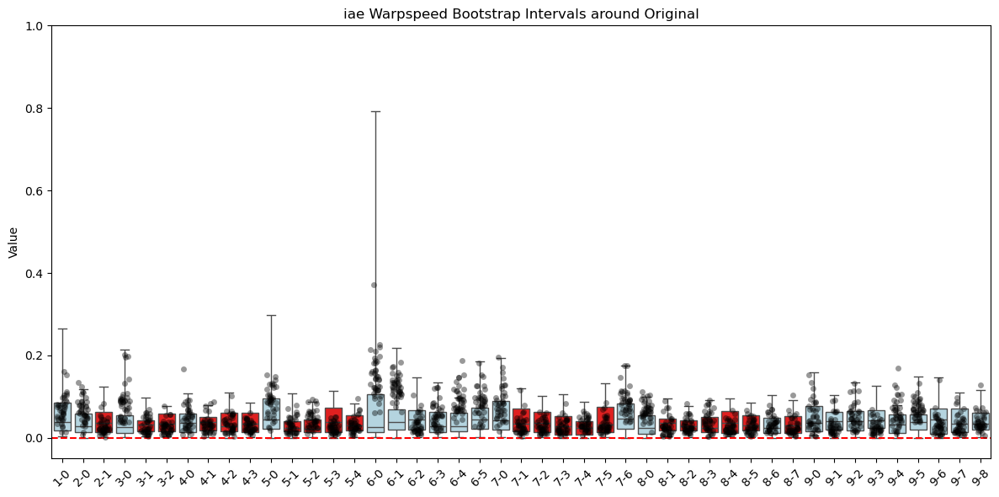

In [ ]:
df_pvalues_no = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_no, table_diffs_list_no, df_structure, metric="iae", ylim=(-0.05, 1), n=125)

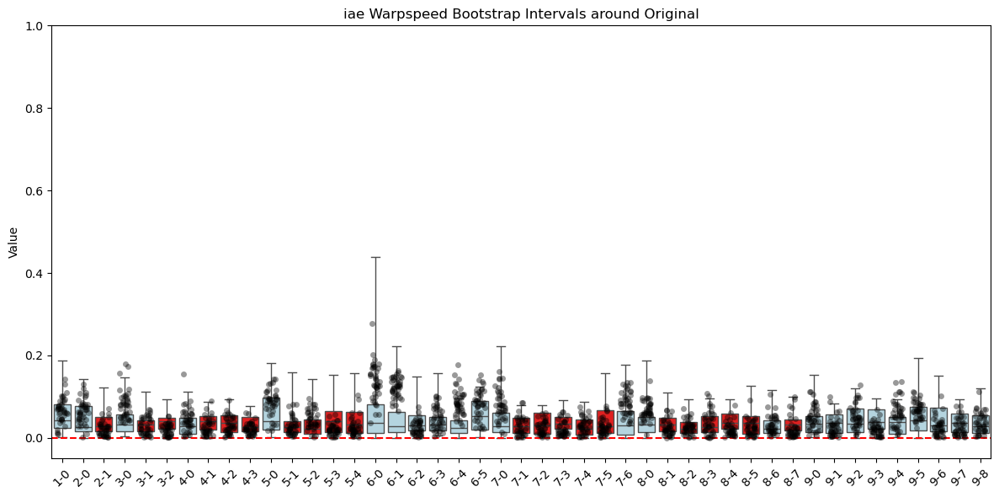

In [ ]:
df_pvalues_adaptive = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_adaptive, table_diffs_list_adaptive, df_structure, metric="iae", ylim=(-0.05, 1), n=125)

P-value Differences: Adaptive - No Penalty
Metric: — MyMetric
Dependent   pairs | mean diff: -0.0029  (n=960)
Independent pairs | mean diff: +0.0391  (n=840)


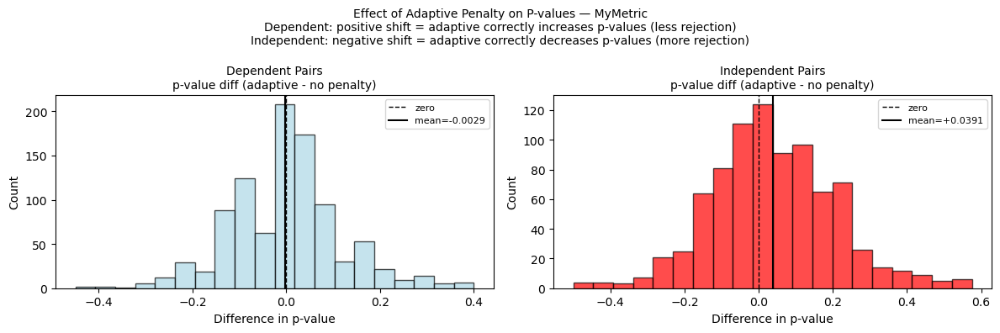

         group  dependence  mean_diff    n  pct_positive  pct_negative
0    dependent           1  -0.002917  960      0.425000      0.467708
1  independent           0   0.039107  840      0.535714      0.380952


In [ ]:
# --- Usage ---
df_summary = plot_pvalue_differences(
    df_pvalues_adaptive, 
    df_pvalues_no, 
    title_suffix="— MyMetric"
)
print(df_summary)

#### Seed 1 D-Vine Strong

In [ ]:
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = "dvine_strong_10D_125obs_bootstrap_s1", 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=1,
                                                                                                                                              vine_type="D-Vine",
                                                                                                                                              Independence_tree=3)

table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(subset_no_original, subset_no_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(subset_adaptive_original, subset_adaptive_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

The unique seeds are: [50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73
 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95 96 97
 98 99]
There are  50 nmber of unique seeds.


Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


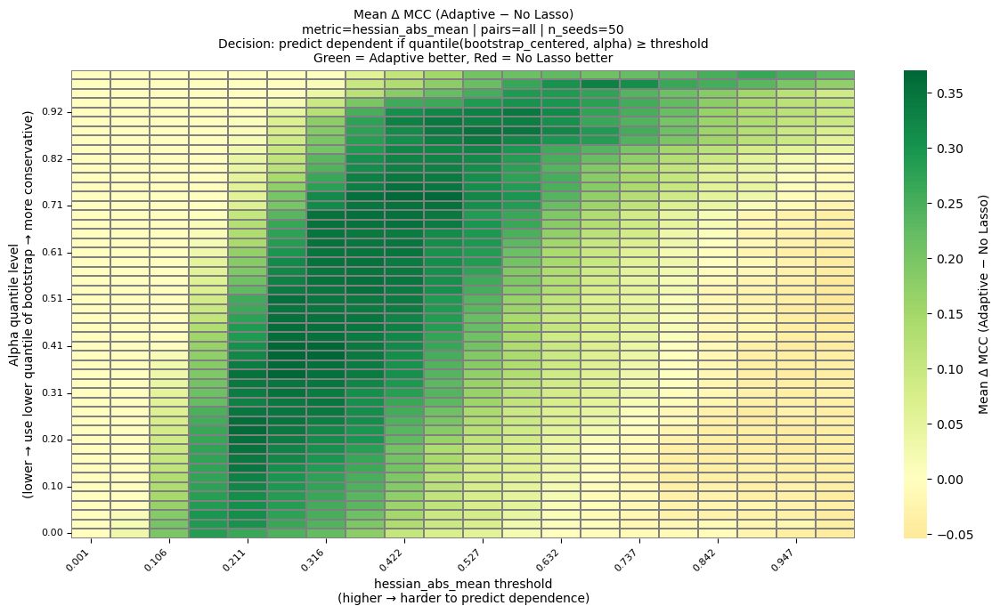

{'mean_diff': array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
          0.00000000e+00,  

In [ ]:
plot_heatmap_score_diff_threshold_vs_alpha(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    alphas=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    n_thresholds=30,             # number of threshold grid points if not provided
    n_alphas=20,                 # number of alpha grid points if not provided
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
)

##### hessian_abs_mean

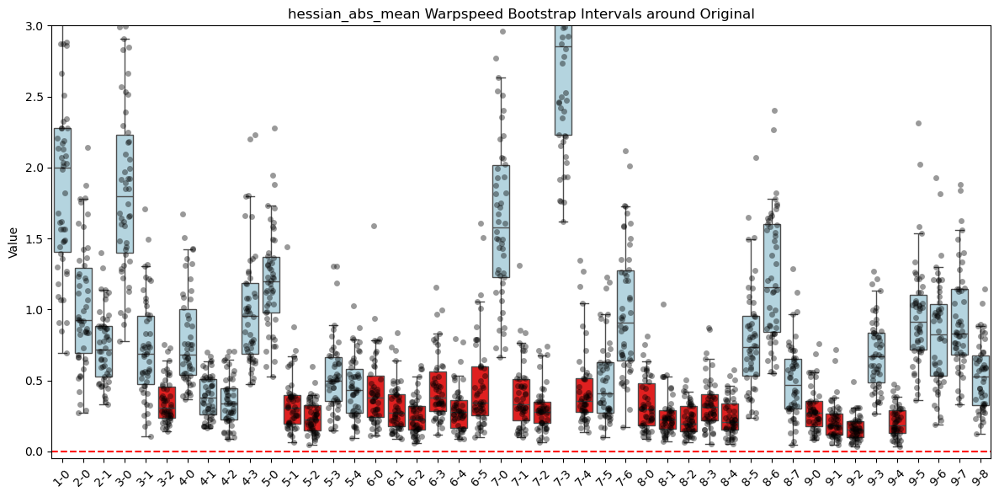

In [ ]:
df_pvalues_no = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_no, table_diffs_list_no, df_structure, metric="hessian_abs_mean", ylim=(-0.05, 3), n=125)

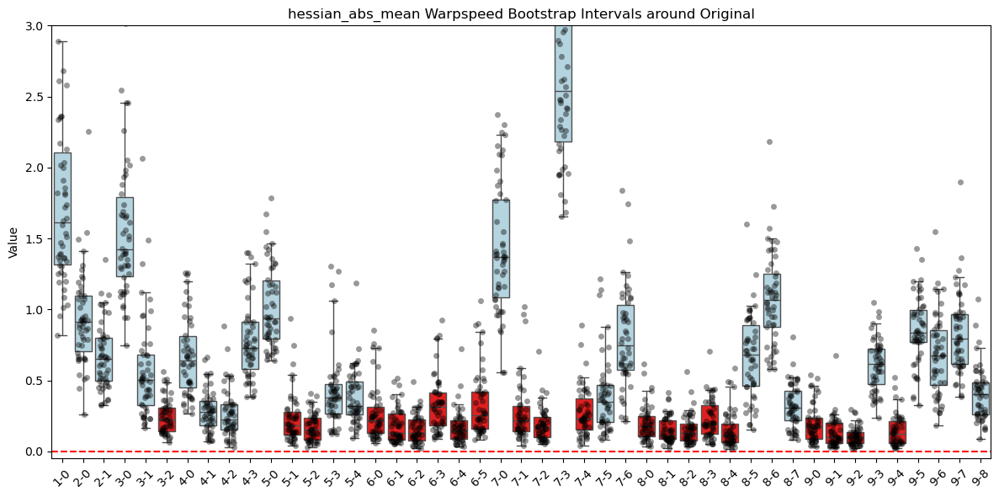

In [ ]:
df_pvalues_adaptive = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_adaptive, table_diffs_list_adaptive, df_structure, metric="hessian_abs_mean", ylim=(-0.05, 3), n=125)

P-value Differences: Adaptive - No Penalty
Metric: — MyMetric
Dependent   pairs | mean diff: +0.0000  (n=1200)
Independent pairs | mean diff: -0.0000  (n=1050)


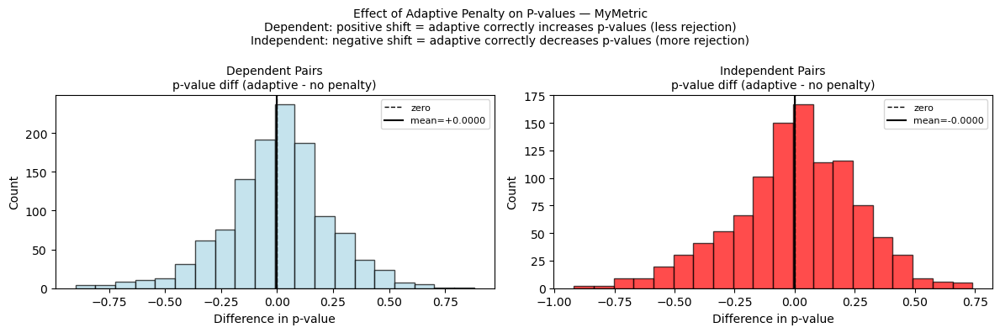

         group  dependence     mean_diff     n  pct_positive  pct_negative
0    dependent           1  9.251859e-20  1200      0.494167      0.449167
1  independent           0 -1.057355e-18  1050      0.500952      0.459048


In [ ]:
# --- Usage ---
df_summary = plot_pvalue_differences(
    df_pvalues_adaptive, 
    df_pvalues_no, 
    title_suffix="— MyMetric"
)
print(df_summary)

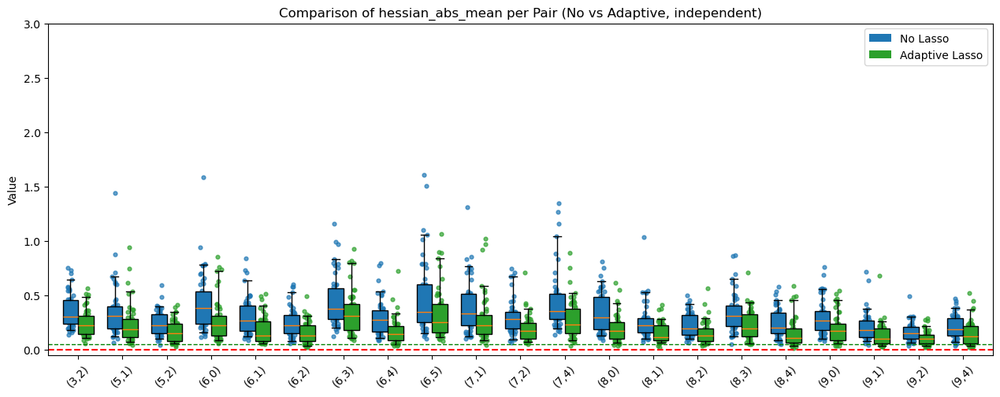

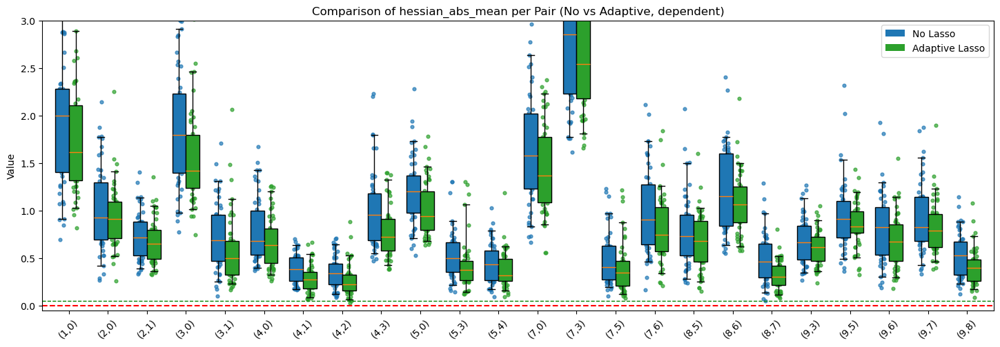

In [ ]:
plot_metric_values_no_vs_adaptive(
table_original_dict_no,
table_original_dict_adaptive,
    df_structure,
    metric='hessian_abs_mean',
    plot_dependence="independent",
    ylim=(-0.05, 3)
)

plot_metric_values_no_vs_adaptive(
table_original_dict_no,
table_original_dict_adaptive,
    df_structure,
    metric='hessian_abs_mean',
    plot_dependence="dependent",
    ylim=(-0.05, 3)
)

##### normed_hessian_abs_mean

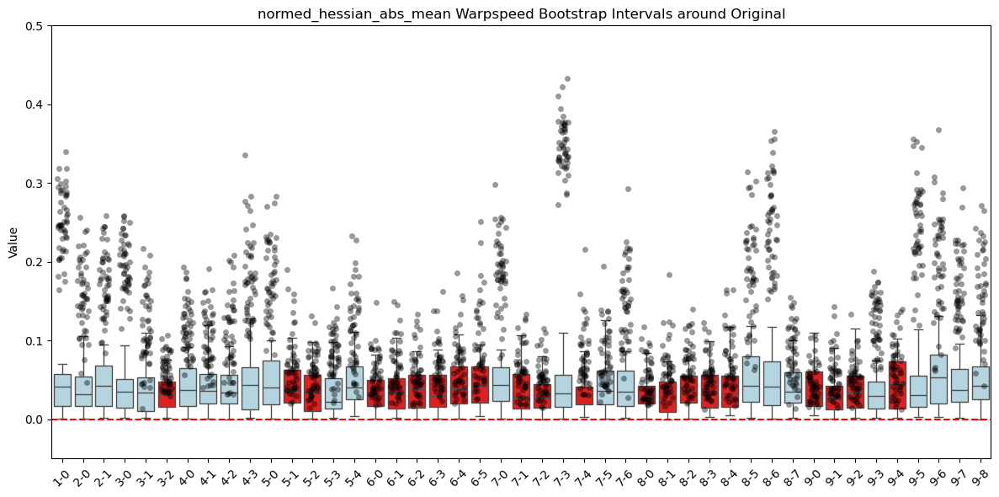

In [ ]:
df_pvalues_no = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_no, table_diffs_list_no, df_structure, metric="normed_hessian_abs_mean", ylim=(-0.05, 0.5), n=125)

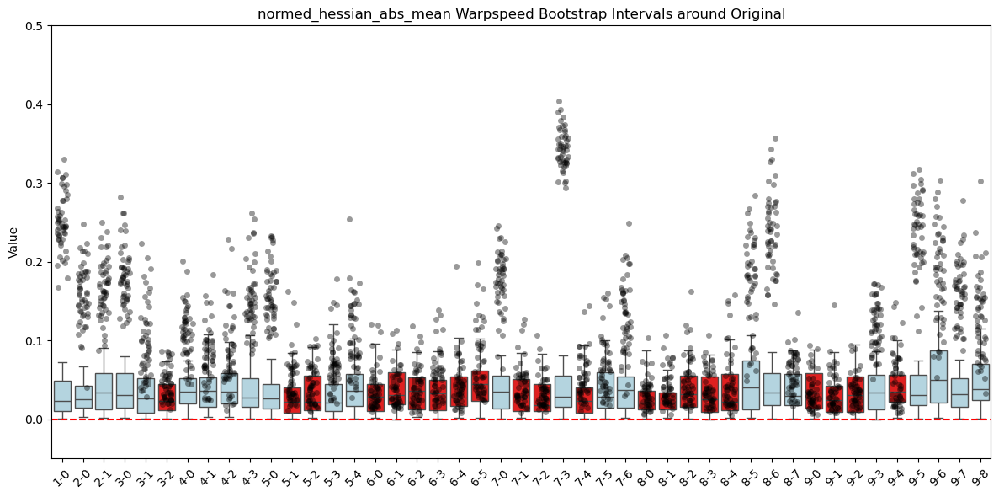

In [ ]:
df_pvalues_adaptive = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_adaptive, table_diffs_list_adaptive, df_structure, metric="normed_hessian_abs_mean", ylim=(-0.05, 0.5), n=125)

P-value Differences: Adaptive - No Penalty
Metric: — MyMetric
Dependent   pairs | mean diff: +0.0144  (n=1200)
Independent pairs | mean diff: +0.1046  (n=1050)


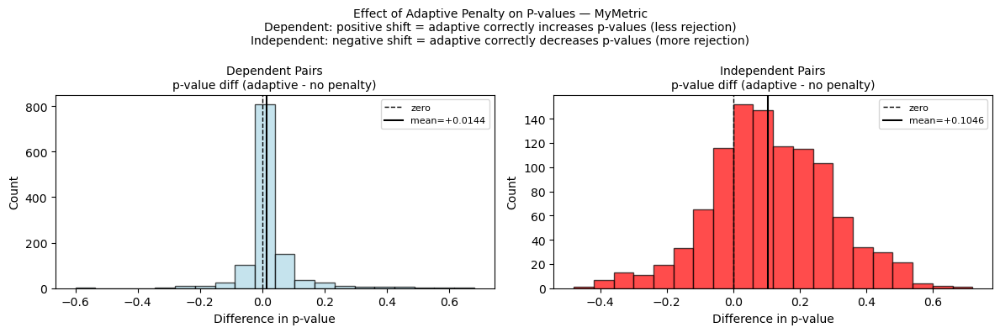

         group  dependence  mean_diff     n  pct_positive  pct_negative
0    dependent           1   0.014400  1200      0.290000      0.217500
1  independent           0   0.104552  1050      0.701905      0.252381


In [ ]:
# --- Usage ---
df_summary = plot_pvalue_differences(
    df_pvalues_adaptive, 
    df_pvalues_no, 
    title_suffix="— MyMetric"
)
print(df_summary)

##### global_normed_hessian_abs_mean

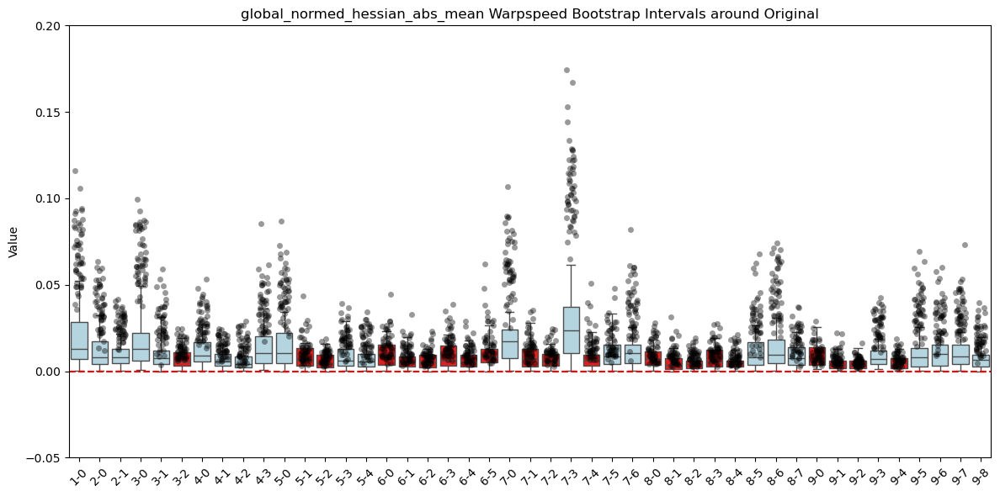

In [ ]:
df_pvalues_no = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_no, table_diffs_list_no, df_structure, metric="global_normed_hessian_abs_mean", ylim=(-0.05, 0.2), n=125)

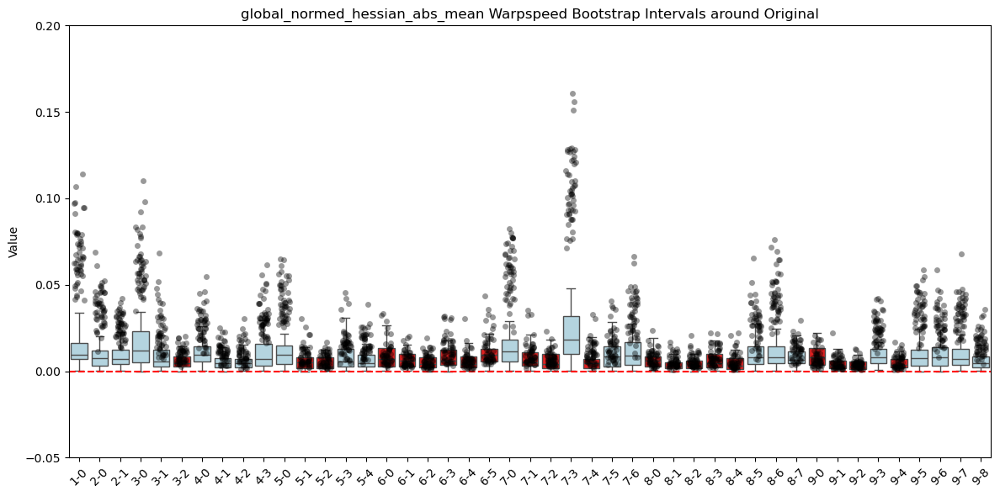

In [ ]:
df_pvalues_adaptive = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_adaptive, table_diffs_list_adaptive, df_structure, metric="global_normed_hessian_abs_mean", ylim=(-0.05, 0.2), n=125)

P-value Differences: Adaptive - No Penalty
Metric: — MyMetric
Dependent   pairs | mean diff: +0.0060  (n=1200)
Independent pairs | mean diff: +0.0967  (n=1050)


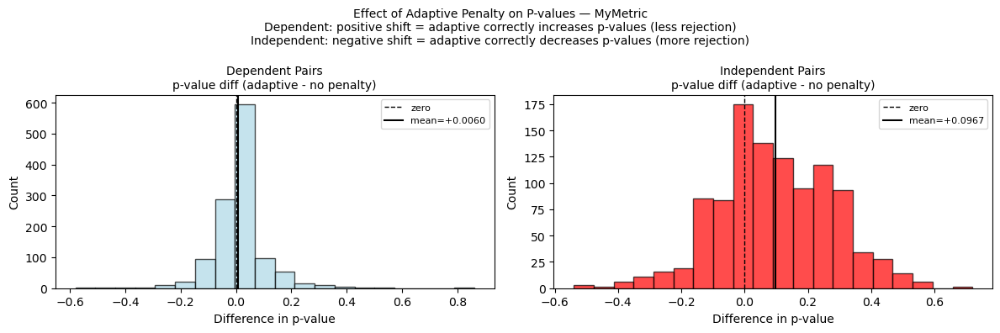

         group  dependence  mean_diff     n  pct_positive  pct_negative
0    dependent           1   0.006000  1200      0.324167      0.350000
1  independent           0   0.096724  1050      0.674286      0.261905


In [ ]:
# --- Usage ---
df_summary = plot_pvalue_differences(
    df_pvalues_adaptive, 
    df_pvalues_no, 
    title_suffix="— MyMetric"
)
print(df_summary)

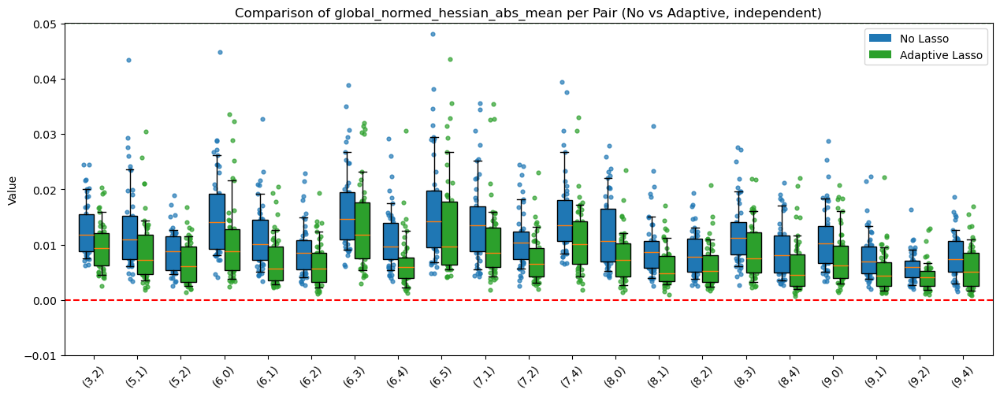

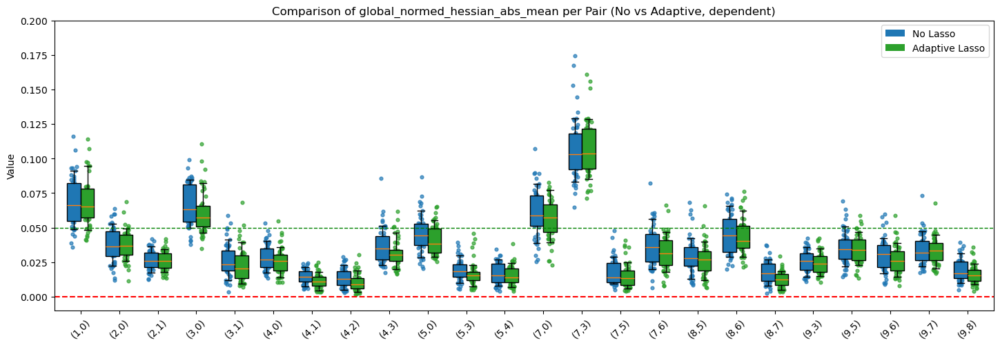

In [ ]:
plot_metric_values_no_vs_adaptive(
table_original_dict_no,
table_original_dict_adaptive,
    df_structure,
    metric='global_normed_hessian_abs_mean',
    plot_dependence="independent",
    ylim=(-0.01, 0.05)
)

plot_metric_values_no_vs_adaptive(
table_original_dict_no,
table_original_dict_adaptive,
    df_structure,
    metric='global_normed_hessian_abs_mean',
    plot_dependence="dependent",
    ylim=(-0.01, 0.2)
)

#### Seed 1 R-Vine

In [ ]:
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = "rvine_10D_125obs_bootstrap_s1", 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=1,
                                                                                                                                              vine_type="R-Vine",
                                                                                                                                              Independence_tree=3)

table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(subset_no_original, subset_no_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(subset_adaptive_original, subset_adaptive_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49]
There are  50 nmber of unique seeds.


Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


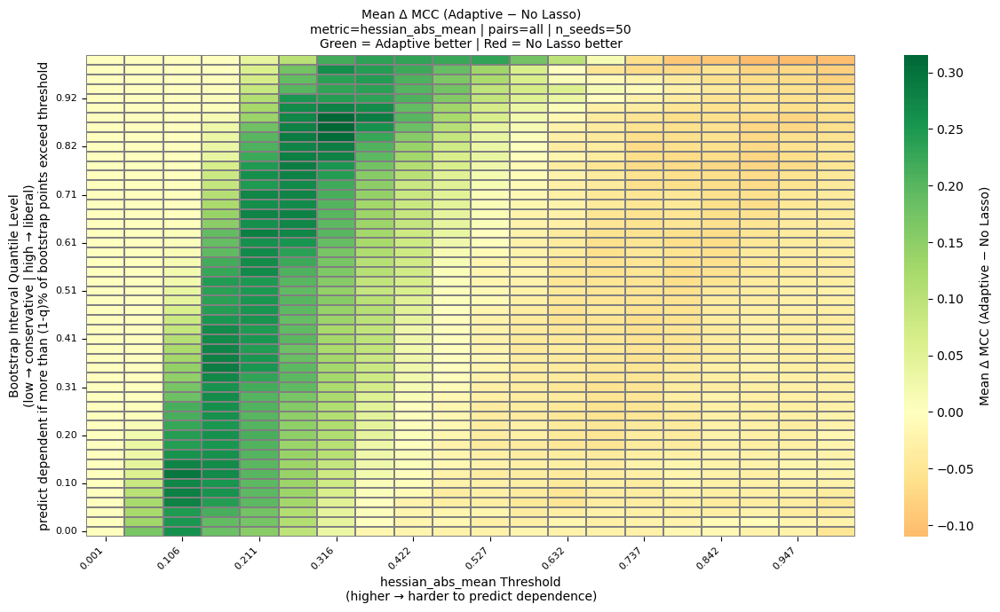

In [ ]:
_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
)

Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


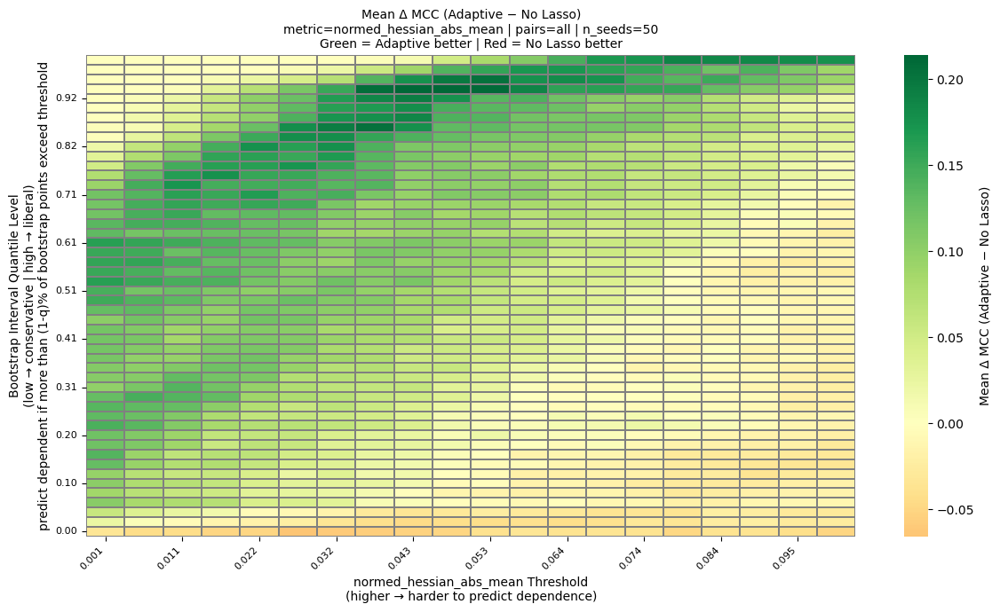

In [ ]:
_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
)

Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


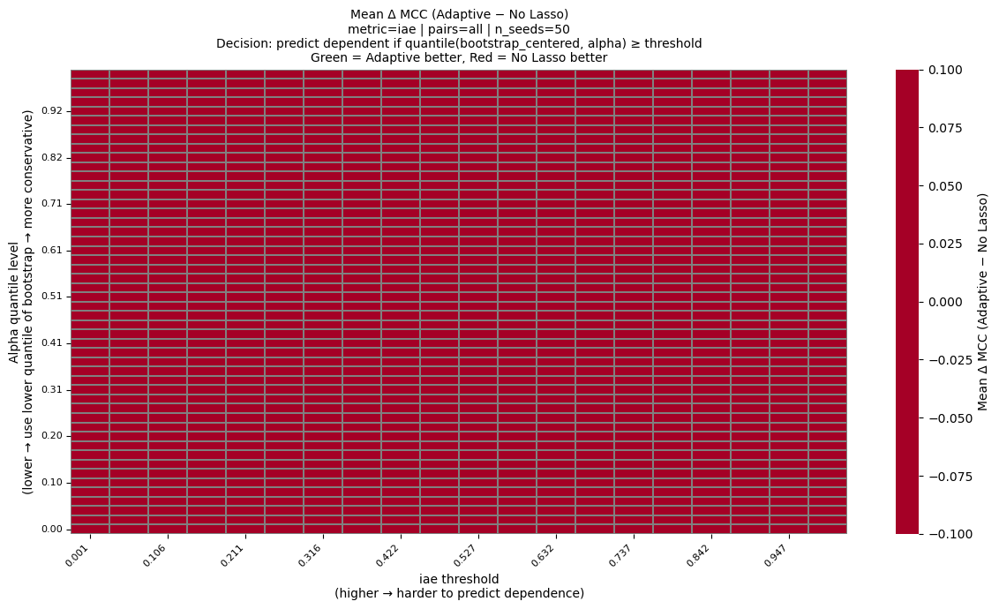

In [ ]:
_ = plot_heatmap_score_diff_threshold_vs_alpha(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="iae",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    alphas=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    n_thresholds=30,             # number of threshold grid points if not provided
    n_alphas=20,                 # number of alpha grid points if not provided
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
)

##### hessian_abs_mean

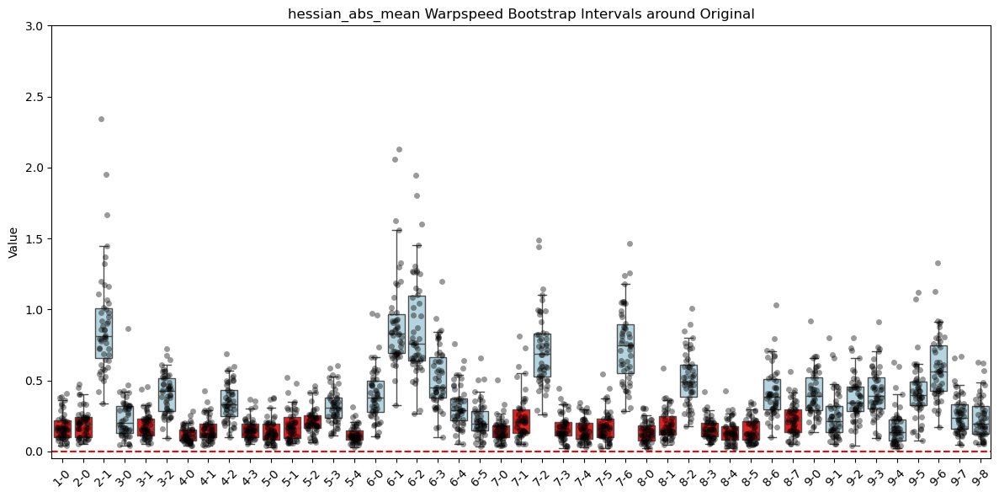

In [ ]:
df_pvalues_no = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_no, table_diffs_list_no, df_structure, metric="hessian_abs_mean", ylim=(-0.05, 3), n=125)

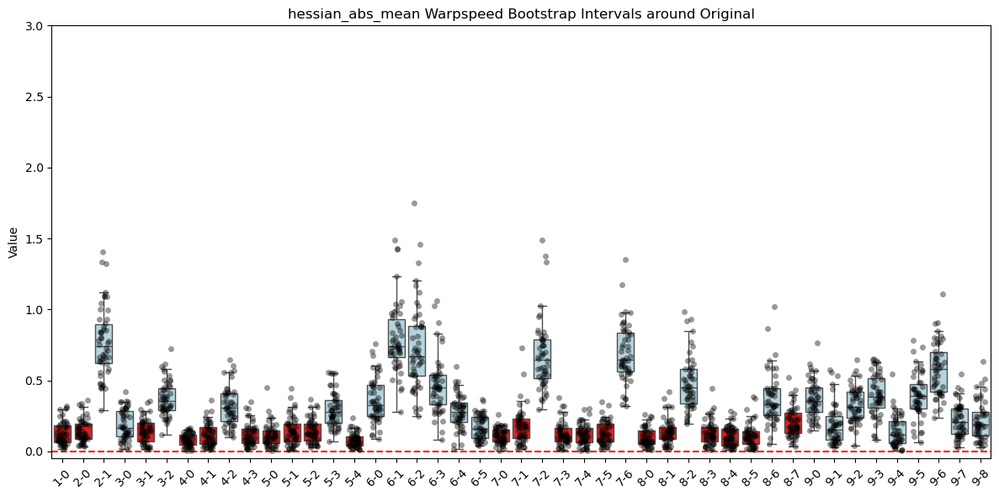

In [ ]:
df_pvalues_adaptive = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_adaptive, table_diffs_list_adaptive, df_structure, metric="hessian_abs_mean", ylim=(-0.05, 3), n=125)

P-value Differences: Adaptive - No Penalty
Metric: — MyMetric
Dependent   pairs | mean diff: +0.0000  (n=1200)
Independent pairs | mean diff: +0.0000  (n=1050)


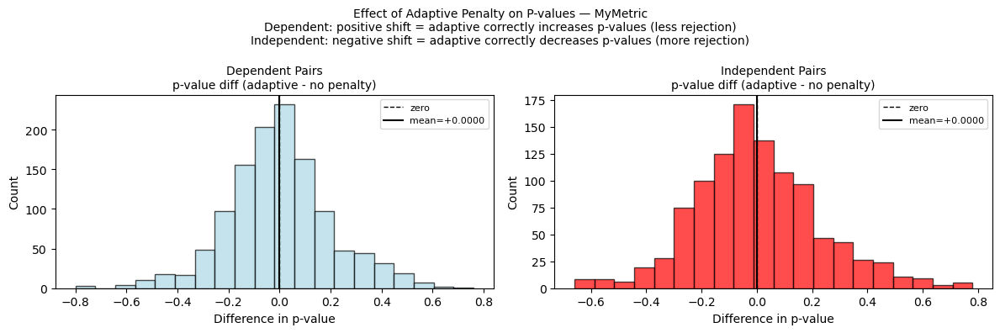

         group  dependence     mean_diff     n  pct_positive  pct_negative
0    dependent           1  1.295260e-18  1200      0.450833      0.467500
1  independent           0  7.401487e-19  1050      0.437143      0.514286


In [ ]:
# --- Usage ---
df_summary = plot_pvalue_differences(
    df_pvalues_adaptive, 
    df_pvalues_no, 
    title_suffix="— MyMetric"
)
print(df_summary)

##### normed_hessian_abs_mean

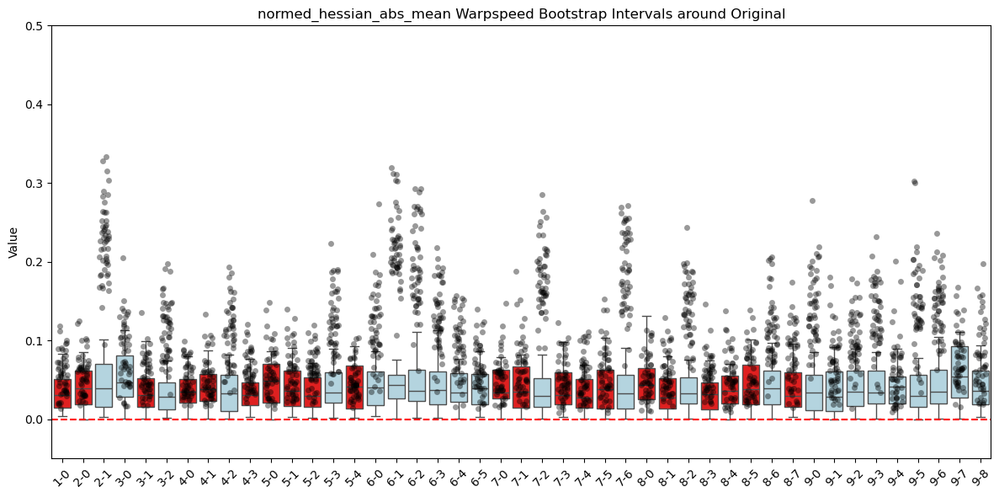

In [ ]:
df_pvalues_no = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_no, table_diffs_list_no, df_structure, metric="normed_hessian_abs_mean", ylim=(-0.05, 0.5), n=125)

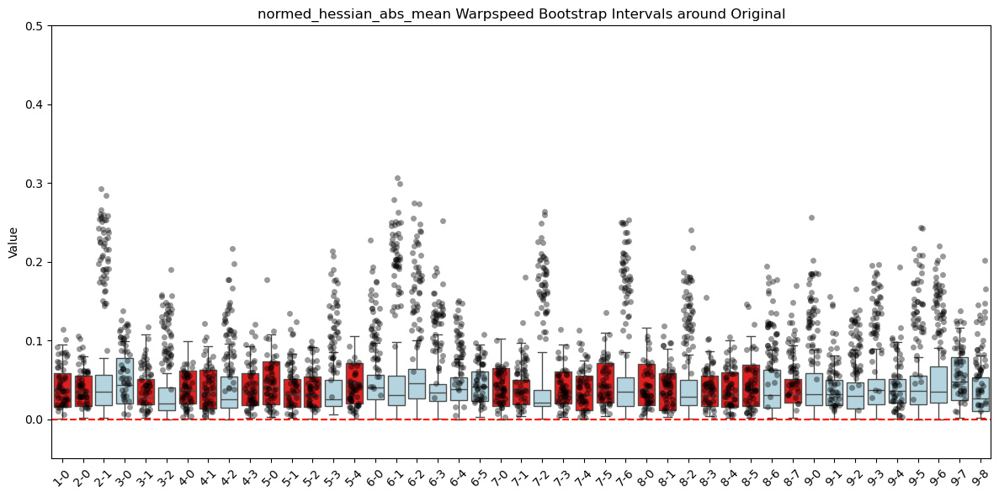

In [ ]:
df_pvalues_adaptive = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_adaptive, table_diffs_list_adaptive, df_structure, metric="normed_hessian_abs_mean", ylim=(-0.05, 0.5), n=125)

P-value Differences: Adaptive - No Penalty
Metric: — MyMetric
Dependent   pairs | mean diff: +0.0173  (n=1200)
Independent pairs | mean diff: +0.1168  (n=1050)


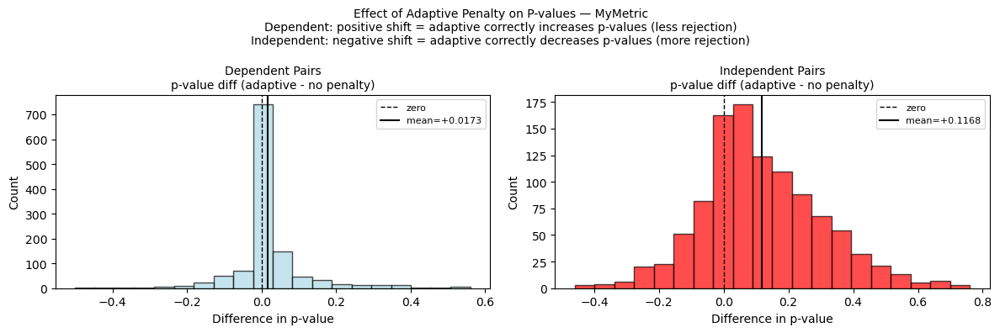

         group  dependence  mean_diff     n  pct_positive  pct_negative
0    dependent           1   0.017250  1200      0.341667      0.240833
1  independent           0   0.116819  1050      0.725714      0.220000


In [ ]:
# --- Usage ---
df_summary = plot_pvalue_differences(
    df_pvalues_adaptive, 
    df_pvalues_no, 
    title_suffix="— MyMetric"
)
print(df_summary)

##### global_normed_hessian_abs_mean

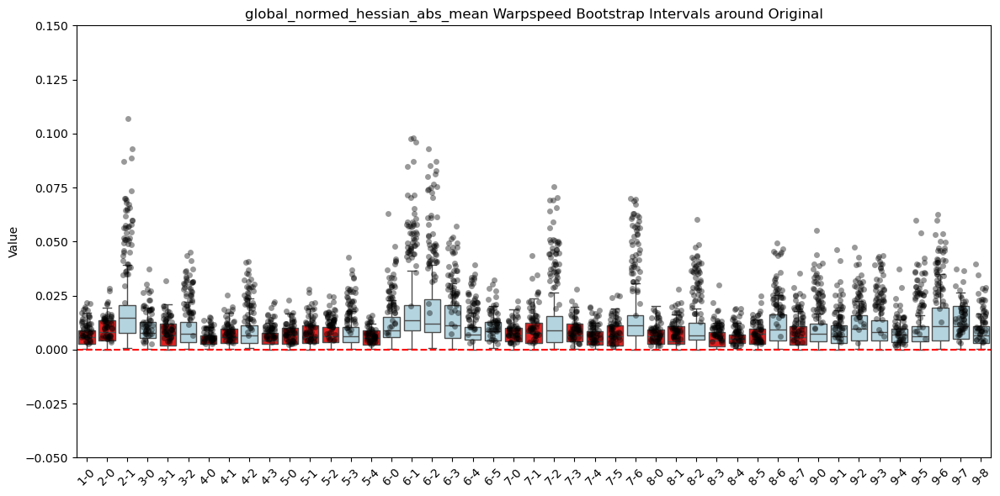

In [ ]:
df_pvalues_no = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_no, table_diffs_list_no, df_structure, metric="global_normed_hessian_abs_mean", ylim=(-0.05, 0.15), n=125)

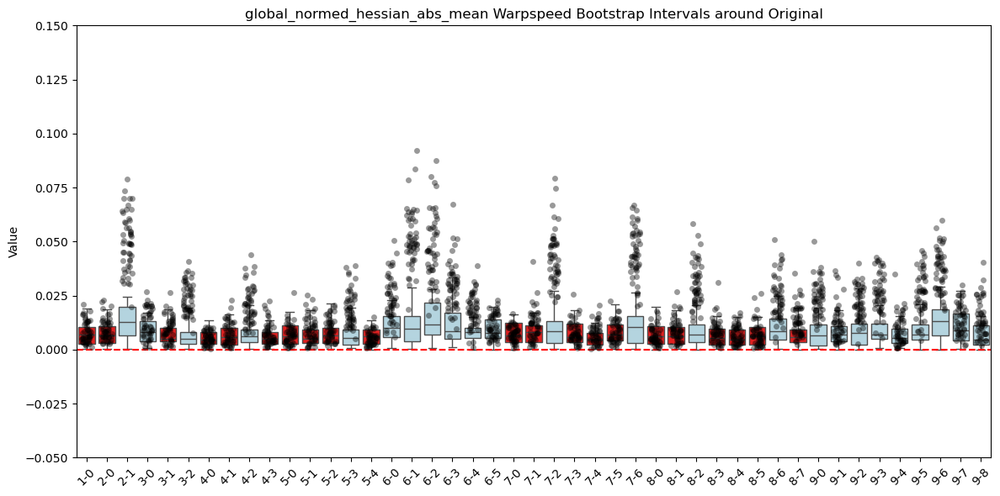

In [ ]:
df_pvalues_adaptive = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_adaptive, table_diffs_list_adaptive, df_structure, metric="global_normed_hessian_abs_mean", ylim=(-0.05, 0.15), n=125)

P-value Differences: Adaptive - No Penalty
Metric: — MyMetric
Dependent   pairs | mean diff: +0.0112  (n=1200)
Independent pairs | mean diff: +0.1184  (n=1050)


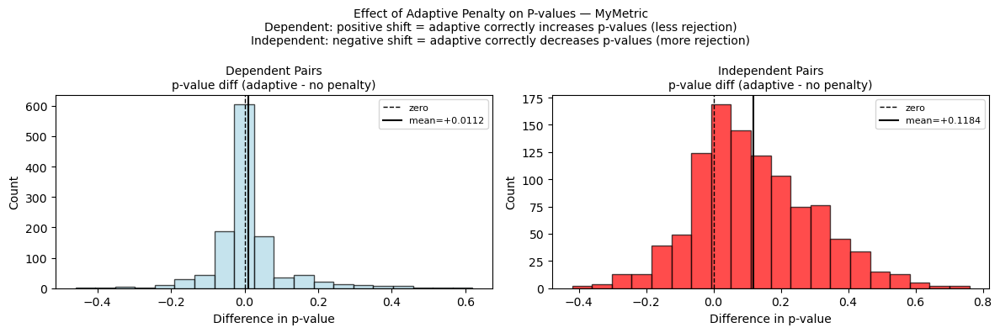

         group  dependence  mean_diff     n  pct_positive  pct_negative
0    dependent           1   0.011233  1200      0.357500      0.344167
1  independent           0   0.118438  1050      0.710476      0.232381


In [ ]:
# --- Usage ---
df_summary = plot_pvalue_differences(
    df_pvalues_adaptive, 
    df_pvalues_no, 
    title_suffix="— MyMetric"
)
print(df_summary)

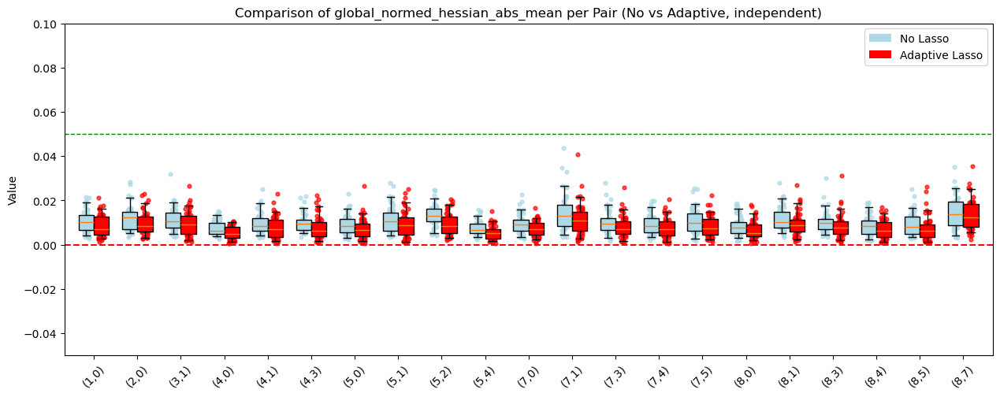

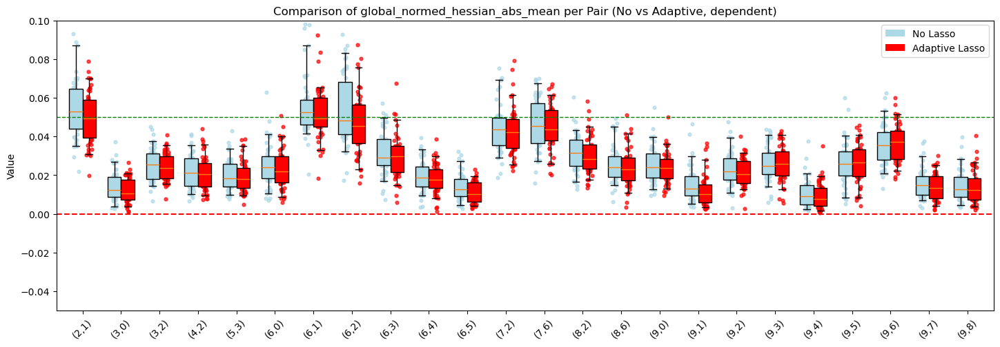

In [ ]:
plot_metric_values_no_vs_adaptive(
table_original_dict_no,
table_original_dict_adaptive,
    df_structure,
    metric='global_normed_hessian_abs_mean',
    plot_dependence="independent",
    ylim=(-0.05, 0.1)
)

plot_metric_values_no_vs_adaptive(
table_original_dict_no,
table_original_dict_adaptive,
    df_structure,
    metric='global_normed_hessian_abs_mean',
    plot_dependence="dependent",
    ylim=(-0.05, 0.1)
)

#### Seed 1 C-Vine

In [ ]:
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = "cvine_10D_125obs_bootstrap_s1", 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=1,
                                                                                                                                              vine_type="C-Vine",
                                                                                                                                              Independence_tree=3)

table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(subset_no_original, subset_no_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(subset_adaptive_original, subset_adaptive_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49]
There are  50 nmber of unique seeds.


Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


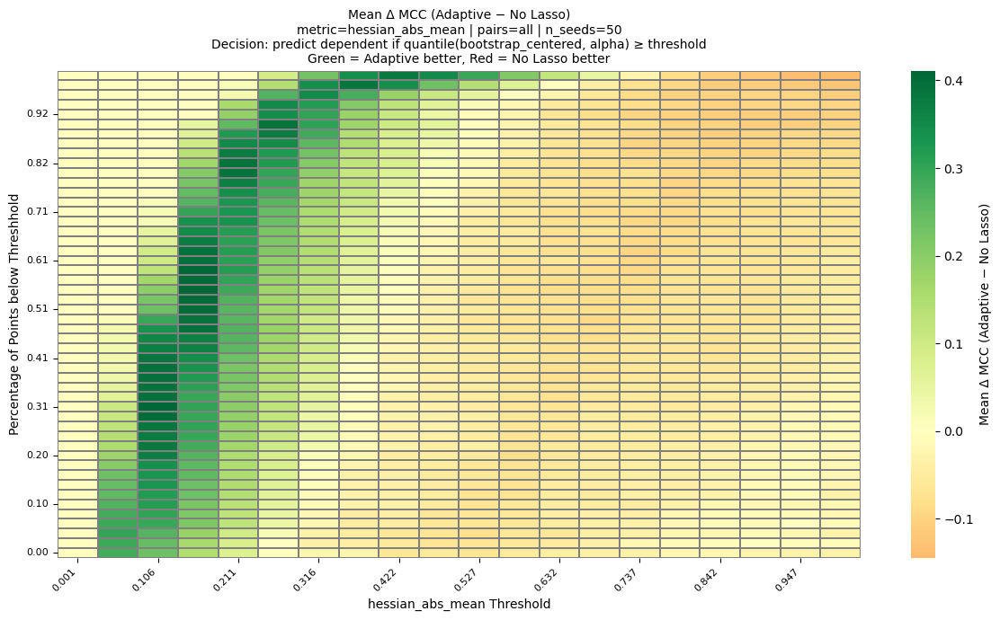

In [ ]:
_ = plot_heatmap_score_diff_threshold_vs_alpha(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    alphas=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    n_thresholds=30,             # number of threshold grid points if not provided
    n_alphas=20,                 # number of alpha grid points if not provided
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
)

Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


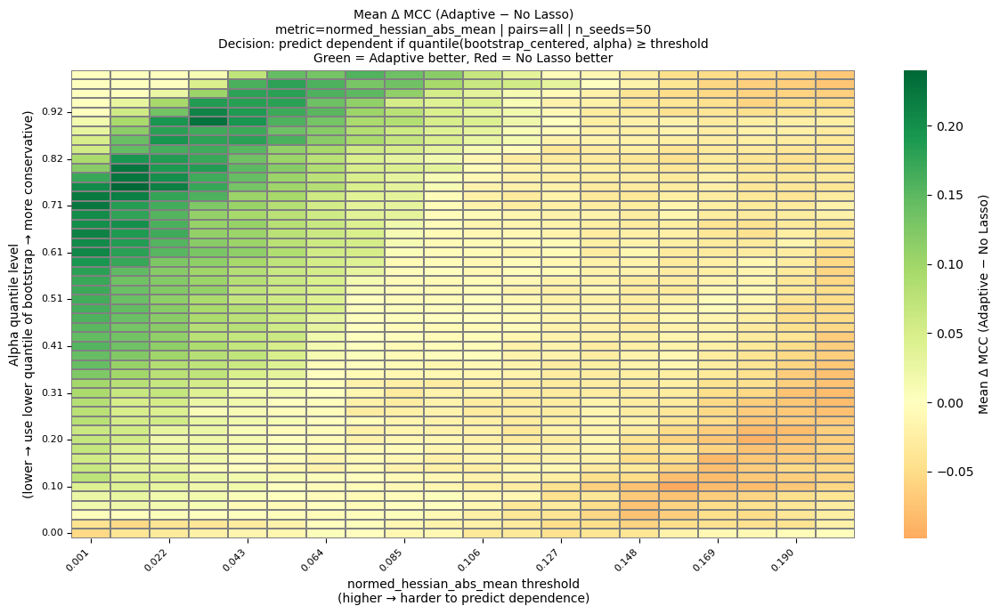

In [ ]:
_ = plot_heatmap_score_diff_threshold_vs_alpha(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.2,20),             # grid of metric thresholds (x-axis of heatmap)
    alphas=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    n_thresholds=30,             # number of threshold grid points if not provided
    n_alphas=20,                 # number of alpha grid points if not provided
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
)

Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


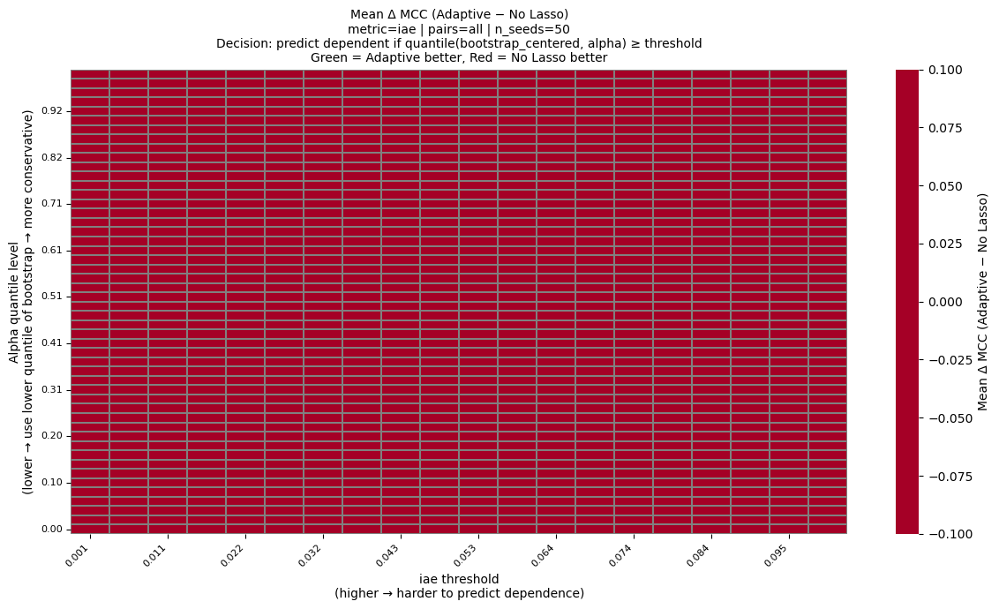

In [ ]:
_ = plot_heatmap_score_diff_threshold_vs_alpha(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="iae",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    alphas=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    n_thresholds=30,             # number of threshold grid points if not provided
    n_alphas=20,                 # number of alpha grid points if not provided
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
)

##### hessian_abs_mean

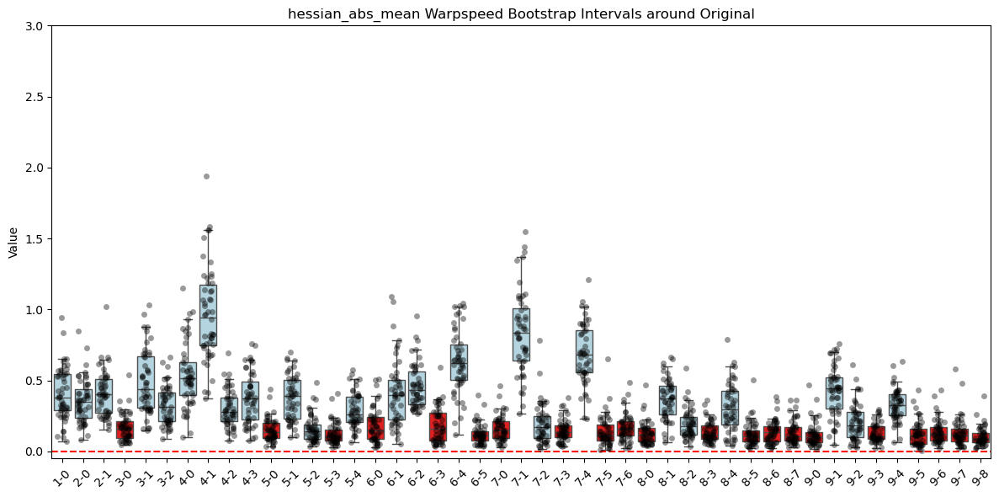

In [ ]:
df_pvalues_no = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_no, table_diffs_list_no, df_structure, metric="hessian_abs_mean", ylim=(-0.05, 3), n=125)

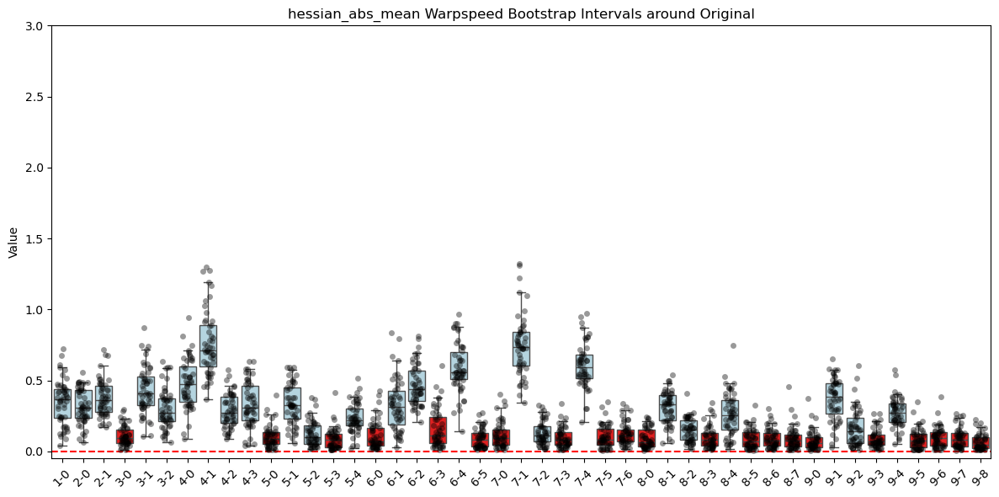

In [ ]:
df_pvalues_adaptive = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_adaptive, table_diffs_list_adaptive, df_structure, metric="hessian_abs_mean", ylim=(-0.05, 3), n=125)

P-value Differences: Adaptive - No Penalty
Metric: — MyMetric
Dependent   pairs | mean diff: +0.0000  (n=1200)
Independent pairs | mean diff: -0.0000  (n=1050)


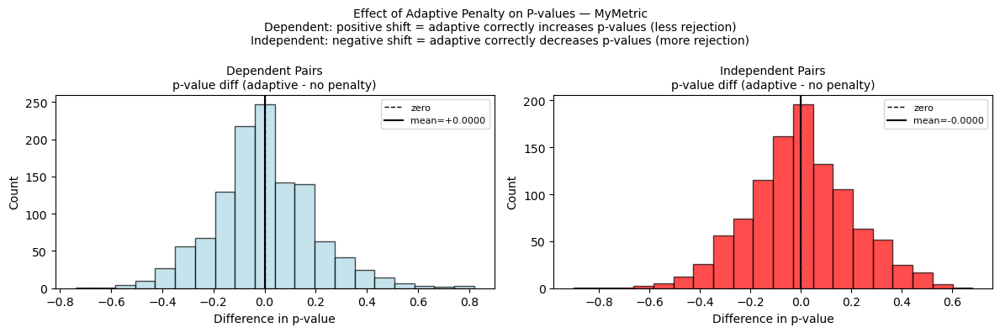

         group  dependence     mean_diff     n  pct_positive  pct_negative
0    dependent           1  4.625929e-20  1200      0.440000      0.485833
1  independent           0 -1.480297e-18  1050      0.462857      0.486667


In [ ]:
# --- Usage ---
df_summary = plot_pvalue_differences(
    df_pvalues_adaptive, 
    df_pvalues_no, 
    title_suffix="— MyMetric"
)
print(df_summary)

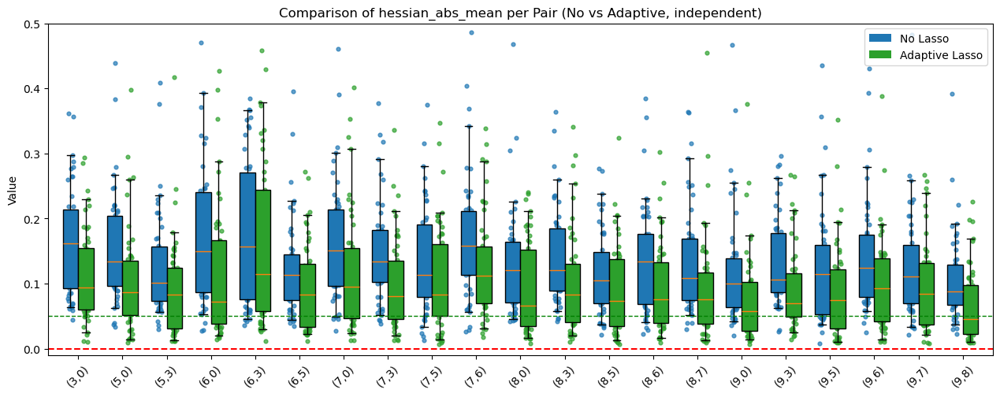

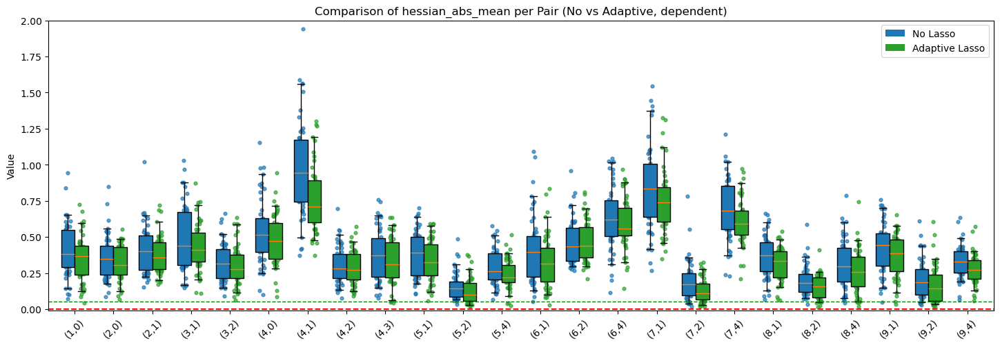

In [ ]:
plot_metric_values_no_vs_adaptive(
table_original_dict_no,
table_original_dict_adaptive,
    df_structure,
    metric='hessian_abs_mean',
    plot_dependence="independent",
    ylim=(-0.01, 0.5)
)

plot_metric_values_no_vs_adaptive(
table_original_dict_no,
table_original_dict_adaptive,
    df_structure,
    metric='hessian_abs_mean',
    plot_dependence="dependent",
    ylim=(-0.01, 2)
)

##### normed_hessian_abs_mean

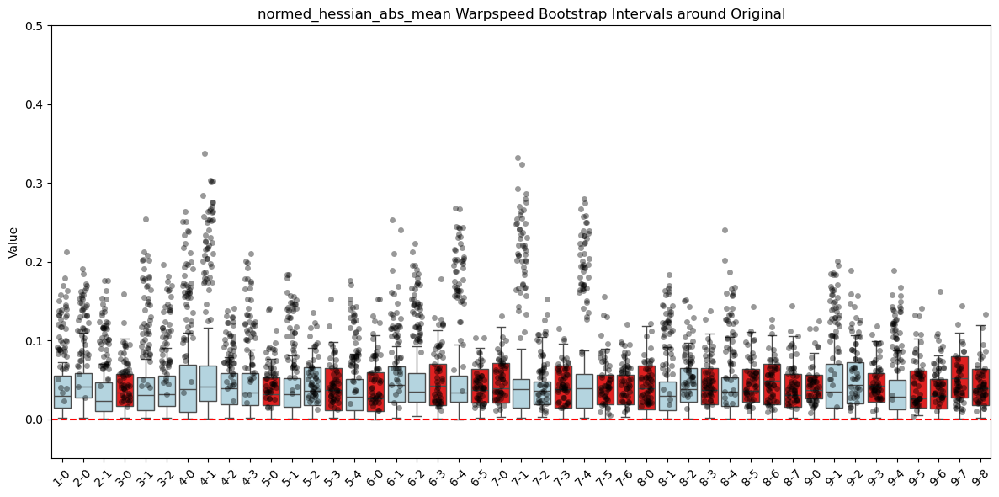

In [ ]:
df_pvalues_no = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_no, table_diffs_list_no, df_structure, metric="normed_hessian_abs_mean", ylim=(-0.05, 0.5), n=125)

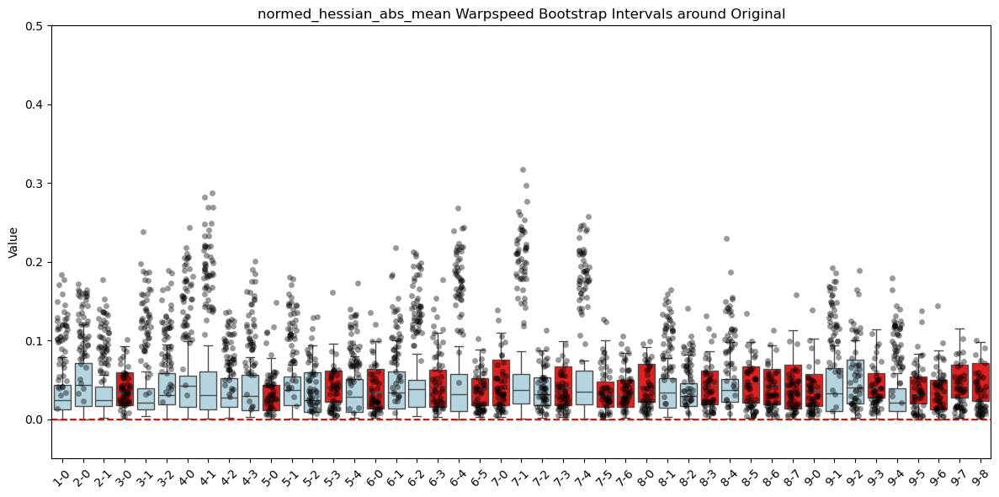

In [ ]:
df_pvalues_adaptive = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_adaptive, table_diffs_list_adaptive, df_structure, metric="normed_hessian_abs_mean", ylim=(-0.05, 0.5), n=125)

P-value Differences: Adaptive - No Penalty
Metric: — MyMetric
Dependent   pairs | mean diff: +0.0179  (n=1200)
Independent pairs | mean diff: +0.1383  (n=1050)


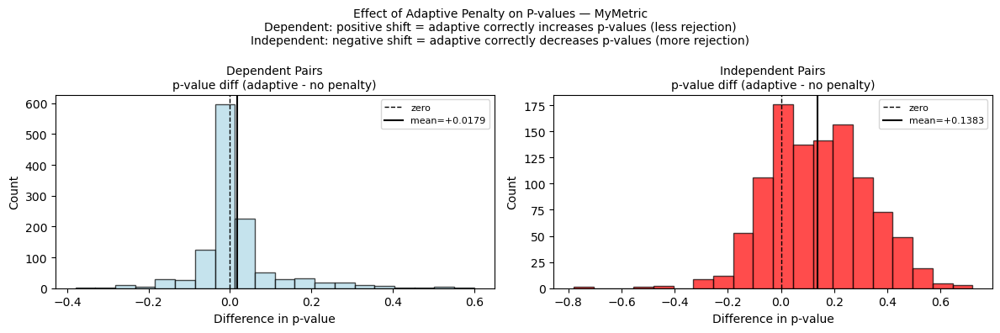

         group  dependence  mean_diff     n  pct_positive  pct_negative
0    dependent           1   0.017917  1200      0.337500      0.250833
1  independent           0   0.138286  1050      0.734286      0.217143


In [ ]:
# --- Usage ---
df_summary = plot_pvalue_differences(
    df_pvalues_adaptive, 
    df_pvalues_no, 
    title_suffix="— MyMetric"
)
print(df_summary)

##### global_normed_hessian_abs_mean

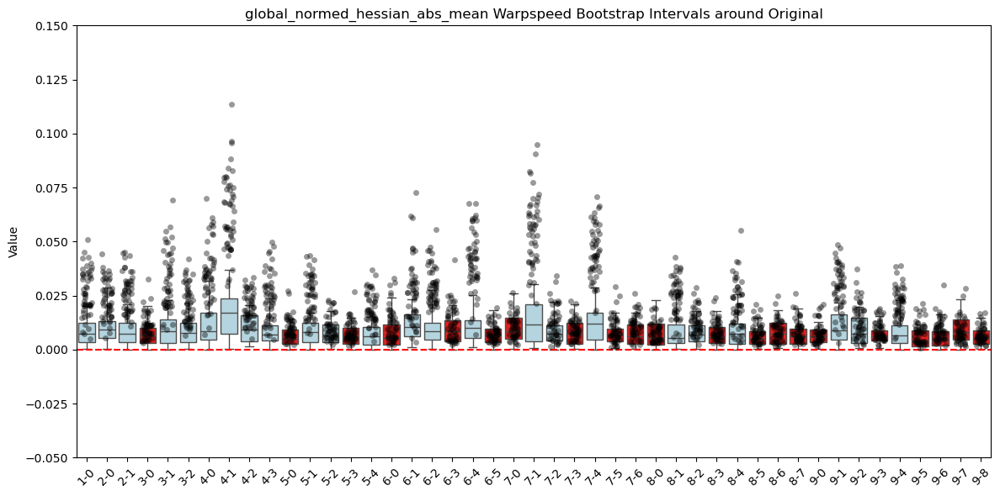

In [ ]:
df_pvalues_no = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_no, table_diffs_list_no, df_structure, metric="global_normed_hessian_abs_mean", ylim=(-0.05, 0.15), n=125)

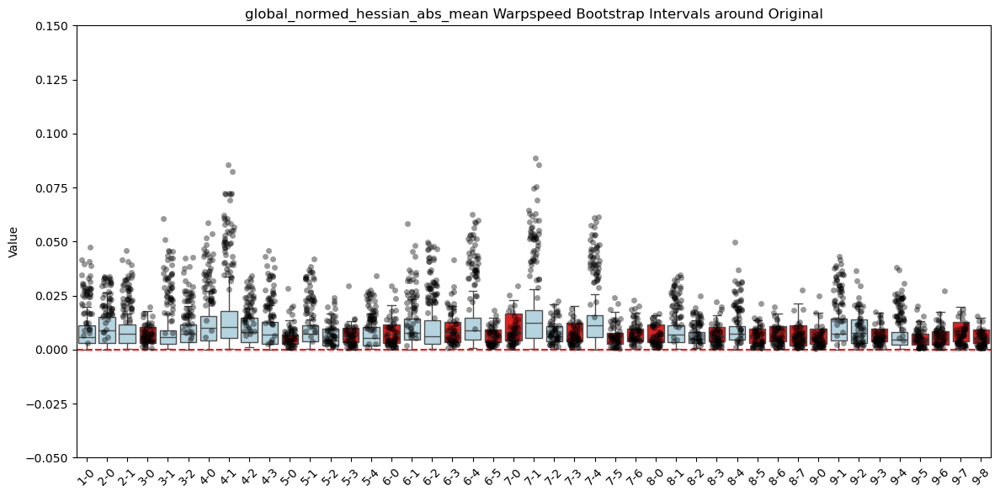

In [ ]:
df_pvalues_adaptive = plot_metric_bootstrap_interval_test_for_each_seed(table_original_dict_adaptive, table_diffs_list_adaptive, df_structure, metric="global_normed_hessian_abs_mean", ylim=(-0.05, 0.15), n=125)

P-value Differences: Adaptive - No Penalty
Metric: — MyMetric
Dependent   pairs | mean diff: +0.0096  (n=1200)
Independent pairs | mean diff: +0.1415  (n=1050)


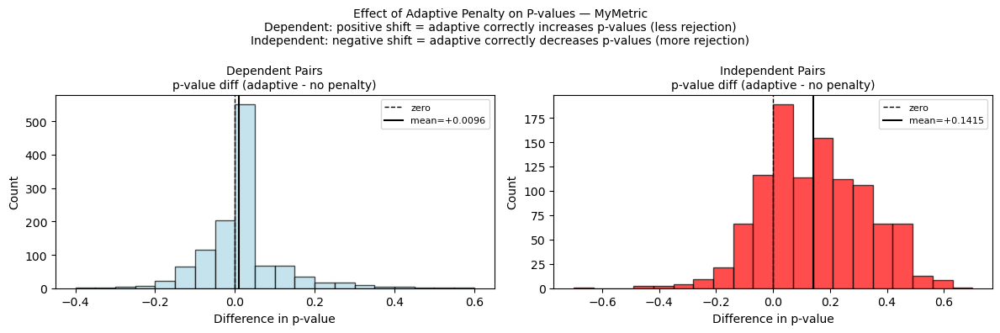

         group  dependence  mean_diff     n  pct_positive  pct_negative
0    dependent           1   0.009617  1200       0.34500      0.352500
1  independent           0   0.141543  1050       0.73619      0.210476


In [ ]:
# --- Usage ---
df_summary = plot_pvalue_differences(
    df_pvalues_adaptive, 
    df_pvalues_no, 
    title_suffix="— MyMetric"
)
print(df_summary)

(array([ 64.,  98., 119.,  65., 116., 140., 104.,  93., 138., 113.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

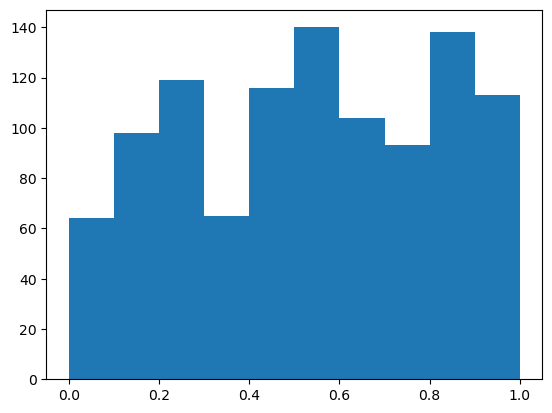

In [ ]:
plt.hist(df_pvalues_adaptive["p_value"][df_pvalues_adaptive["dependence"]==0])

(array([109., 149., 152., 128., 152., 128., 107.,  84.,  31.,  10.]),
 array([0.   , 0.098, 0.196, 0.294, 0.392, 0.49 , 0.588, 0.686, 0.784,
        0.882, 0.98 ]),
 <BarContainer object of 10 artists>)

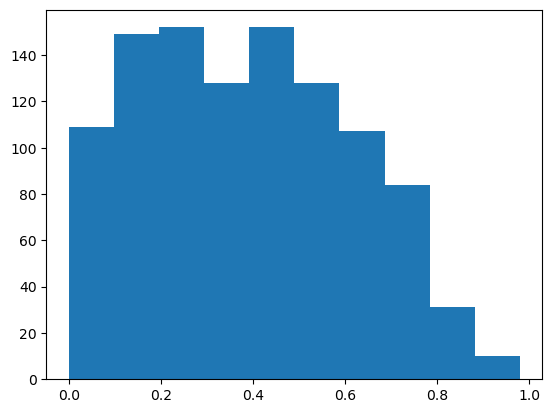

In [ ]:
plt.hist(df_pvalues_no["p_value"][df_pvalues_no["dependence"]==0])

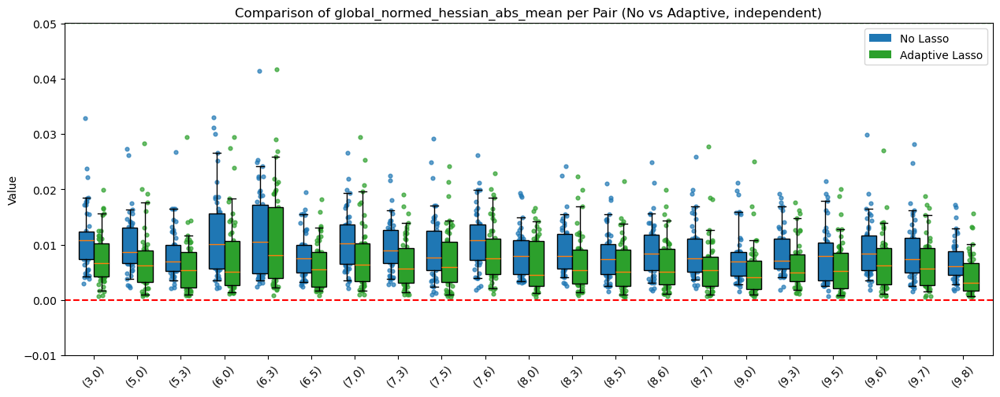

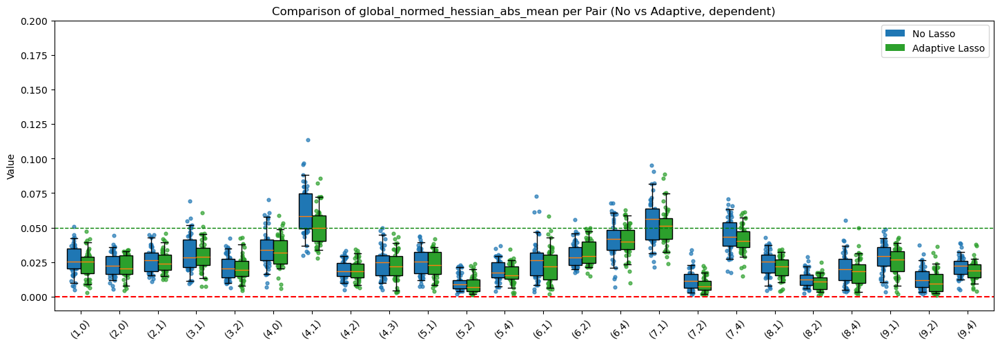

In [ ]:
plot_metric_values_no_vs_adaptive(
table_original_dict_no,
table_original_dict_adaptive,
    df_structure,
    metric='global_normed_hessian_abs_mean',
    plot_dependence="independent",
    ylim=(-0.01, 0.05)
)

plot_metric_values_no_vs_adaptive(
table_original_dict_no,
table_original_dict_adaptive,
    df_structure,
    metric='global_normed_hessian_abs_mean',
    plot_dependence="dependent",
    ylim=(-0.01, 0.2)
)

#### D-Vine S1

In [ ]:
#### Missing the Adaptive Runs!!!!!

subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = "dvine_10D_125obs_bootstrap_s1", 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=1,
                                                                                                                                              vine_type="D-Vine",
                                                                                                                                              Independence_tree=3)

table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(subset_no_original, subset_no_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(subset_adaptive_original, subset_adaptive_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

KeyError: 'tags.seed_value'

### Seeds 2 and 3

#### R-Vine

##### normal

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
There are  100 nmber of unique seeds.
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix

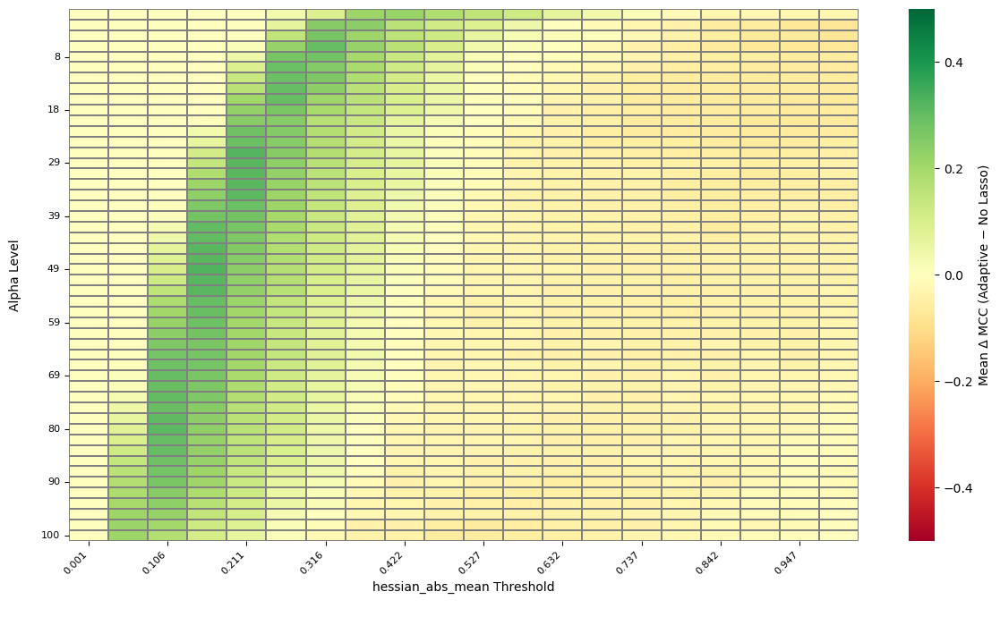

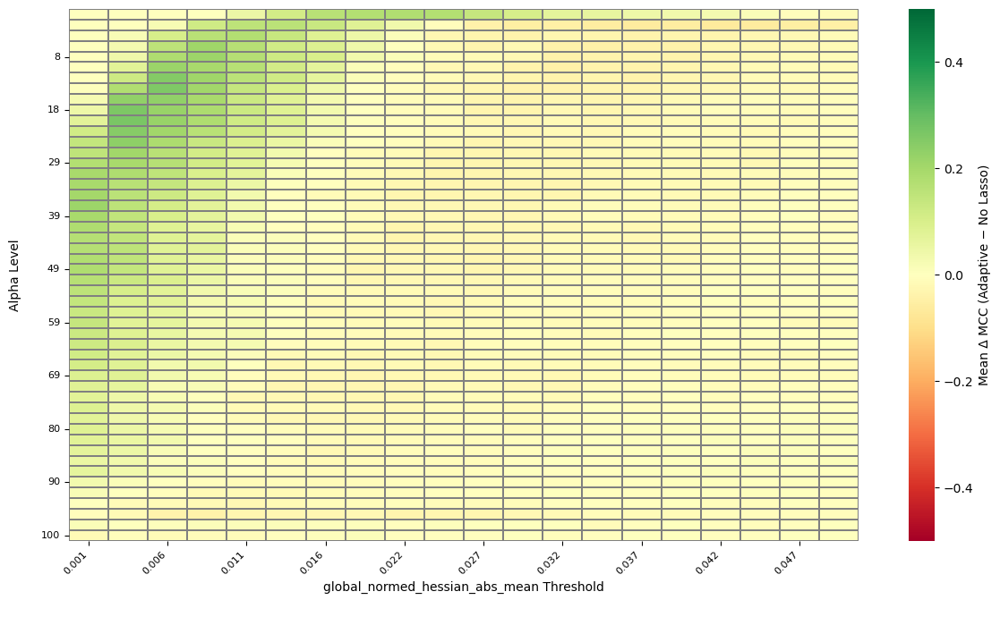

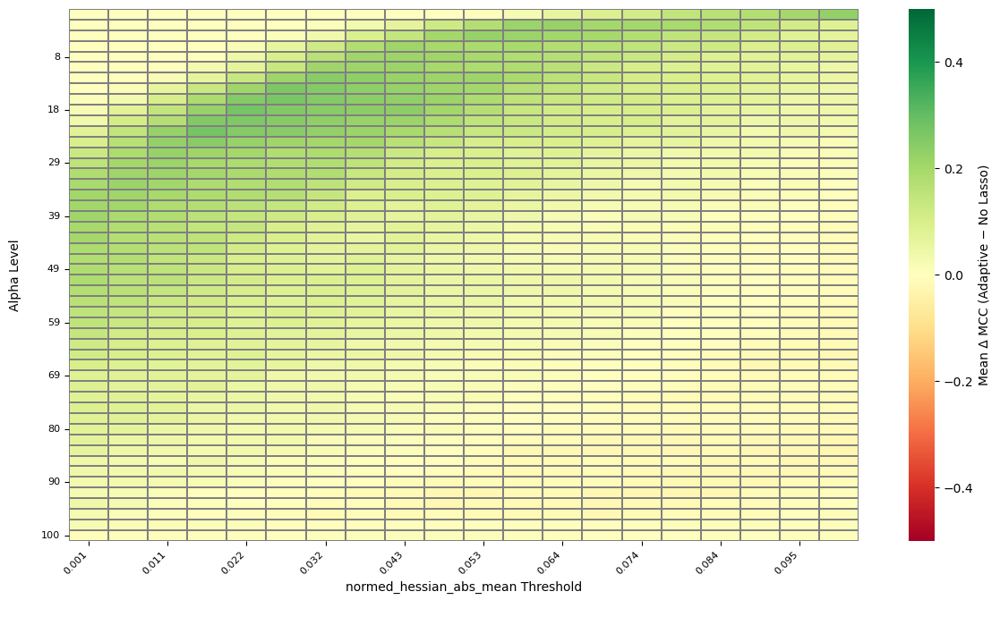

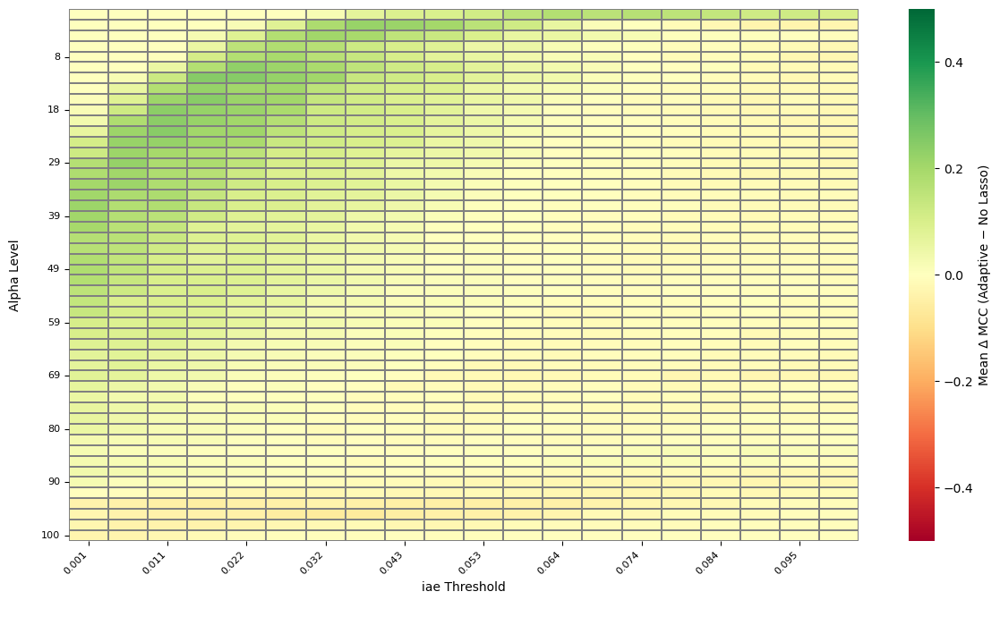

In [ ]:
experiment_name = "rvine_10D_125obs_bootstrap_s2"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=2,
                                                                                                                                              vine_type="R-Vine",
                                                                                                                                              Independence_tree=3)

table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(subset_no_original, subset_no_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(subset_adaptive_original, subset_adaptive_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=True
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="global_normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.03,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=True
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_global_normed_hessian_abs_mean.png")


_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=True
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_normed_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="iae",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=True
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_iae.png")

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
There are  100 nmber of unique seeds.
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix

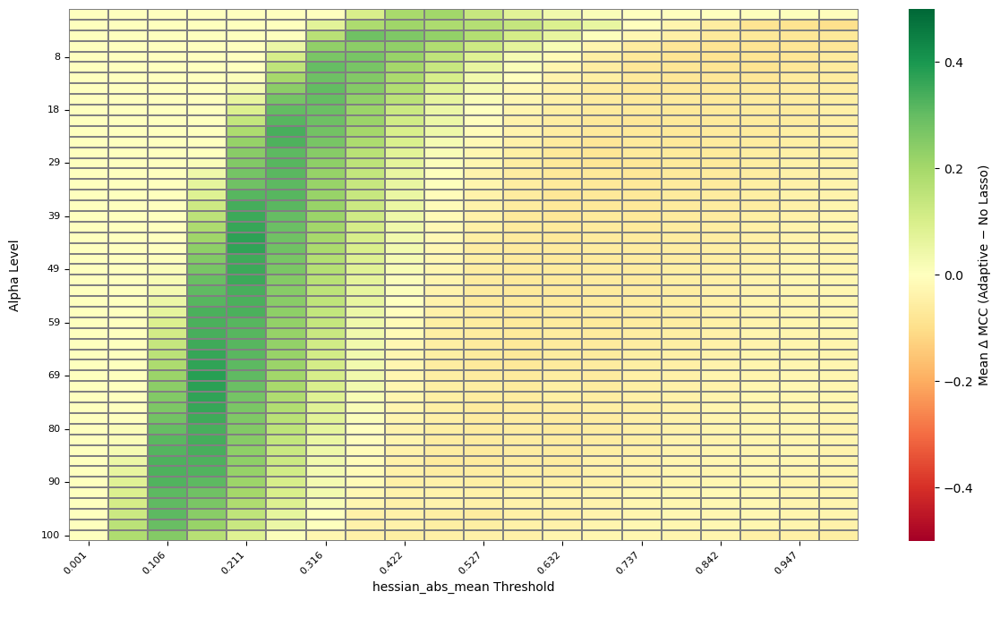

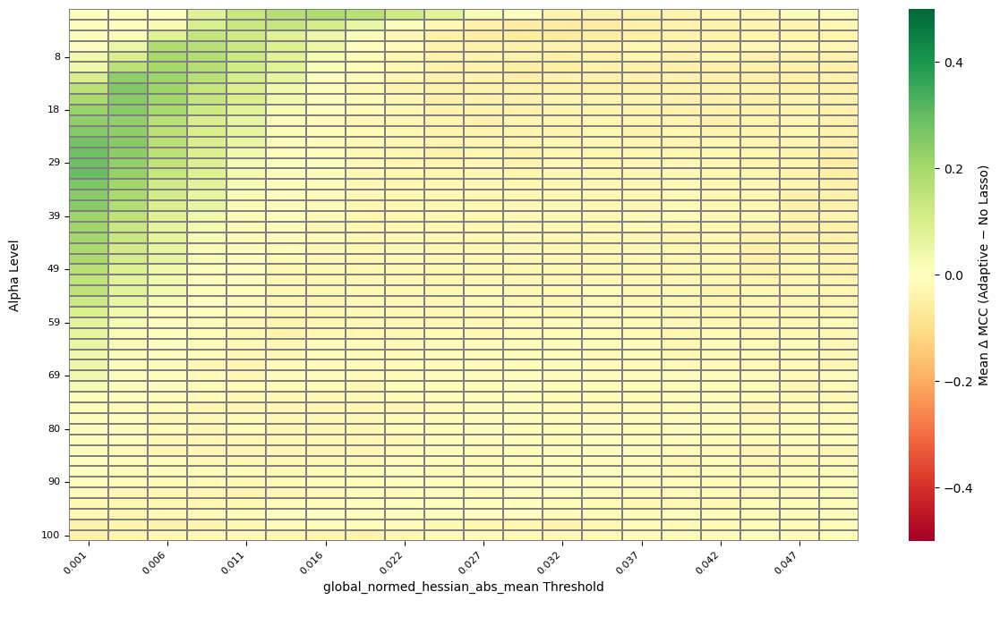

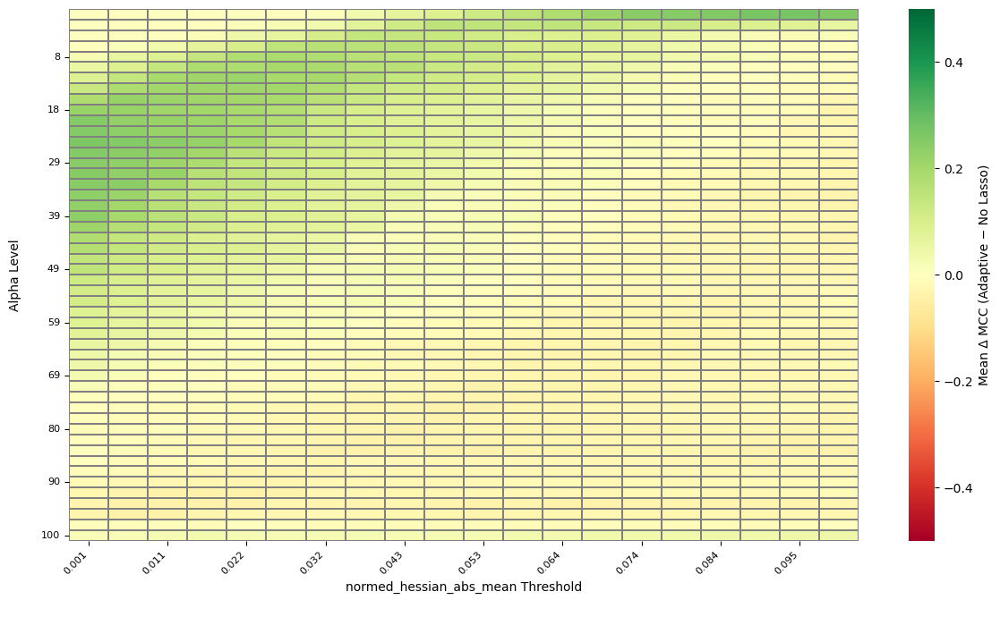

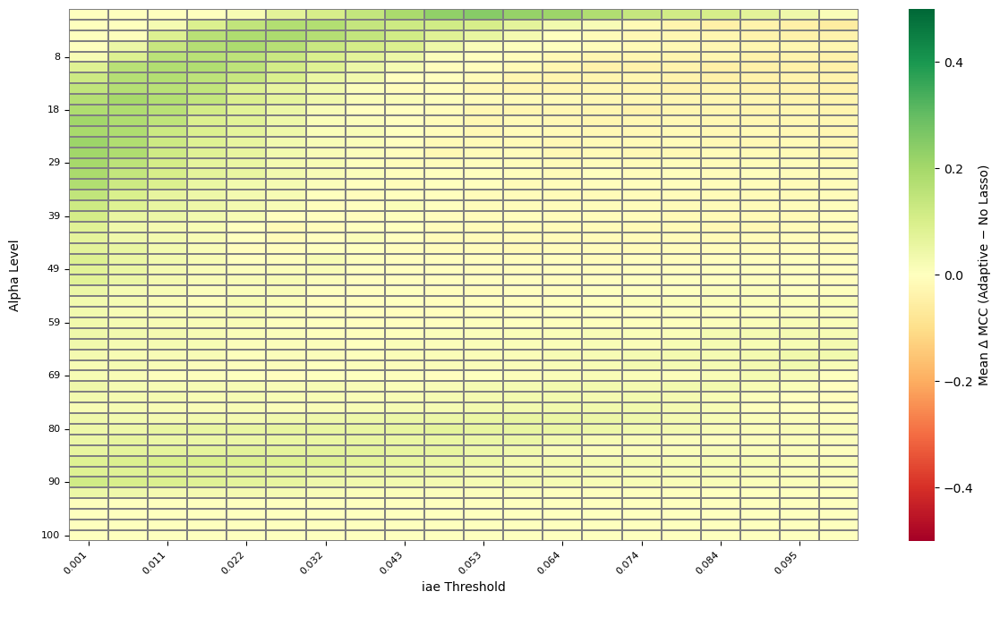

In [ ]:
experiment_name = "rvine_10D_125obs_bootstrap_s3"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=3,
                                                                                                                                              vine_type="R-Vine",
                                                                                                                                              Independence_tree=3)

table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(subset_no_original, subset_no_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(subset_adaptive_original, subset_adaptive_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=True
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="global_normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.03,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=True
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_global_normed_hessian_abs_mean.png")


_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=True
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_normed_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="iae",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=True
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_iae.png")

##### strong

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
There are  100 nmber of unique seeds.
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix

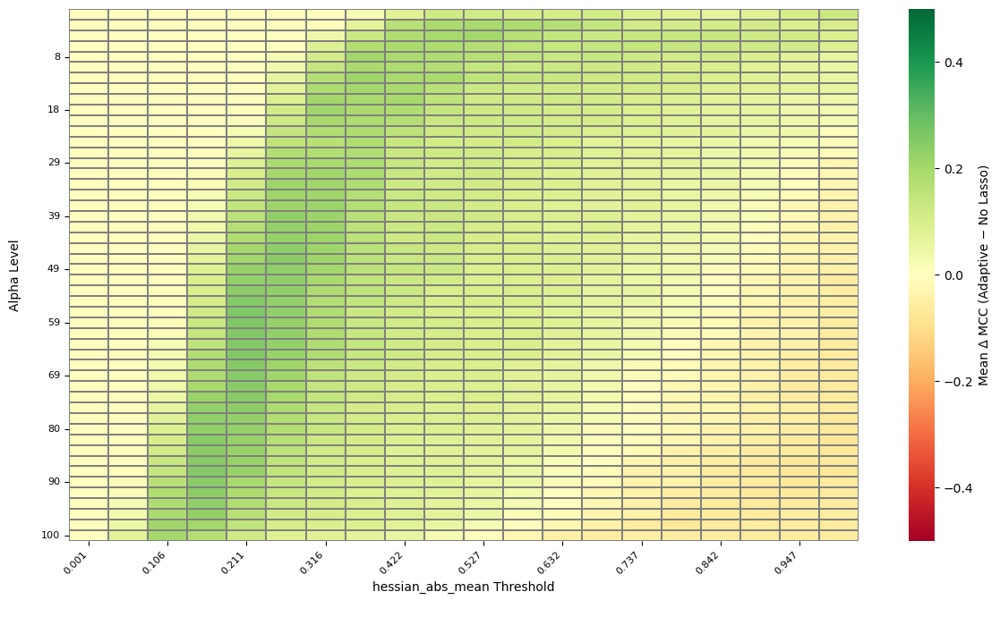

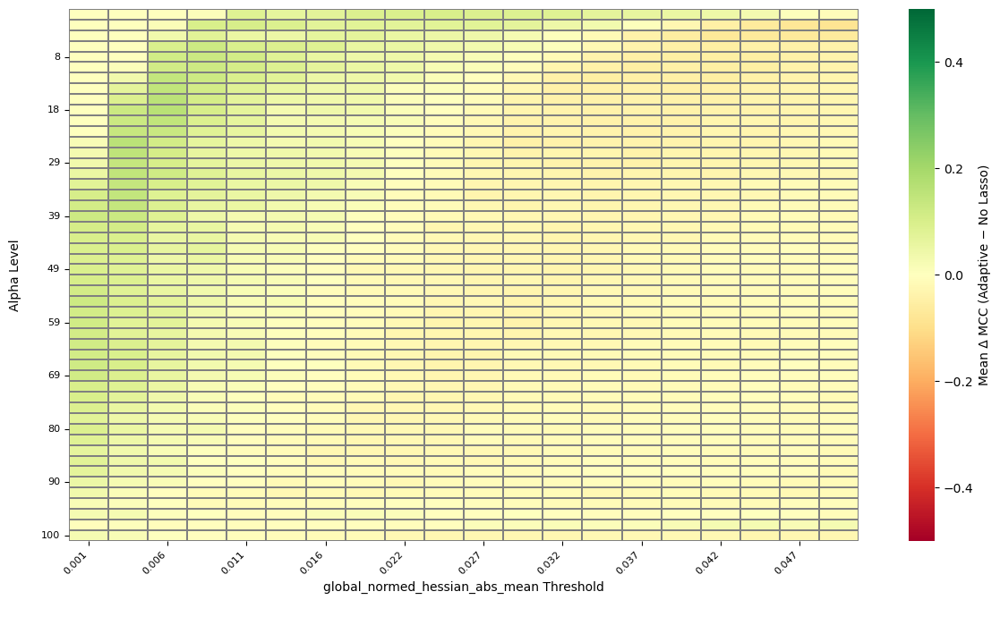

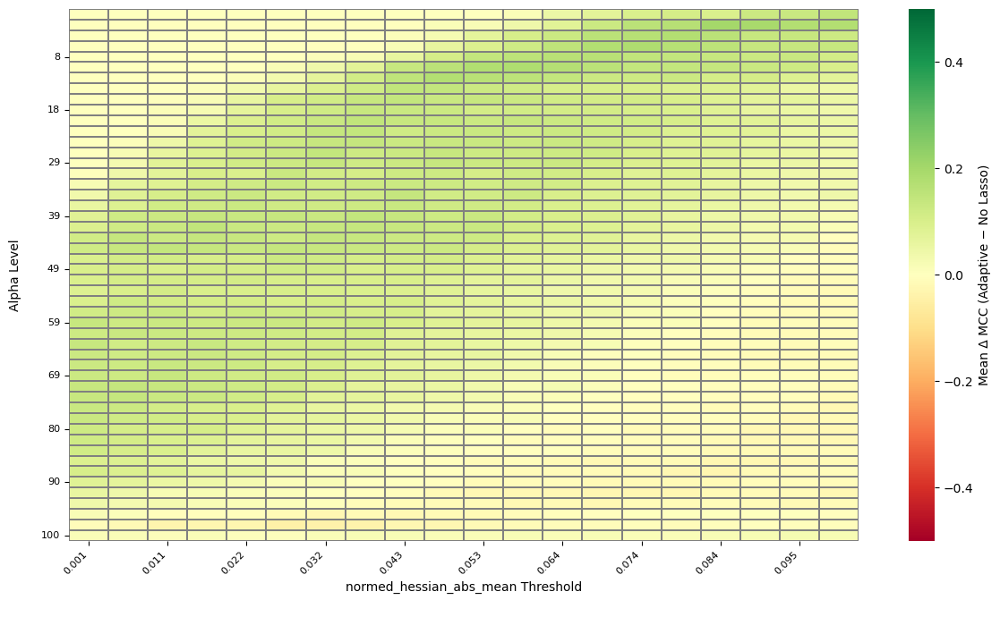

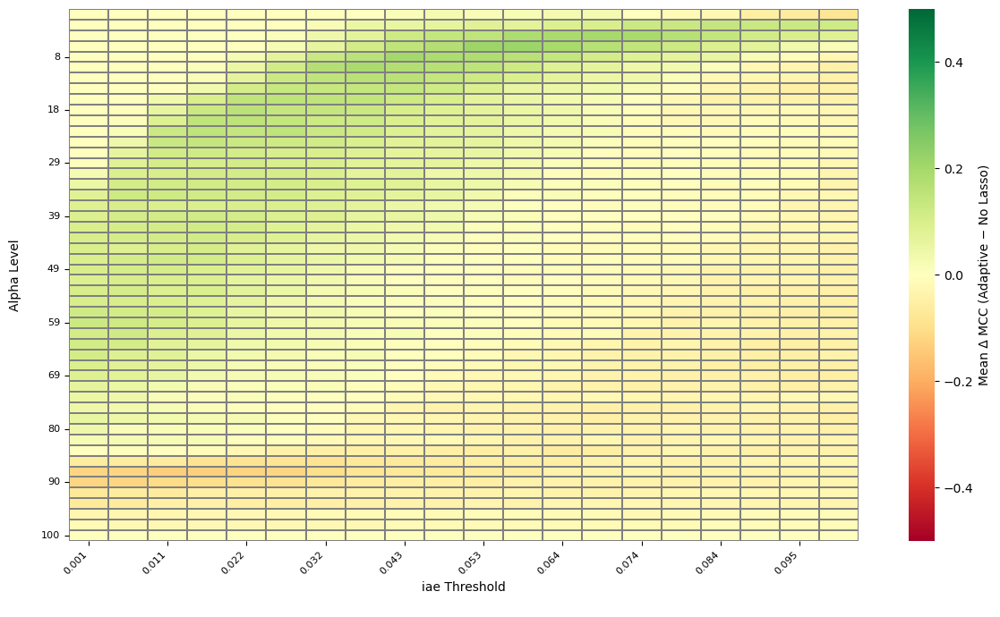

In [ ]:
experiment_name = "rvine_strong_10D_125obs_bootstrap_s2"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=2,
                                                                                                                                              vine_type="R-Vine",
                                                                                                                                              Independence_tree=3)

table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(subset_no_original, subset_no_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(subset_adaptive_original, subset_adaptive_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=True
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="global_normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.03,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=True
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_global_normed_hessian_abs_mean.png")


_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=True
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_normed_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="iae",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=True
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_iae.png")

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [  0   1   2   3   4   5   6   7   8  10  11  12  13  14  15  16  17  18
  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36
  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54
  55  56  57  58  59  60  61  62  63  64  65  66  67  68  70  71  72  73
  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90  91
  92  93  94  95  96  97  98  99 100 101]
There are  100 nmber of unique seeds.
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bo

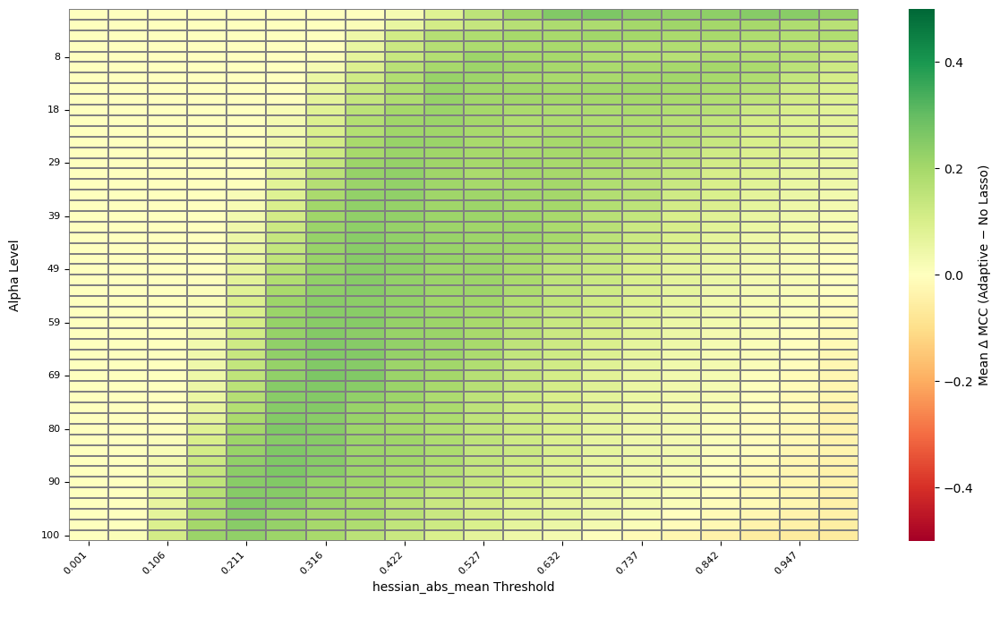

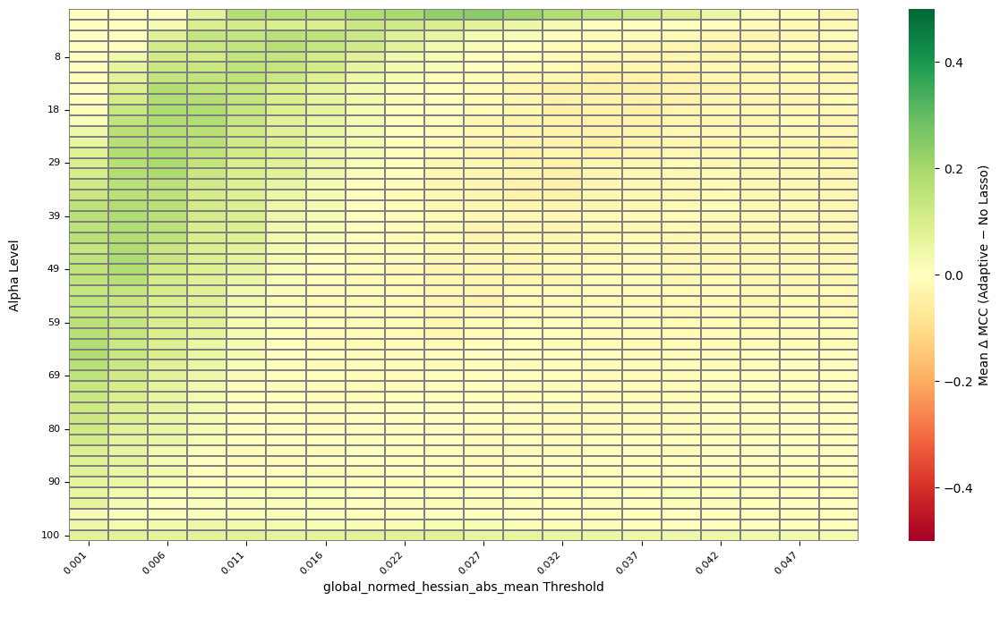

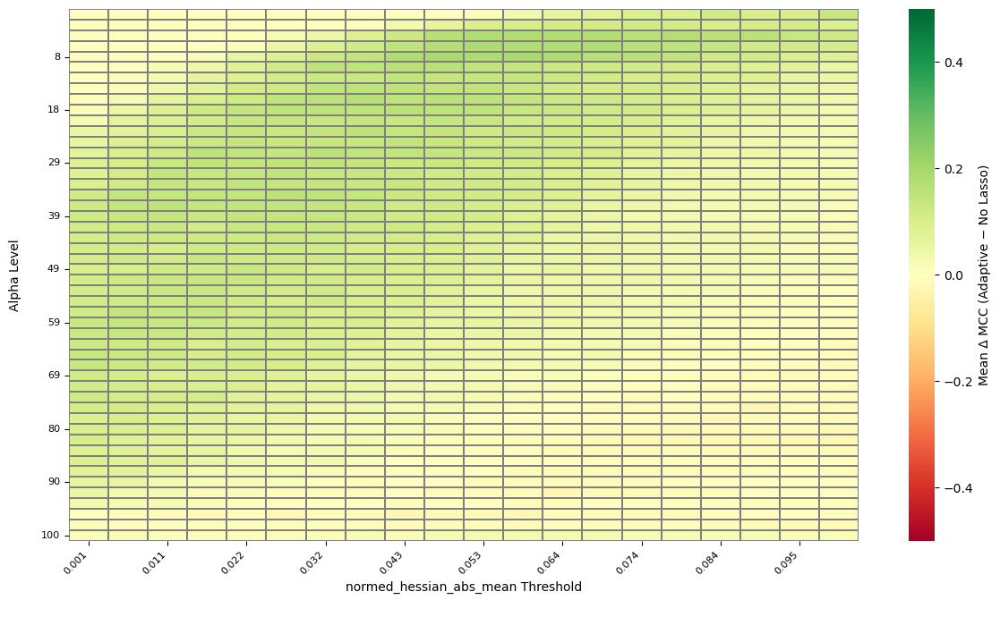

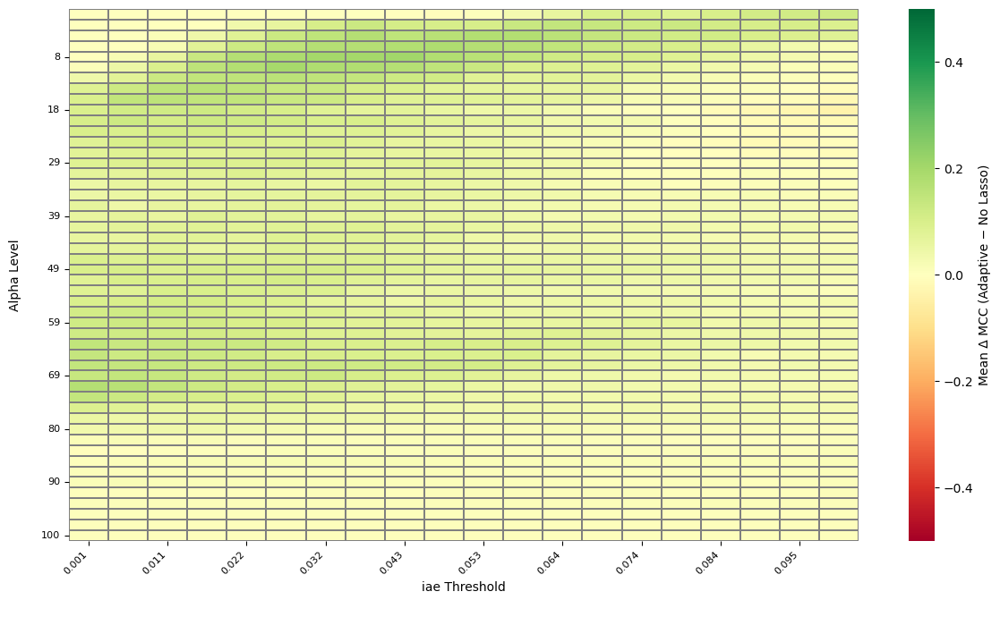

In [ ]:
experiment_name = "rvine_strong_10D_125obs_bootstrap_s3"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=3,
                                                                                                                                              vine_type="R-Vine",
                                                                                                                                              Independence_tree=3)

table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(subset_no_original, subset_no_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(subset_adaptive_original, subset_adaptive_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=True
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="global_normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.03,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=True
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_global_normed_hessian_abs_mean.png")


_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=True
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_normed_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="iae",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=True
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_iae.png")

#### D-Vine

##### normal

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
There are  100 nmber of unique seeds.
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix

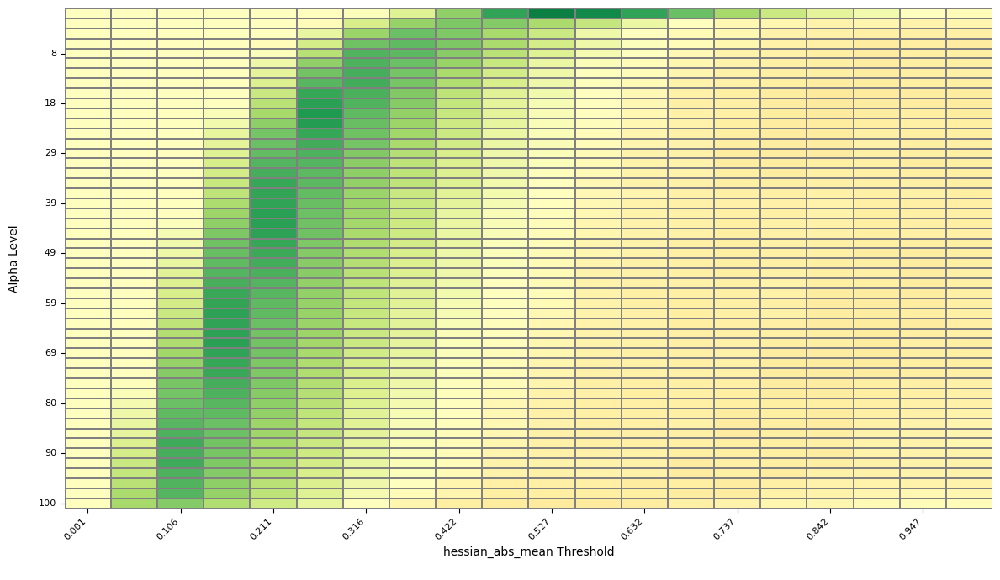

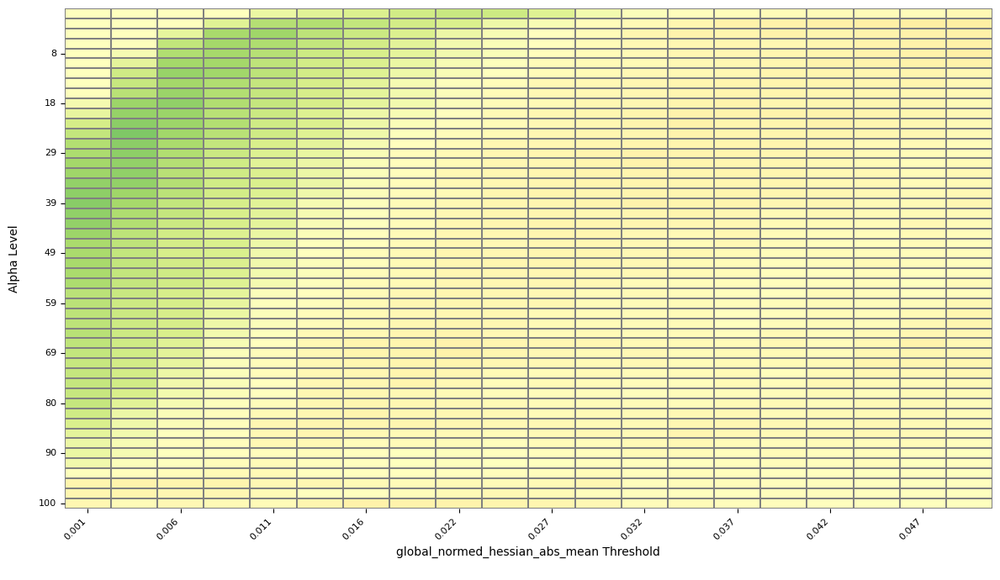

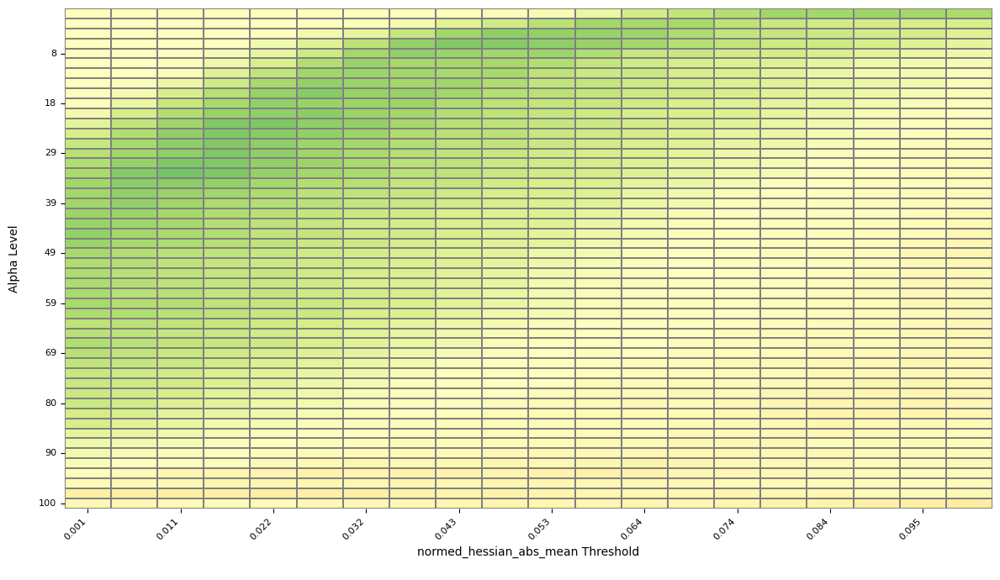

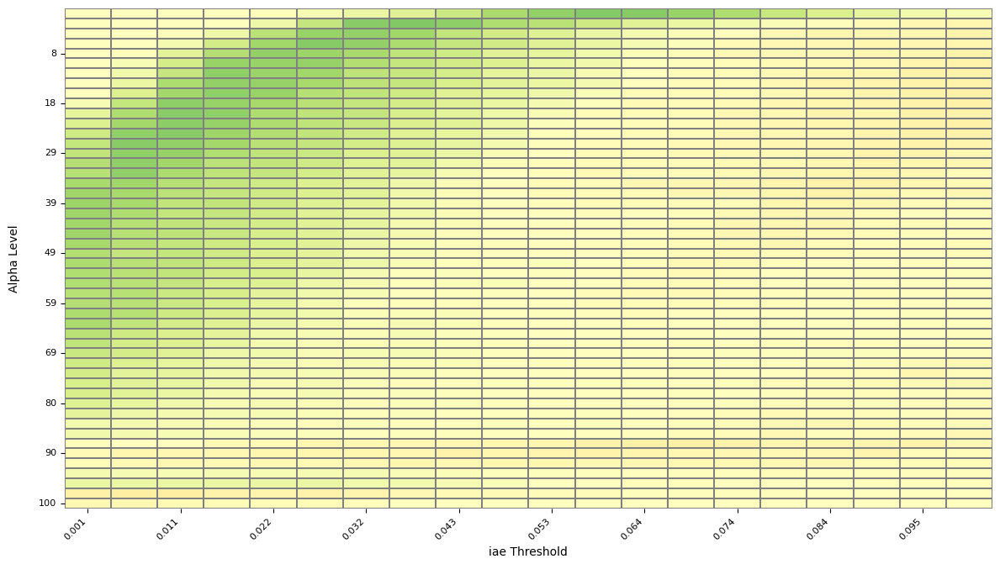

In [ ]:
experiment_name = "dvine_10D_125obs_bootstrap_s2"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=2,
                                                                                                                                              vine_type="D-Vine",
                                                                                                                                              Independence_tree=3)

table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(subset_no_original, subset_no_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(subset_adaptive_original, subset_adaptive_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])


_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="global_normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.03,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_global_normed_hessian_abs_mean.png")


_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_normed_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="iae",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_iae.png")

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
There are  100 nmber of unique seeds.
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix

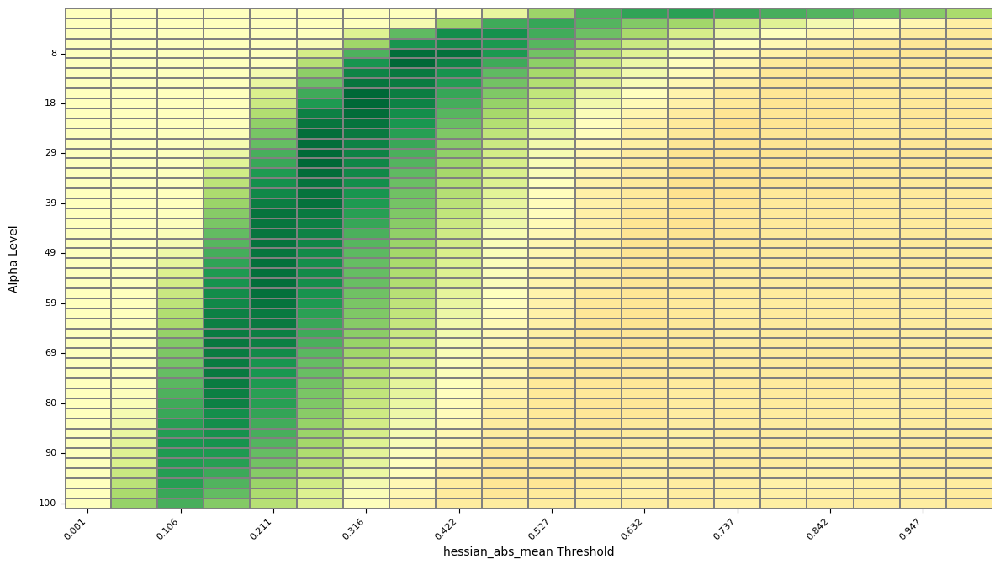

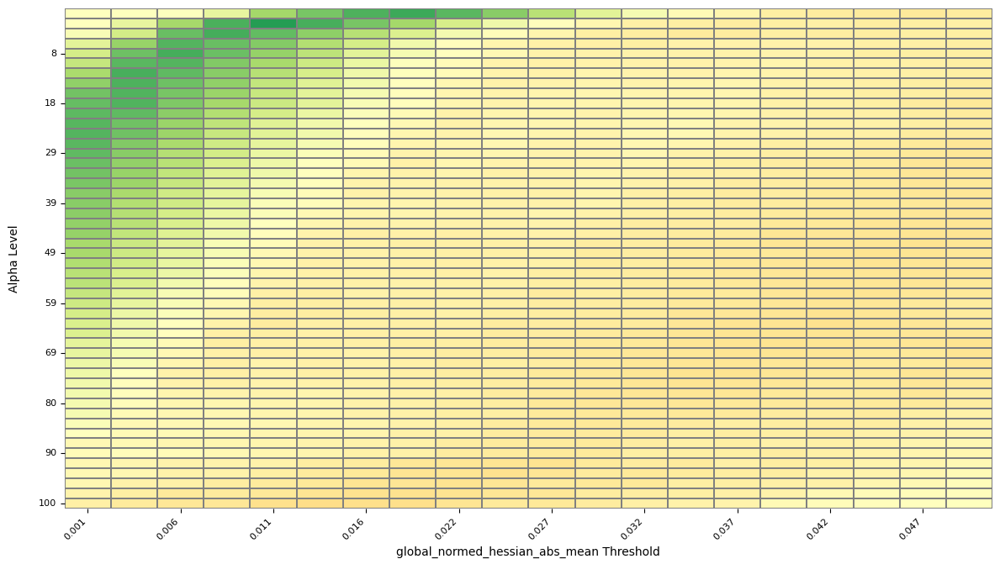

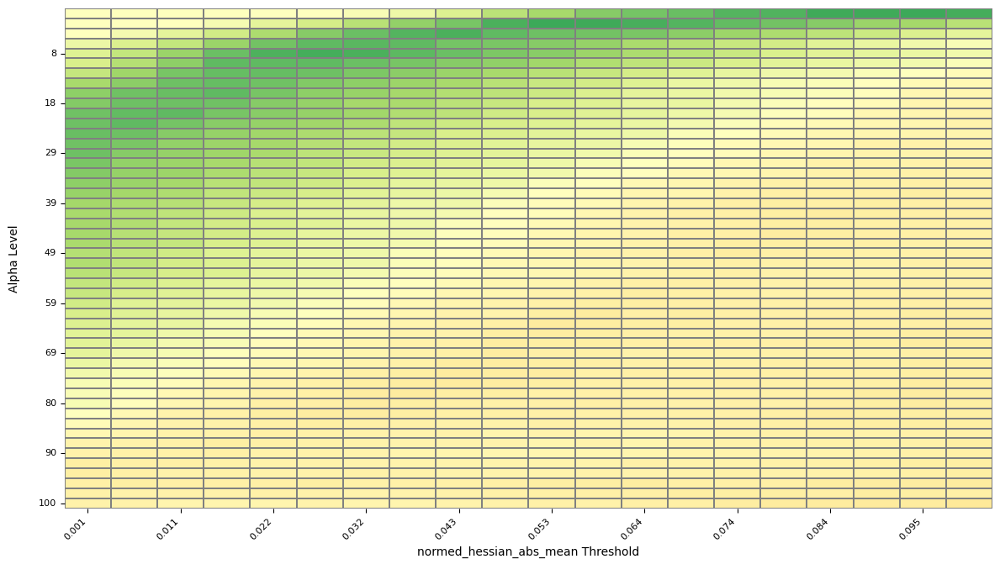

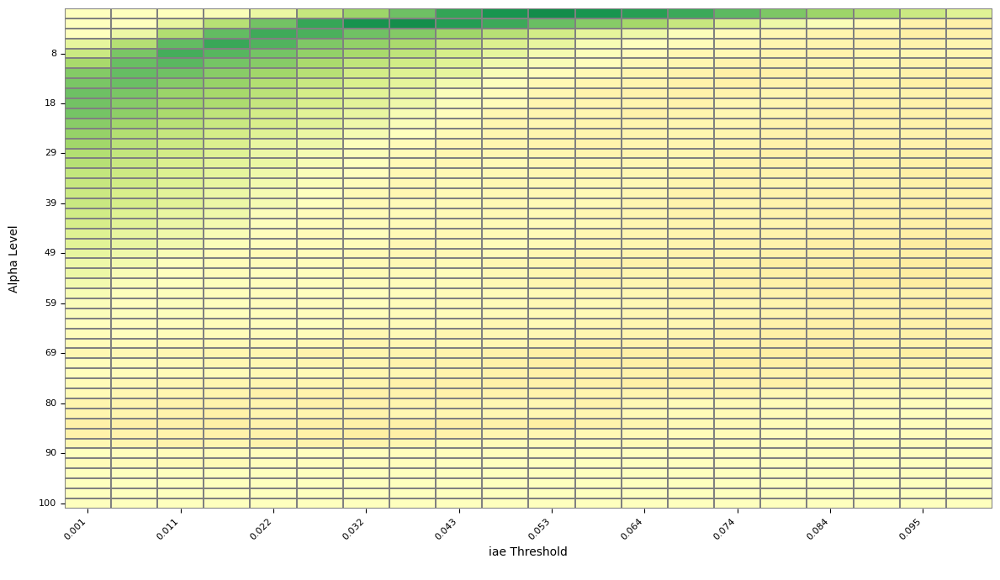

In [ ]:
experiment_name = "dvine_10D_125obs_bootstrap_s3"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=3,
                                                                                                                                              vine_type="D-Vine",
                                                                                                                                              Independence_tree=3)

table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(subset_no_original, subset_no_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(subset_adaptive_original, subset_adaptive_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])


_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="global_normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.03,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_global_normed_hessian_abs_mean.png")


_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_normed_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="iae",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_iae.png")

##### strong

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90
  91  92  93  94  95  96  97  98  99 100]
There are  100 nmber of unique seeds.
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bo

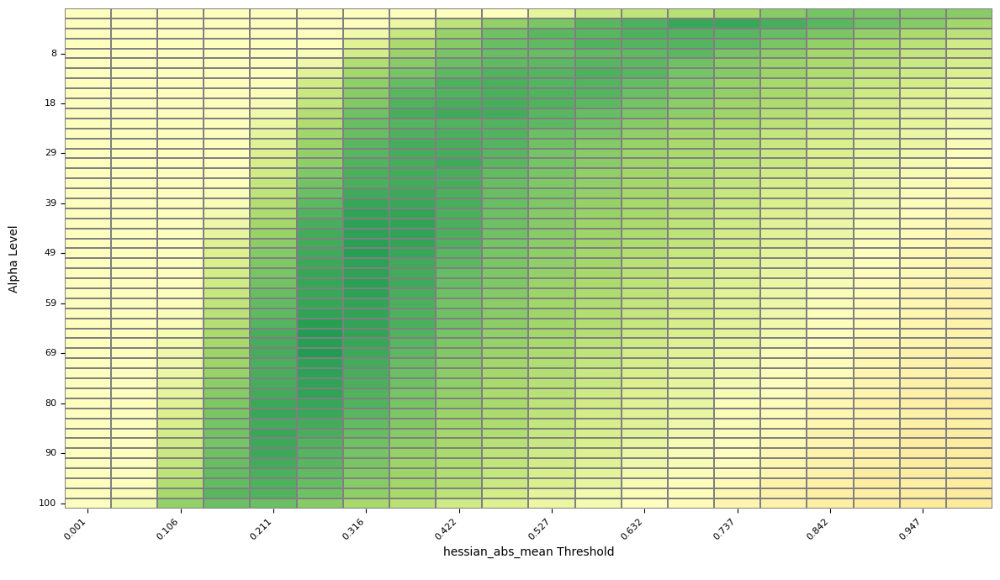

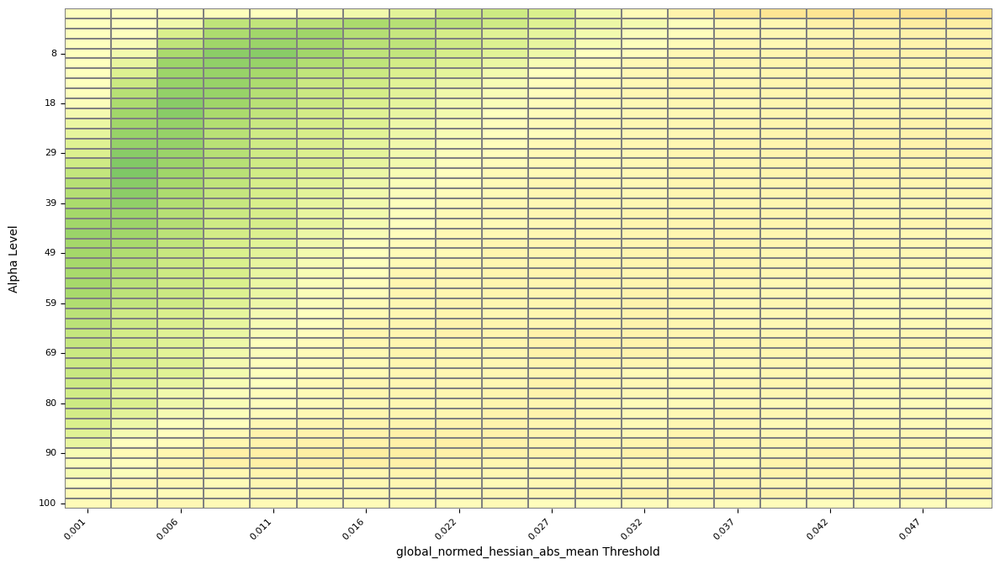

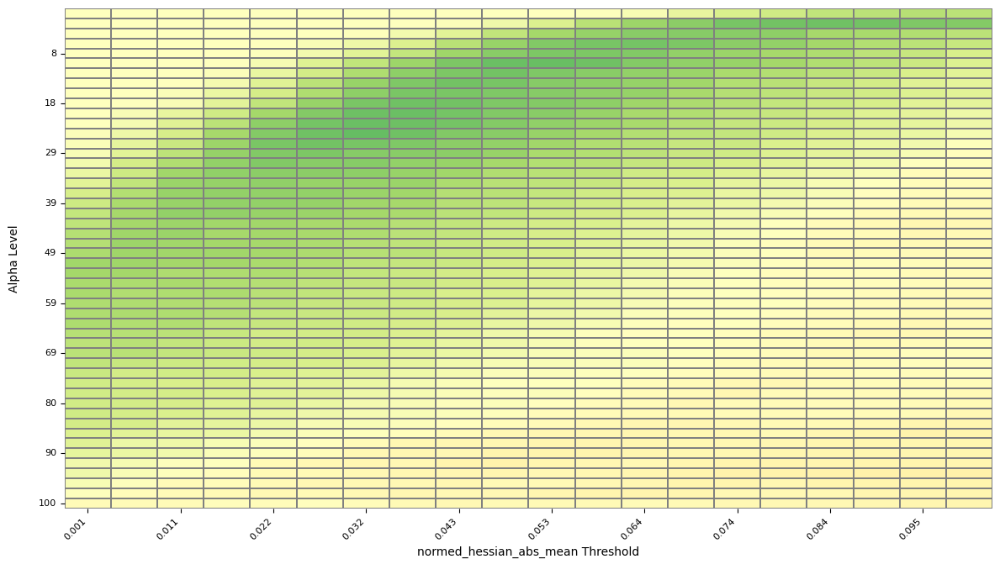

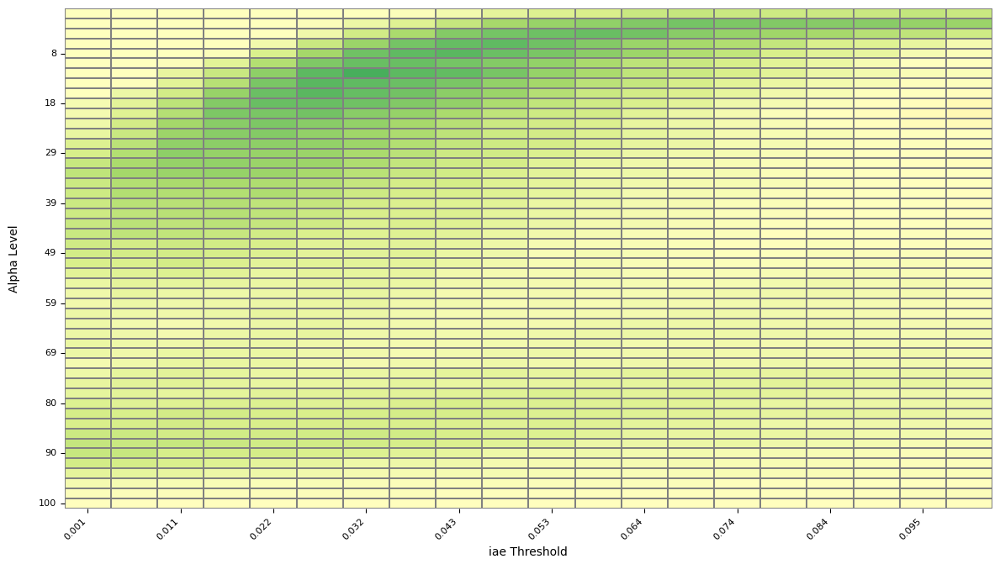

In [ ]:
experiment_name = "dvine_strong_10D_125obs_bootstrap_s2"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=2,
                                                                                                                                              vine_type="D-Vine",
                                                                                                                                              Independence_tree=3)

table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(subset_no_original, subset_no_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(subset_adaptive_original, subset_adaptive_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="global_normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.03,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_global_normed_hessian_abs_mean.png")


_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_normed_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="iae",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_iae.png")

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
There are  100 nmber of unique seeds.
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix

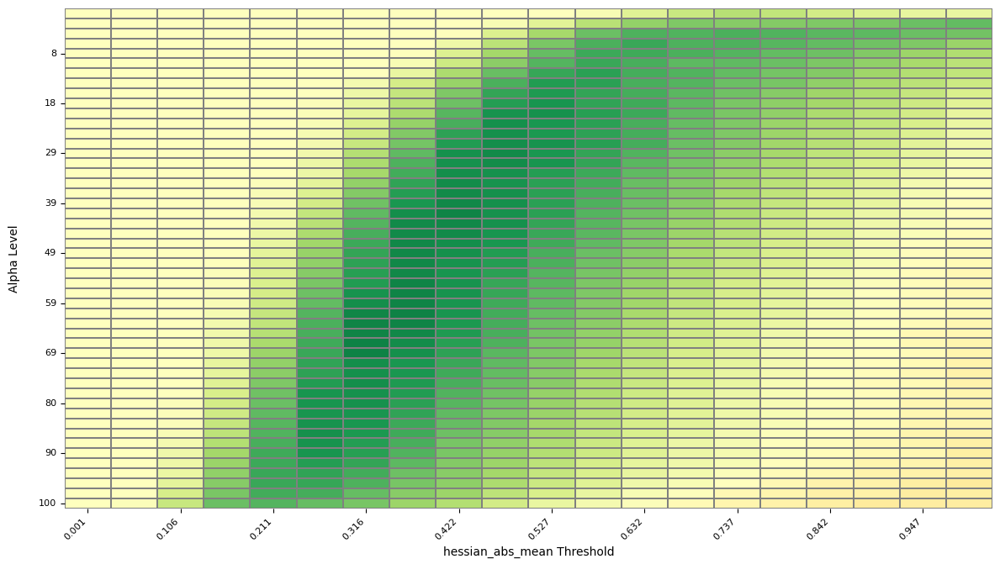

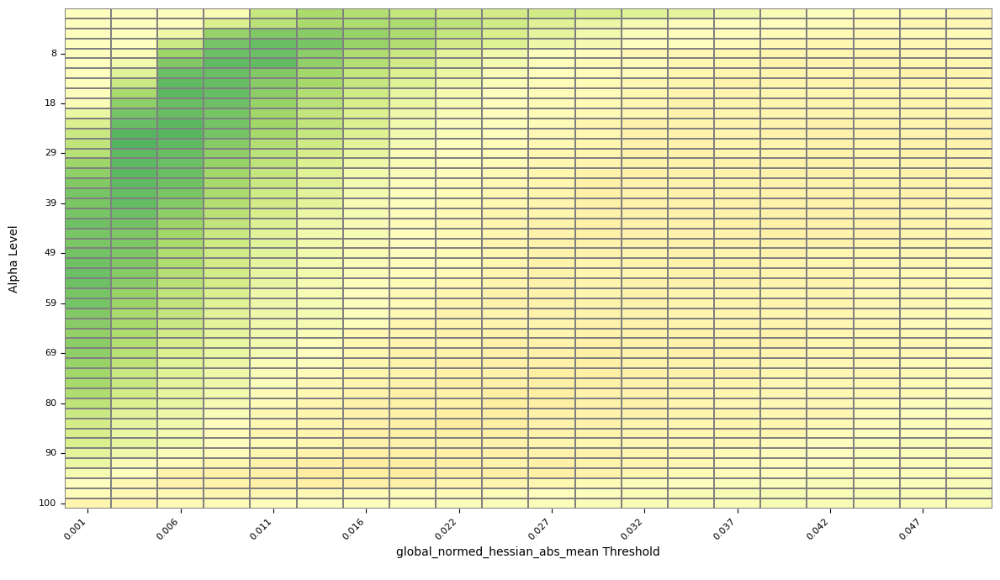

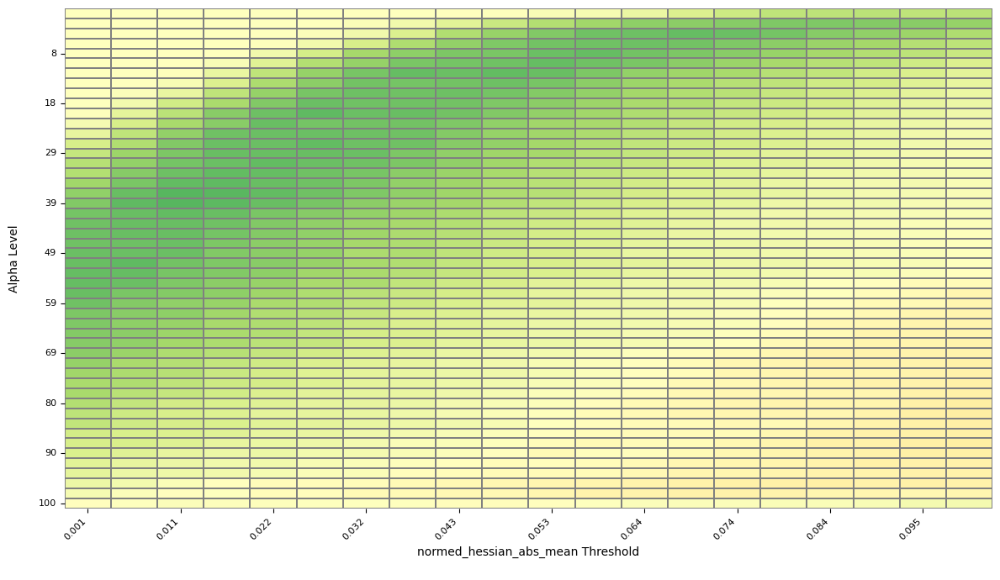

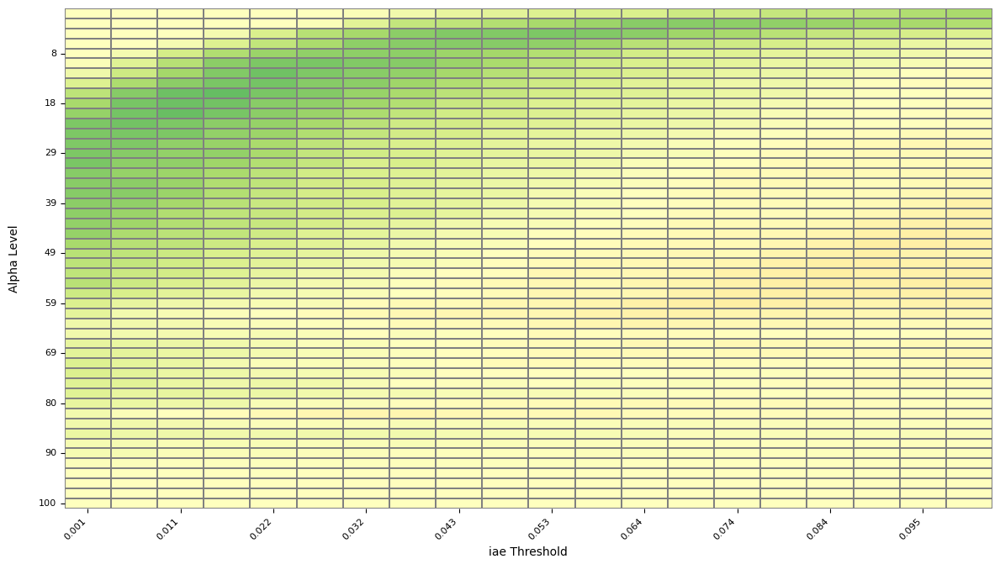

In [ ]:
experiment_name = "dvine_strong_10D_125obs_bootstrap_s3"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=3,
                                                                                                                                              vine_type="D-Vine",
                                                                                                                                              Independence_tree=3)

table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(subset_no_original, subset_no_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(subset_adaptive_original, subset_adaptive_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])


_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="global_normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.03,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_global_normed_hessian_abs_mean.png")


_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_normed_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="iae",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_iae.png")

#### C-Vine

##### normal

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
There are  100 nmber of unique seeds.
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix

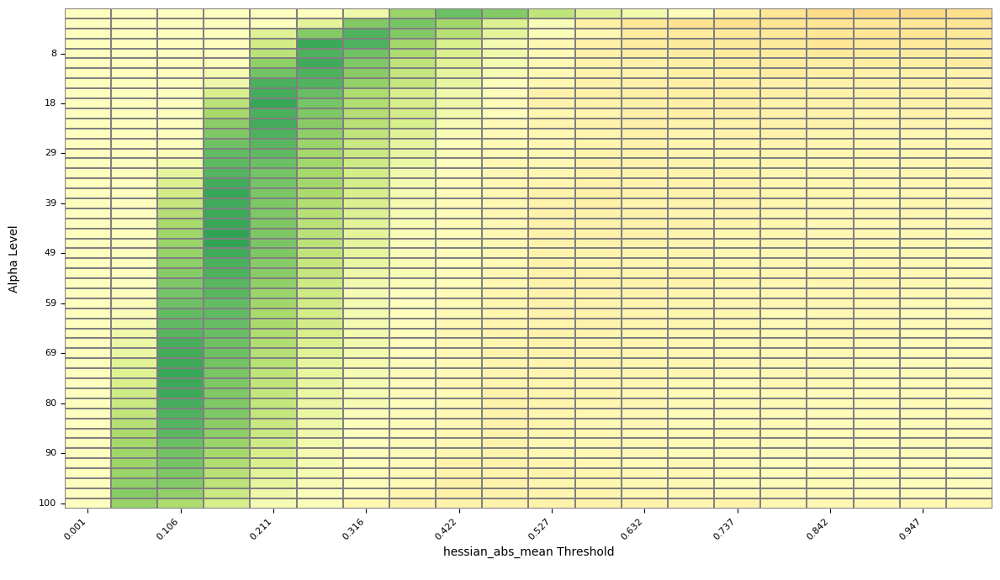

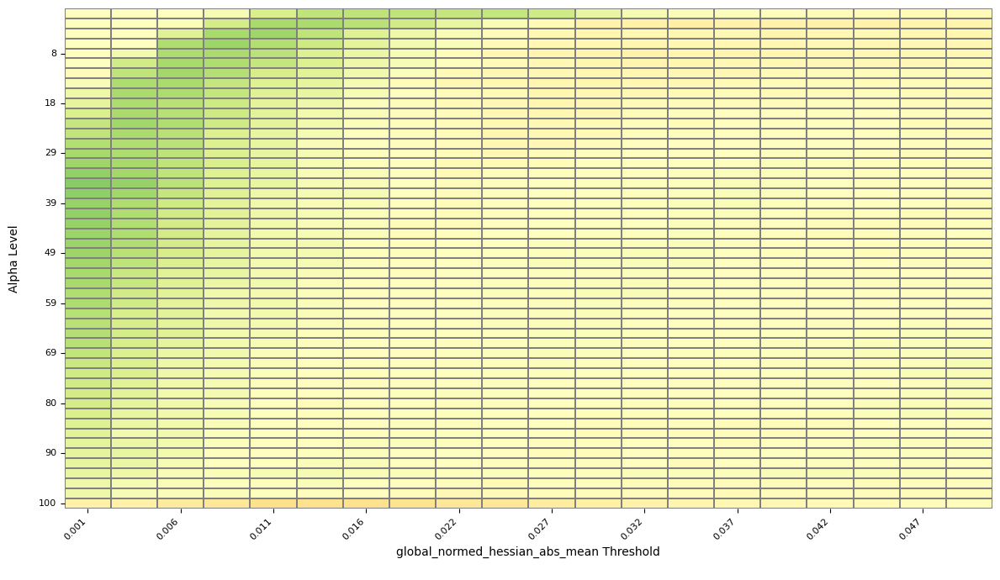

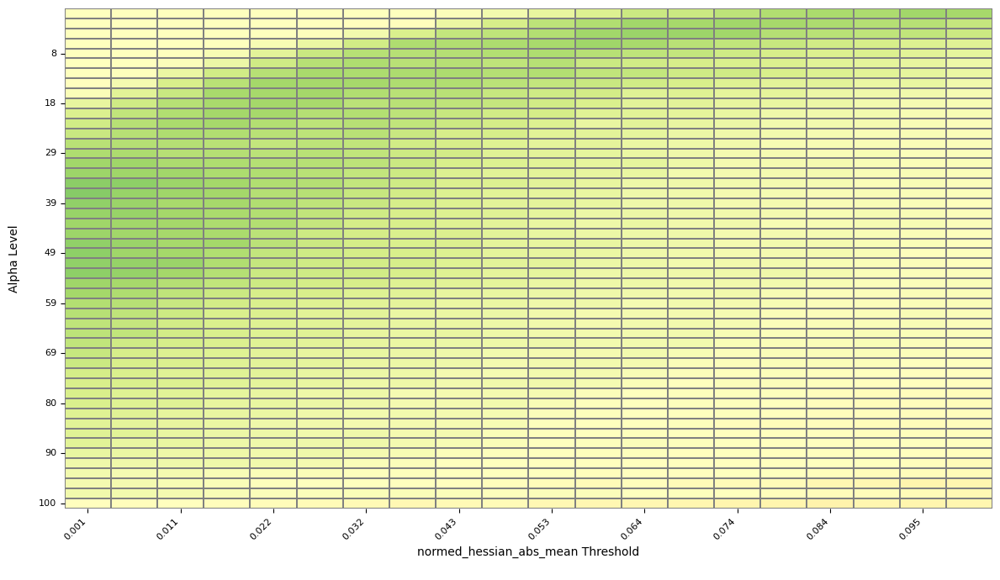

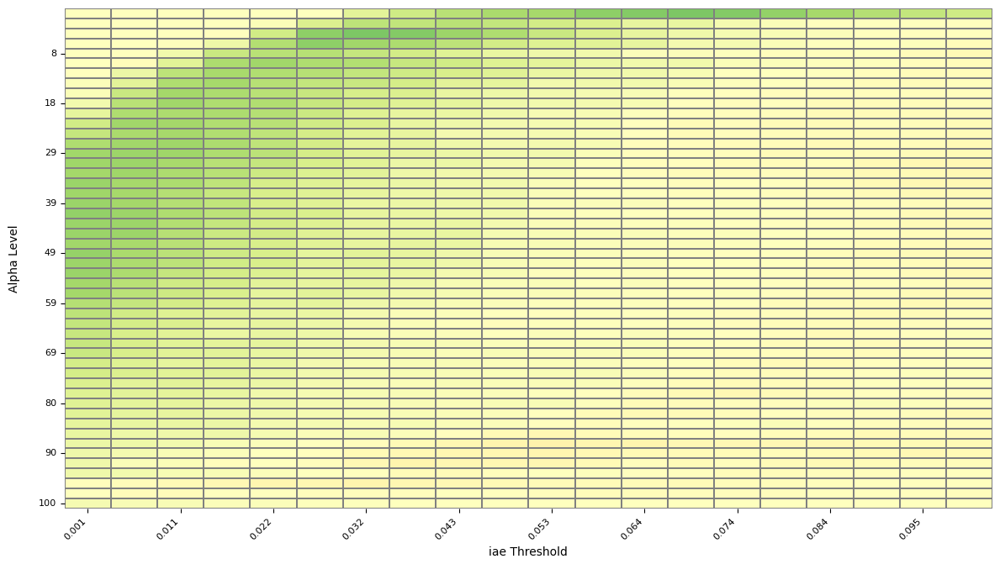

In [ ]:
experiment_name = "cvine_10D_125obs_bootstrap_s2"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=2,
                                                                                                                                              vine_type="C-Vine",
                                                                                                                                              Independence_tree=3)

table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(subset_no_original, subset_no_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(subset_adaptive_original, subset_adaptive_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])


_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="global_normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.03,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_global_normed_hessian_abs_mean.png")


_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_normed_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="iae",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_iae.png")

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
There are  100 nmber of unique seeds.
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix

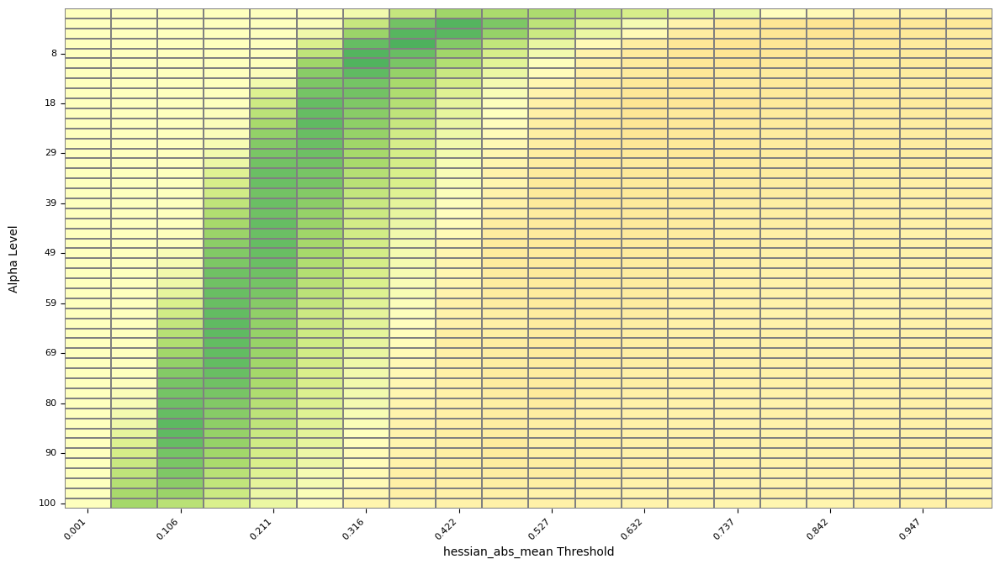

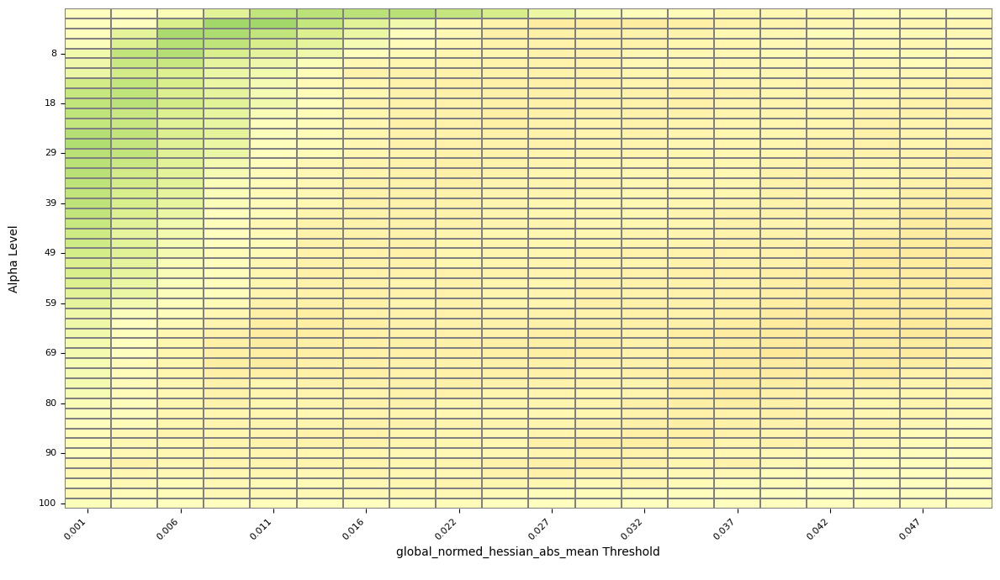

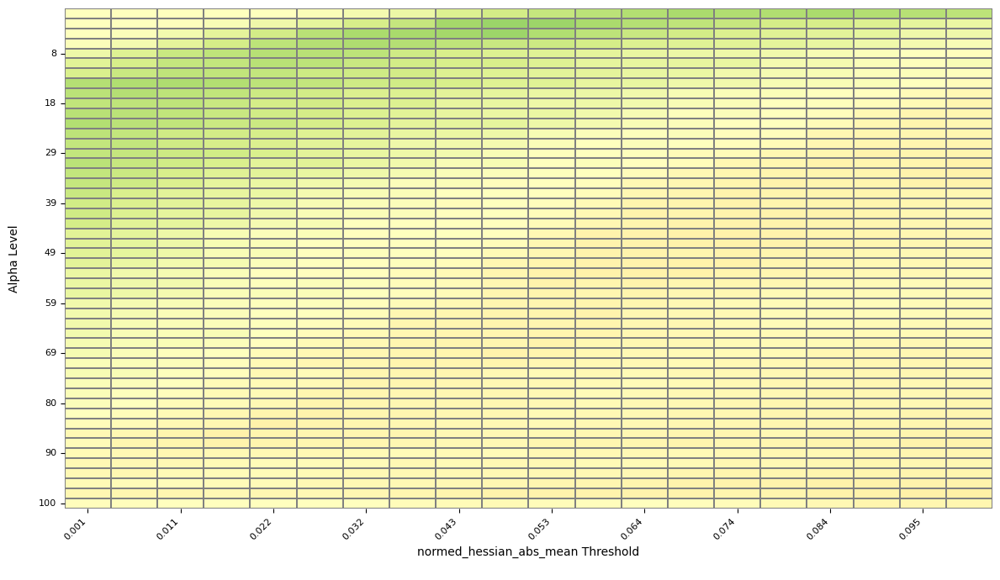

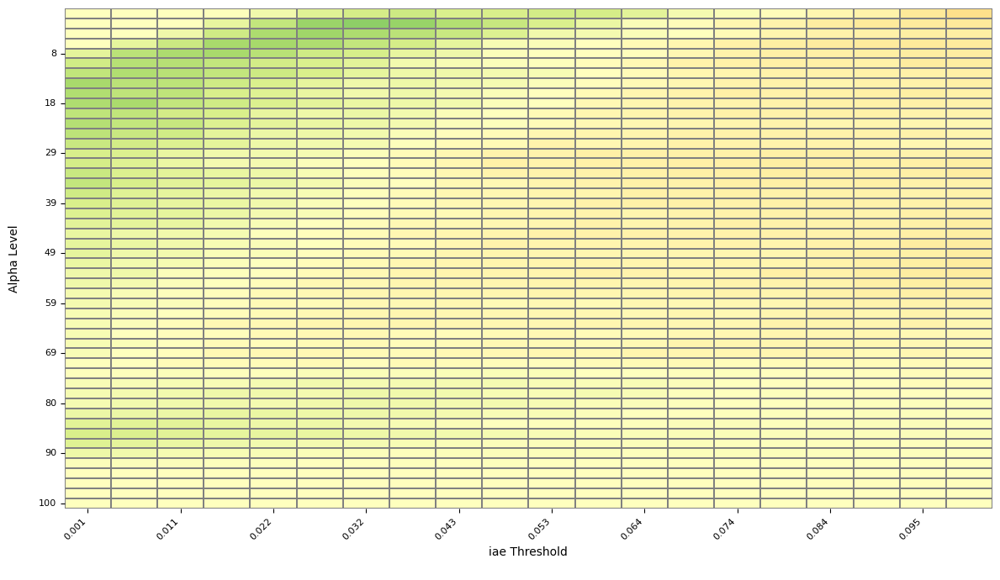

In [ ]:
experiment_name = "cvine_10D_125obs_bootstrap_s3"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=3,
                                                                                                                                              vine_type="C-Vine",
                                                                                                                                              Independence_tree=3)

# take out seed 73 due to error in adaptive bootstrap run:
subset_no_original = subset_no_original[subset_no_original["tags.seed_value"] != "73"]
subset_no_bootstrap = subset_no_bootstrap[subset_no_bootstrap["tags.seed_value"] != "73"]
subset_adaptive_original = subset_adaptive_original[subset_adaptive_original["tags.seed_value"] != "73"]
subset_adaptive_bootstrap = subset_adaptive_bootstrap[subset_adaptive_bootstrap["tags.seed_value"] != "73"]


table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(subset_no_original, subset_no_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(subset_adaptive_original, subset_adaptive_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])


_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="global_normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.03,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_global_normed_hessian_abs_mean.png")


_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_normed_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="iae",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_iae.png")

##### strong

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
There are  100 nmber of unique seeds.
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix

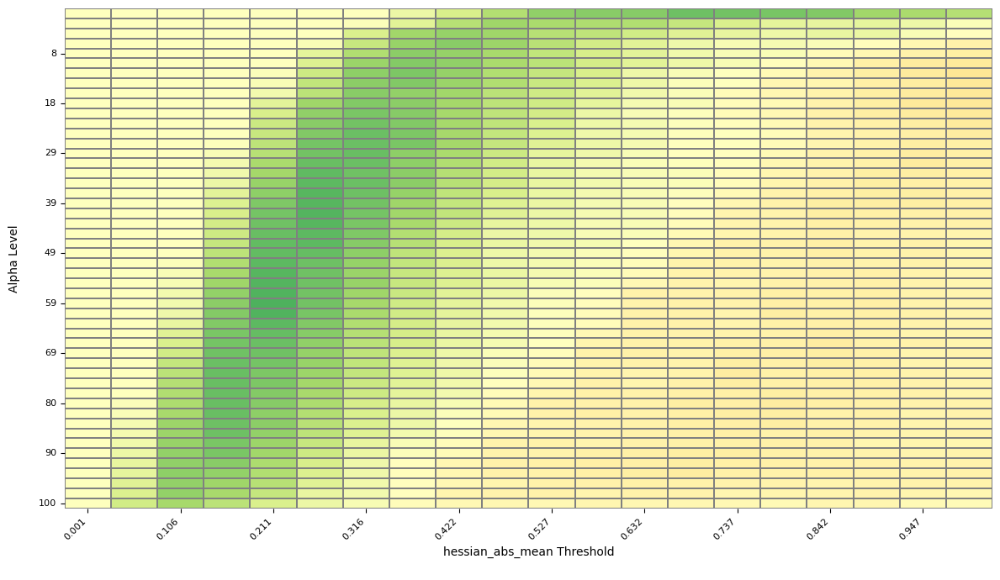

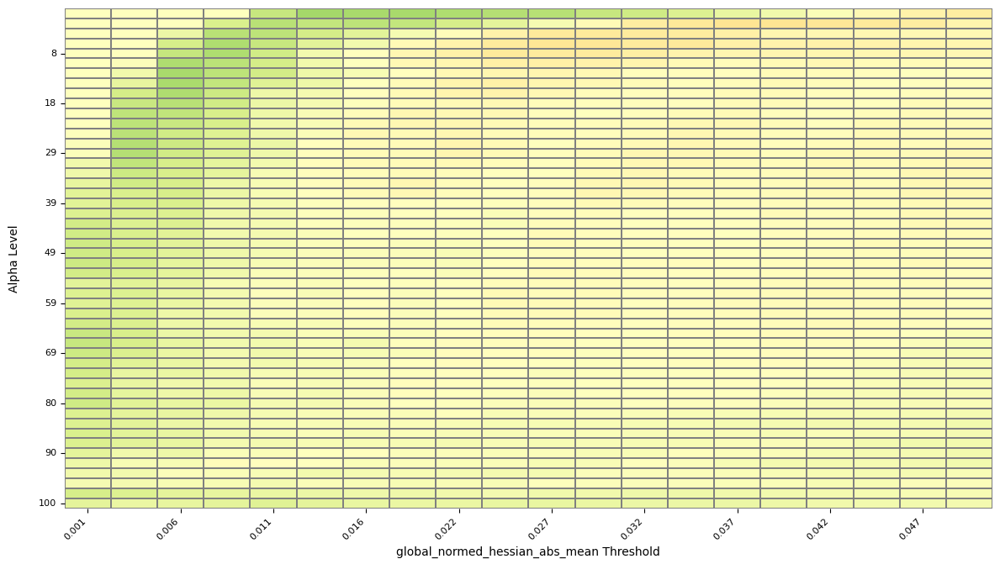

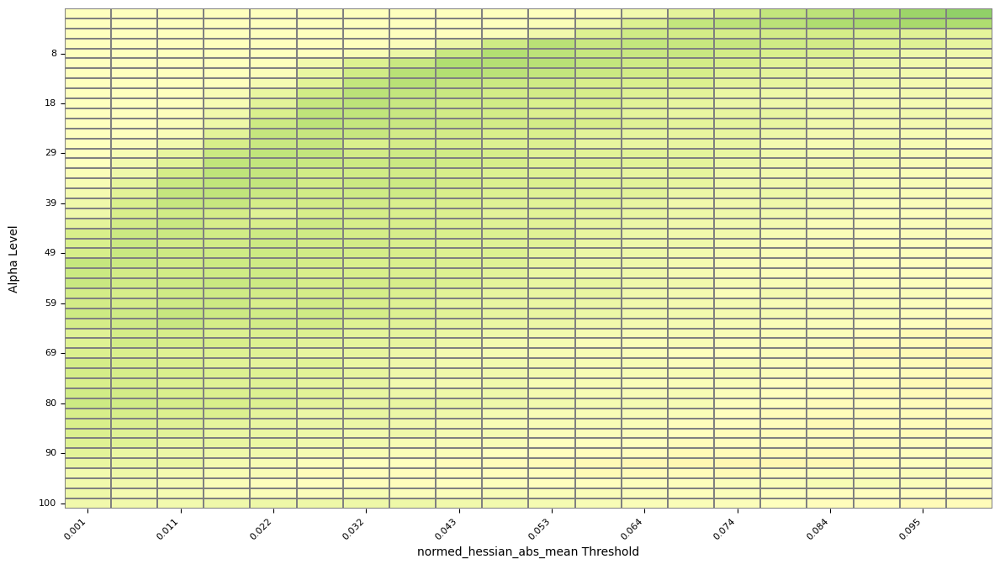

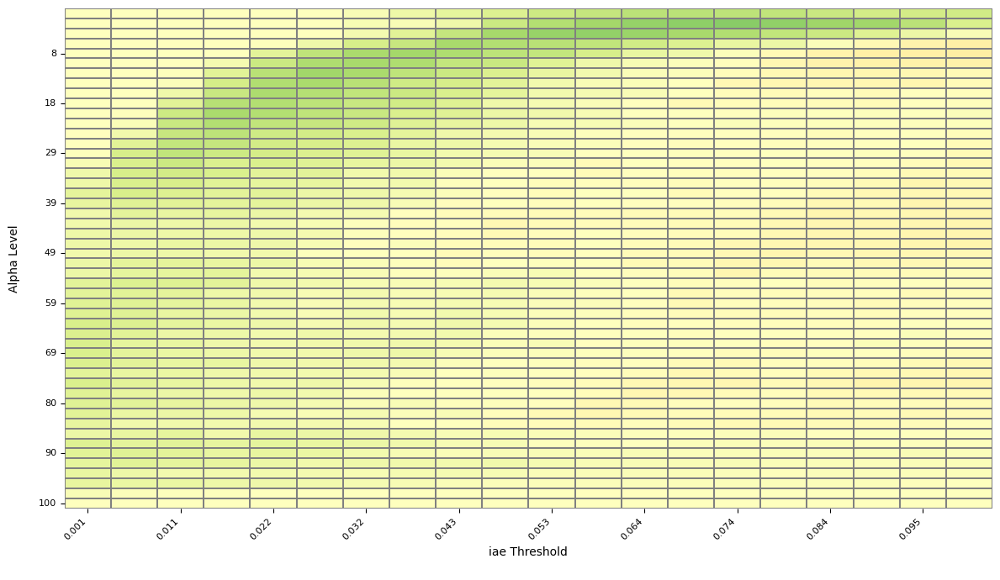

In [ ]:
experiment_name = "cvine_strong_10D_125obs_bootstrap_s2"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=2,
                                                                                                                                              vine_type="C-Vine",
                                                                                                                                              Independence_tree=3)

table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(subset_no_original, subset_no_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(subset_adaptive_original, subset_adaptive_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])


_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="global_normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.03,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_global_normed_hessian_abs_mean.png")


_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_normed_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="iae",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_iae.png")

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
There are  100 nmber of unique seeds.
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix

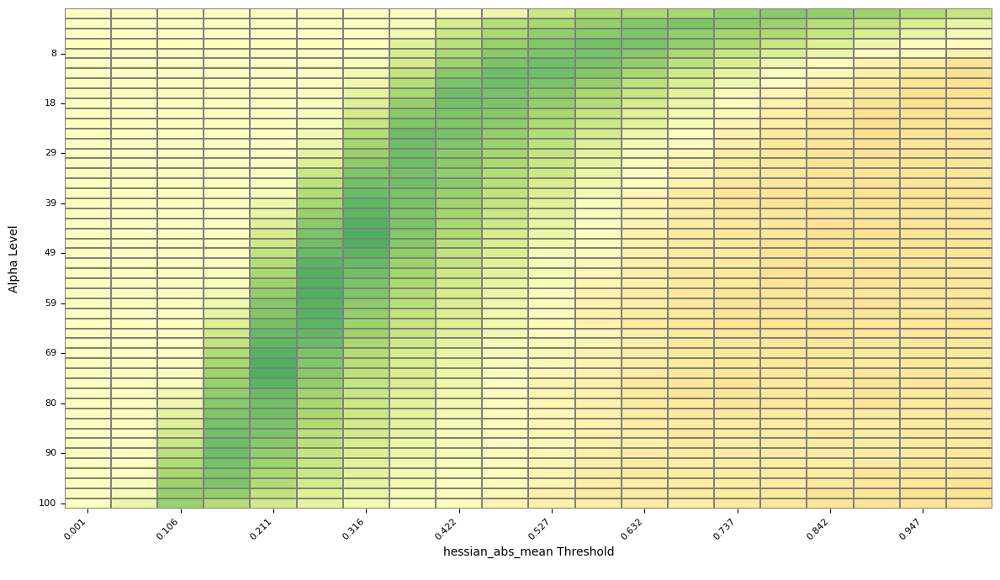

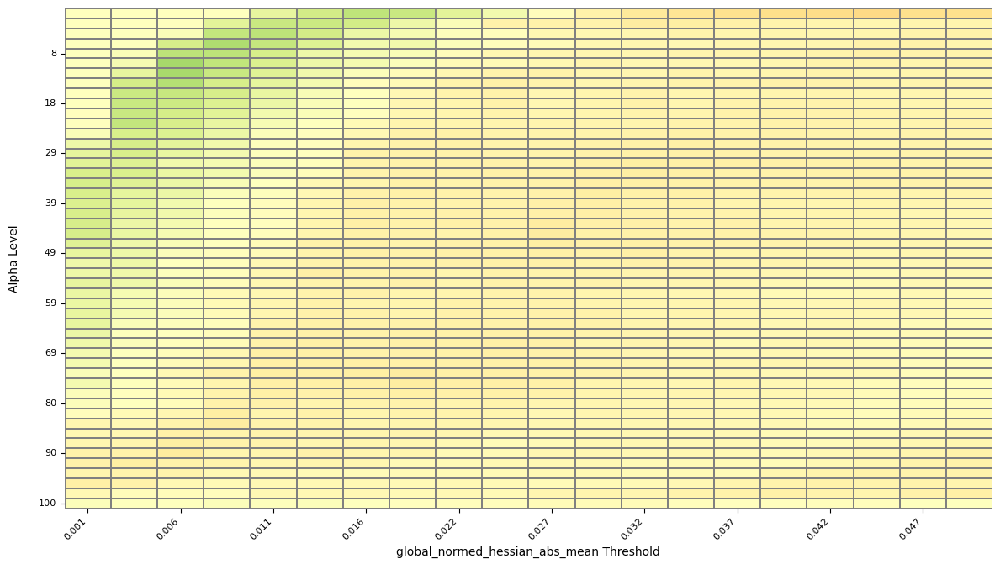

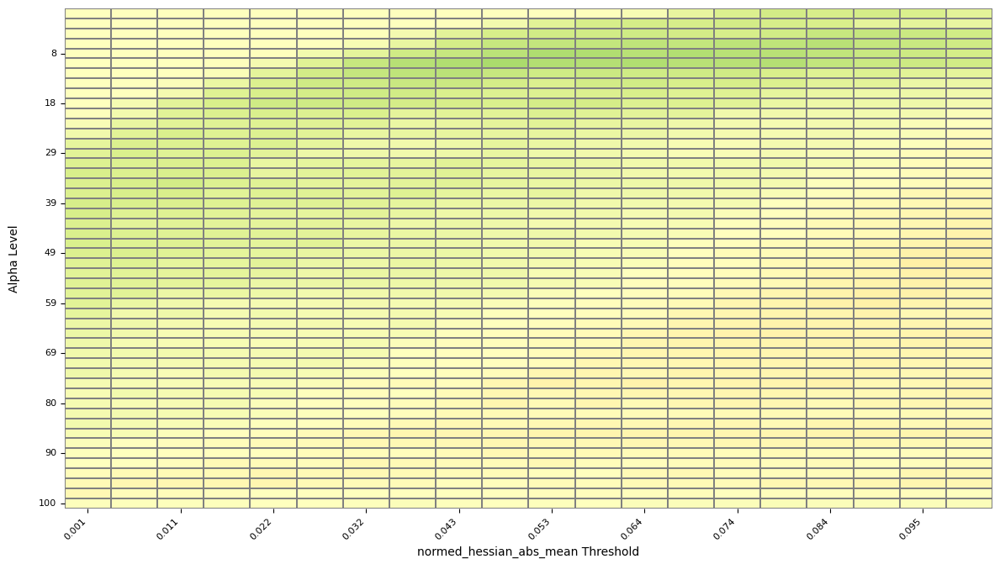

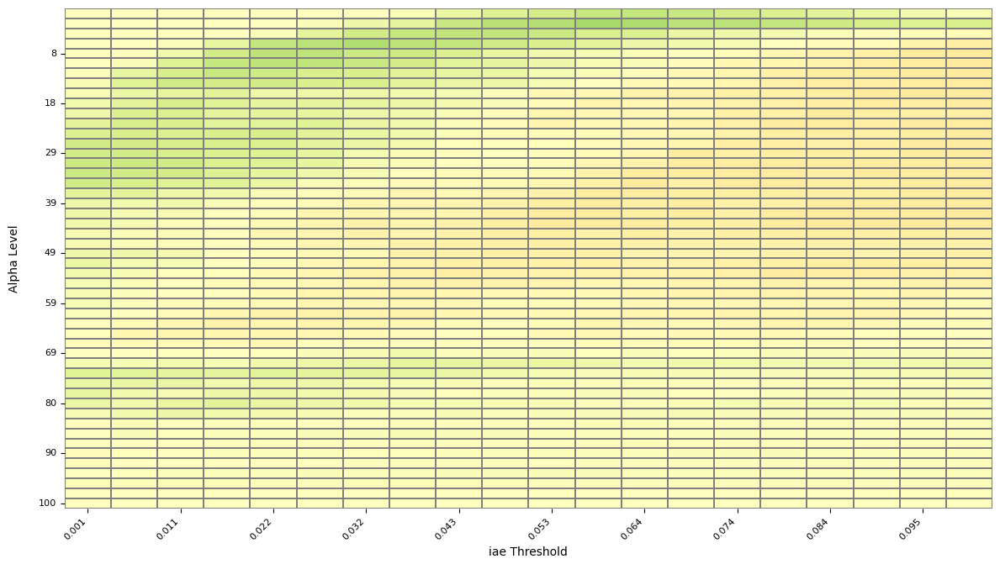

In [ ]:
experiment_name = "cvine_strong_10D_125obs_bootstrap_s3"
subset_no_original, subset_no_bootstrap, subset_adaptive_original, subset_adaptive_bootstrap, df_structure = get_cleaned_runs_subset_bootstrap(experiment_name = experiment_name, 
                                                                                                                                              mlruns_folder_name="mlruns_scratch",
                                                                                                                                              seed_value=3,
                                                                                                                                              vine_type="C-Vine",
                                                                                                                                              Independence_tree=3)

table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(subset_no_original, subset_no_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])

table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(subset_adaptive_original, subset_adaptive_bootstrap,
                                                                        data="synthetic",
                                                                        columns_metrics=['var_row', 'var_col', 
                                'precision_abs_mean', 'cond_correlation_abs_mean',
                                'kld', 'iae', 
                                'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'])


_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="global_normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.03,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_global_normed_hessian_abs_mean.png")


_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="normed_hessian_abs_mean",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_normed_hessian_abs_mean.png")

_ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric="iae",
    plot_dependence="all",       # "all", "dependent", or "independent"
    thresholds=np.linspace(0.001,0.1,20),             # grid of metric thresholds (x-axis of heatmap)
    quantile_bootstrap_intervals=np.linspace(0,1,50),                 # grid of alpha levels for CI (y-axis of heatmap)
    score_type="mcc",             # "f1" or "mcc"
    figsize=(12, 7),
    cmap="RdYlGn",               # diverging colormap: green=adaptive better, red=no better
    center=0.0,                  # center of colormap (0 = no difference)
    vmin=-0.5,
    vmax=0.5,
    show_colorbar=False
)
plt.savefig("heatmap_bootstrap_"+experiment_name+"_iae.png")

## Plots for the paper

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# ── Configuration ─────────────────────────────────────────────────────────────

vine_configs = {
    "cvine": {"vine_type": "C-Vine", "prefix": "cvine"},
    "dvine": {"vine_type": "D-Vine", "prefix": "dvine"},
    "rvine": {"vine_type": "R-Vine", "prefix": "rvine"},
}

strength_types = ["", "_strong"]   # "" = normal, "_strong" = strong

seeds = [2, 3]   # s2 and s3

metrics = [
    "global_normed_hessian_abs_mean",
    "normed_hessian_abs_mean",
    "hessian_abs_mean",
    "iae",
    "precision_abs_mean",
    "cond_correlation_abs_mean",
]

columns_metrics = [
    'var_row', 'var_col',
    'precision_abs_mean', 'cond_correlation_abs_mean',
    #'kld', 
    'iae',
    'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'
]

thresholds_per_metric = {
    "global_normed_hessian_abs_mean" : np.linspace(0.001, 0.03,  20),
    "normed_hessian_abs_mean"        : np.linspace(0.001, 0.03,  20),
    "hessian_abs_mean"               : np.linspace(0.001, 0.5,   20),
    "iae"                            : np.linspace(0.001, 0.1,   20),
    "precision_abs_mean"             : np.linspace(0.001, 0.5,   20),
    "cond_correlation_abs_mean"      : np.linspace(0.001, 0.5,   20),
}

quantile_bootstrap_intervals = np.linspace(0, 1, 50)

# ── Build all combinations ────────────────────────────────────────────────────

combinations = [
    (vine_key, strength, seed_val)
    for vine_key    in vine_configs
    for strength    in strength_types
    for seed_val    in seeds
]

print(f"Total combinations: {len(combinations)} × {len(metrics)} metrics = {len(combinations)*len(metrics)} plots")

# ── Main loop ─────────────────────────────────────────────────────────────────

pbar = tqdm(combinations, desc="Combinations")

for vine_key, strength, seed_val in pbar:

    vine_type   = vine_configs[vine_key]["vine_type"]
    prefix      = vine_configs[vine_key]["prefix"]

    # e.g. "cvine_strong_10D_125obs_bootstrap_s2"
    experiment_name = f"{prefix}{strength}_10D_125obs_bootstrap_s{seed_val}"

    pbar.set_description(f"{experiment_name}")

    try:
        # ── Load runs ─────────────────────────────────────────────────────────
        (
            subset_no_original,
            subset_no_bootstrap,
            subset_adaptive_original,
            subset_adaptive_bootstrap,
            df_structure,
        ) = get_cleaned_runs_subset_bootstrap(
            experiment_name    = experiment_name,
            mlruns_folder_name = "mlruns_scratch",
            seed_value         = seed_val,
            vine_type          = vine_type,
            Independence_tree  = 3,
        )

        # ── Load data tables ──────────────────────────────────────────────────
        table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(
            subset_no_original,
            subset_no_bootstrap,
            data           = "synthetic",
            columns_metrics = columns_metrics,
        )

        table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(
            subset_adaptive_original,
            subset_adaptive_bootstrap,
            data           = "synthetic",
            columns_metrics = columns_metrics,
        )

    except Exception as e:
        tqdm.write(f"  FAILED to load data for {experiment_name} | Reason: {e}")
        continue

    # ── Plot each metric ──────────────────────────────────────────────────────
    pbar_metric = tqdm(metrics, desc=f"  Metrics [{experiment_name}]", position=1, leave=False)

    for metric in pbar_metric:

        pbar_metric.set_description(f"  {metric} [{experiment_name}]")

        try:
            _ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
                table_original_dict_no,
                table_original_dict_adaptive,
                table_diffs_list_no,
                table_diffs_list_adaptive,
                df_structure,
                metric                       = metric,
                plot_dependence              = "all",
                thresholds                   = thresholds_per_metric[metric],
                quantile_bootstrap_intervals = quantile_bootstrap_intervals,
                score_type                   = "mcc",
                figsize                      = (12, 7),
                cmap                         = "RdYlGn",
                center                       = 0.0,
                vmin                         = -0.5,
                vmax                         = 0.5,
                show_colorbar                = False,
            )

            filename = f"heatmap_bootstrap_{experiment_name}_{metric}.png"
            plt.savefig(filename, dpi=150)
            plt.close()
            tqdm.write(f"  Saved: {filename}")

        except Exception as e:
            tqdm.write(f"  FAILED: {experiment_name} | {metric} | Reason: {e}")
            plt.close("all")
            continue

tqdm.write("\nAll done.")

Total combinations: 12 × 6 metrics = 72 plots


cvine_10D_125obs_bootstrap_s2:   0%|          | 0/12 [00:00<?, ?it/s]WARNING:root:Malformed run 'models'. Detailed error Yaml file '/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch/227950049875445749/models/meta.yaml' does not exist.
Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    re

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
There are  100 nmber of unique seeds.


Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


                                                                     
cvine_10D_125obs_bootstrap_s2:   0%|          | 0/12 [00:50<?, ?it/s]                                  

  Saved: heatmap_bootstrap_cvine_10D_125obs_bootstrap_s2_global_normed_hessian_abs_mean.png
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


... (138 outputs left out)

                                                                                      
rvine_strong_10D_125obs_bootstrap_s3:  92%|█████████▏| 11/12 [44:52<04:04, 244.93s/it]                    

  Saved: heatmap_bootstrap_rvine_strong_10D_125obs_bootstrap_s3_precision_abs_mean.png
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


                                                                                      
rvine_strong_10D_125obs_bootstrap_s3: 100%|██████████| 12/12 [45:32<00:00, 227.70s/it]                           

  Saved: heatmap_bootstrap_rvine_strong_10D_125obs_bootstrap_s3_cond_correlation_abs_mean.png

All done.


## Claude

In [50]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from sklearn.metrics import f1_score, matthews_corrcoef

# -------------------------------------------------------------------------
# Sub-functions (unchanged from before)
# -------------------------------------------------------------------------

def _build_keep_mask(df_structure, plot_dependence):
    """
    Sort structure and build boolean mask for which pairs to keep.

    Returns:
        df_structure_sorted : sorted DataFrame
        dependence          : np.array of 0/1 dependence labels
        keep                : boolean mask of which pairs to include
        y_true              : dependence labels for kept pairs
    """
    df_structure_sorted = df_structure.sort_values(by=['var_row', 'var_col']).reset_index(drop=True)
    dependence = df_structure_sorted["dependence"].values

    if plot_dependence == "dependent":
        keep = dependence == 1
    elif plot_dependence == "independent":
        keep = dependence == 0
    else:
        keep = np.ones(len(dependence), dtype=bool)

    y_true = dependence[keep]

    return df_structure_sorted, dependence, keep, y_true


def _build_threshold_grid(table_original_dict_no, table_original_dict_adaptive, metric, keep, n_thresholds):
    """
    Build threshold grid from the actual metric values of kept pairs.
    Covers 0th to 100th percentile of observed metric values.

    Returns:
        thresholds : np.array of shape (n_thresholds,)
    """
    all_vals = []
    for tbl in list(table_original_dict_no.values()) + list(table_original_dict_adaptive.values()):
        all_vals.extend(np.array(tbl[metric])[keep])
    thresholds = np.quantile(all_vals, np.linspace(0.0, 1, n_thresholds))
    return np.array(thresholds)


def _build_quantile_bootstrap_interval_grid(n_quantile_bootstrap_intervals):
    """
    Build grid of quantile levels used to summarise the bootstrap distribution.

    quantile_bootstrap_interval is the quantile level taken from the centered
    bootstrap distribution for each pair. It is then compared to the threshold
    to make the dependence/independence decision:

        predict DEPENDENT   if quantile(bootstrap_centered, quantile_bootstrap_interval) >= threshold
        predict INDEPENDENT if quantile(bootstrap_centered, quantile_bootstrap_interval) <  threshold

    Equivalently:
        predict DEPENDENT if more than (1 - quantile_bootstrap_interval)%
        of bootstrap points exceed the threshold

    So:
        low  quantile_bootstrap_interval → low quantile value → hard to exceed threshold → conservative
        high quantile_bootstrap_interval → high quantile value → easy to exceed threshold → liberal

    Returns:
        quantile_bootstrap_intervals : np.array of shape (n_quantile_bootstrap_intervals,)
    """
    return np.linspace(0.01, 0.99, n_quantile_bootstrap_intervals)


def _build_diff_and_original_arrays(table_original_dict, table_diffs_list, metric, seeds_list):
    """
    For each pair, collect the metric diffs and original values across seeds.

    diffs[p][s]     = original[p,s] - bootstrap[p,s]
    originals[p][s] = original metric value for pair p at seed s

    bootstrap_centered[p, s] = original[p, s] + diffs[p, :]
        → recreates the bootstrap distribution centered on seed s's original estimate
        → we use ALL seeds' diffs to estimate the shape of the bootstrap distribution
           and then center it on the specific seed's original value when scoring

    Returns:
        diffs_dict     : {pair_key: np.array of shape (n_seeds,)}
        originals_dict : {pair_key: np.array of shape (n_seeds,)}
    """
    first_table = table_original_dict[next(iter(table_original_dict))]
    pairs = list(zip(first_table['var_row'], first_table['var_col']))

    diffs_dict = {}
    originals_dict = {}

    for varrow, varcol in pairs:
        pair_key = f"{int(varrow)}-{int(varcol)}"
        diffs_across_seeds = []
        originals_across_seeds = []

        for si, seed in enumerate(seeds_list):
            diff_val = table_diffs_list[si][
                (table_diffs_list[si]['var_col'] == varcol) &
                (table_diffs_list[si]['var_row'] == varrow)
            ][metric].values[0]

            orig_val = table_original_dict[str(seed)][
                (table_original_dict[str(seed)]['var_col'] == varcol) &
                (table_original_dict[str(seed)]['var_row'] == varrow)
            ][metric].values[0]

            diffs_across_seeds.append(diff_val)
            originals_across_seeds.append(orig_val)

        diffs_dict[pair_key]     = np.array(diffs_across_seeds)
        originals_dict[pair_key] = np.array(originals_across_seeds)

    return diffs_dict, originals_dict


def _compute_score_matrix(diffs_dict, originals_dict, kept_pair_keys,
                           seeds_list, thresholds, quantile_bootstrap_intervals,
                           y_true, score_fn):
    """
    Compute score matrix of shape (n_seeds, n_thresholds, n_quantile_bootstrap_intervals).

    For each seed s, pair p, threshold t, quantile_bootstrap_interval q:

        bootstrap_centered[p, :] = original[p, s] + diffs[p, :]
            shape: (n_kept_pairs, n_seeds)
            → bootstrap distribution of pair p centered on seed s's original

        ci_quantile[p, q] = quantile(bootstrap_centered[p, :], q)
            shape: (n_kept_pairs, n_quantile_bootstrap_intervals)
            → the q-th percentile of the bootstrap distribution

        pred[p] = 1 (dependent)   if ci_quantile[p, q] >= threshold
                = 0 (independent) if ci_quantile[p, q] <  threshold

        Equivalent statement:
            predict dependent if more than (1 - q)% of bootstrap points exceed threshold

    Returns:
        score_matrix : np.array of shape (n_seeds, n_thresholds, n_quantile_bootstrap_intervals)
    """
    score_matrix = np.zeros((len(seeds_list), len(thresholds), len(quantile_bootstrap_intervals)))

    # Pre-stack diffs across kept pairs: shape (n_kept_pairs, n_seeds)
    diffs_stacked = np.array([diffs_dict[pk] for pk in kept_pair_keys])

    for si, seed in enumerate(seeds_list):

        # Original values for this seed: shape (n_kept_pairs,)
        orig_vals = np.array([originals_dict[pk][si] for pk in kept_pair_keys])

        # Bootstrap centered on this seed's original: shape (n_kept_pairs, n_seeds)
        bootstrap_centered = orig_vals[:, np.newaxis] + diffs_stacked

        # quantile_bootstrap_interval-quantile per pair: shape (n_kept_pairs, n_quantile_bootstrap_intervals)
        ci_quantiles = np.quantile(bootstrap_centered, quantile_bootstrap_intervals, axis=1).T

        for ti, thresh in enumerate(thresholds):
            for qi in range(len(quantile_bootstrap_intervals)):
                pred = (ci_quantiles[:, qi] >= thresh).astype(int)
                try:
                    score = score_fn(y_true, pred)
                except Exception:
                    score = 0.0
                score_matrix[si, ti, qi] = score

    return score_matrix


def _compute_mean_diff(scores_adaptive, scores_no):
    """
    Compute mean score difference (adaptive - no) across seeds.

    Returns:
        mean_diff : np.array of shape (n_thresholds, n_quantile_bootstrap_intervals)
    """
    return np.mean(scores_adaptive - scores_no, axis=0)


def _plot_heatmap(mean_diff, thresholds, quantile_bootstrap_intervals,
                   xlabel, plot_dependence, score_type, n_seeds, figsize, cmap, center,
                   show_colorbar=True,      # whether to show the colorbar
                   vmin=None,               # min value for colorbar scaling
                   vmax=None,               # max value for colorbar scaling
                   ):
    """
    Plot the heatmap of mean score differences.

    Axes:
        x-axis : metric threshold                (higher → harder to predict dependent)
        y-axis : quantile_bootstrap_interval     (lower  → conservative,
                                                  higher → liberal)
    Colormap:
        Green (positive) : Adaptive Lasso scores higher
        Red   (negative) : No Lasso scores higher

    Note: `figsize` always sets the size of the main heatmap axis itself.
    When show_colorbar=True, the colorbar is drawn as an inset OUTSIDE the
    heatmap's bounding box (via inset_axes anchored to the axes, not the
    figure), so the heatmap square is identical in size whether or not a
    colorbar is shown. Save with bbox_inches='tight' so the colorbar isn't
    clipped off the saved figure.
    """
    fig, ax = plt.subplots(figsize=figsize)

    threshold_labels                   = [f"{t:.3f}" for t in thresholds]
    #quantile_bootstrap_interval_labels = [f"{(1-q)*100:.0f}" for q in quantile_bootstrap_intervals]  # alpha levels
    quantile_bootstrap_interval_labels = [f"{(q)*100:.0f}" for q in quantile_bootstrap_intervals]  # alpha levels

    heatmap_data = mean_diff.T  # rows=quantile_bootstrap_interval, cols=threshold

    if show_colorbar:
        # Inset colorbar axis anchored just outside the heatmap axis, so it
        # does not consume space from `ax` itself.
        cax = inset_axes(
            ax,
            width="4%", height="100%",
            loc="lower left",
            bbox_to_anchor=(1.03, 0.0, 1, 1),
            bbox_transform=ax.transAxes,
            borderpad=0,
        )
        cbar_kws = {"label": r"$\Delta$ MCC"}
    else:
        cax = None
        cbar_kws = {}

    hm = sns.heatmap(
        heatmap_data,
        ax=ax,
        xticklabels=threshold_labels,
        yticklabels=quantile_bootstrap_interval_labels,
        cmap=cmap,
        center=center,
        vmin=vmin,          # fix min color level — same value across plots = same color
        vmax=vmax,          # fix max color level — same value across plots = same color
        linewidths=0,        # no grid lines between cells
        linecolor=None,
        annot=(len(thresholds) * len(quantile_bootstrap_intervals) <= 400),
        fmt=".2f",
        cbar=show_colorbar,
        cbar_ax=cax,
        cbar_kws=cbar_kws,
    )
    
    if show_colorbar:
        cbar = hm.collections[0].colorbar
        cbar.set_label(r"$\Delta$ MCC", fontsize=20)
        cbar.ax.tick_params(labelsize=8)

    # Low quantile_bootstrap_interval at bottom, high at top
    ax.invert_yaxis()

    # Reduce tick density for large grids
    xtick_step = max(1, len(thresholds)                    // min(10, len(thresholds)))
    ytick_step = max(1, len(quantile_bootstrap_intervals)  // min(10, len(quantile_bootstrap_intervals)))

    ax.set_xticks(np.arange(0, len(thresholds), xtick_step) + 0.5)
    ax.set_xticklabels(
        [threshold_labels[i] for i in range(0, len(thresholds), xtick_step)],
        rotation=45, ha='right', fontsize=8
    )
    ax.set_yticks(np.arange(0, len(quantile_bootstrap_intervals), ytick_step) + 0.5)
    ax.set_yticklabels(
        [quantile_bootstrap_interval_labels[i] for i in range(0, len(quantile_bootstrap_intervals), ytick_step)],
        rotation=0, fontsize=8
    )

    ax.set_xlabel(f"{xlabel} threshold $L$", fontsize=35) #20
    ax.set_ylabel(r"$\alpha$ level", fontsize=35) #20

    plt.tight_layout()
    #plt.show()


# -------------------------------------------------------------------------
# Main function
# -------------------------------------------------------------------------

def plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
    table_original_dict_no,
    table_original_dict_adaptive,
    table_diffs_list_no,
    table_diffs_list_adaptive,
    df_structure,
    metric,
    xlabel,                    # NEW: LaTeX string for the x-axis (metric symbol)
    plot_dependence="all",
    thresholds=None,
    quantile_bootstrap_intervals=None,
    score_type="f1",
    n_thresholds=30,
    n_quantile_bootstrap_intervals=20,
    figsize=(12, 7),
    cmap="RdYlGn",
    center=0.0,
    show_colorbar=False,      # whether to show the colorbar
    vmin=None,               # min value for colorbar scaling
    vmax=None,               # max value for colorbar scaling
):
    """
    For each combination of (metric_threshold, quantile_bootstrap_interval):

        1. Center the bootstrap distribution on each seed's original estimate:
               bootstrap_centered[p, s] = original[p, s] + diffs[p, :]

        2. Take the quantile_bootstrap_interval-th quantile of that distribution:
               ci_quantile[p, q] = quantile(bootstrap_centered[p, :], q)

        3. Predict dependence if that quantile exceeds the threshold:
               predict DEPENDENT   if ci_quantile[p, q] >= threshold
               predict INDEPENDENT if ci_quantile[p, q] <  threshold

           Equivalently:
               predict DEPENDENT if more than (1-q)% of bootstrap points exceed threshold

        4. Compute F1/MCC score per seed, then plot the mean difference
           (Adaptive - No Lasso) as a heatmap over the (threshold, q) grid.
    """
    seeds_list = list(table_original_dict_no.keys())

    # 1. Structure and keep mask
    df_structure_sorted, dependence, keep, y_true = _build_keep_mask(
        df_structure, plot_dependence
    )

    # 2. Threshold grid
    if thresholds is None:
        thresholds = _build_threshold_grid(
            table_original_dict_no, table_original_dict_adaptive, metric, keep, n_thresholds
        )
    thresholds = np.array(thresholds)

    # 3. Quantile bootstrap interval grid
    if quantile_bootstrap_intervals is None:
        quantile_bootstrap_intervals = _build_quantile_bootstrap_interval_grid(
            n_quantile_bootstrap_intervals
        )
    quantile_bootstrap_intervals = np.array(quantile_bootstrap_intervals)

    # 4. Score function
    score_funcs = {
        "f1":  lambda yt, yp: f1_score(yt, yp, zero_division=0),
        "mcc": matthews_corrcoef,
    }
    if score_type not in score_funcs:
        raise ValueError("score_type must be 'f1' or 'mcc'")
    score_fn = score_funcs[score_type]

    # 5. Pair keys aligned with structure, filtered by keep mask
    all_pair_keys = [
        f"{int(row)}-{int(col)}"
        for row, col in zip(
            df_structure_sorted['var_row'].values,
            df_structure_sorted['var_col'].values
        )
    ]
    kept_pair_keys = [pk for pk, k in zip(all_pair_keys, keep) if k]

    # 6. Build diff and original arrays
    print("Building bootstrap arrays for No Lasso...")
    diffs_dict_no, originals_dict_no = _build_diff_and_original_arrays(
        table_original_dict_no, table_diffs_list_no, metric, seeds_list
    )
    print("Building bootstrap arrays for Adaptive Lasso...")
    diffs_dict_adaptive, originals_dict_adaptive = _build_diff_and_original_arrays(
        table_original_dict_adaptive, table_diffs_list_adaptive, metric, seeds_list
    )

    # 7. Compute score matrices
    print("Computing score matrix for No Lasso...")
    scores_no = _compute_score_matrix(
        diffs_dict_no, originals_dict_no, kept_pair_keys,
        seeds_list, thresholds, quantile_bootstrap_intervals, y_true, score_fn
    )
    print("Computing score matrix for Adaptive Lasso...")
    scores_adaptive = _compute_score_matrix(
        diffs_dict_adaptive, originals_dict_adaptive, kept_pair_keys,
        seeds_list, thresholds, quantile_bootstrap_intervals, y_true, score_fn
    )

    # 8. Mean difference across seeds
    mean_diff = _compute_mean_diff(scores_adaptive, scores_no)

    # 9. Plot
    _plot_heatmap(
        mean_diff, thresholds, quantile_bootstrap_intervals,
        xlabel, plot_dependence, score_type, len(seeds_list), figsize, cmap, center,
        show_colorbar=show_colorbar, vmin=vmin, vmax=vmax
    )

    return {
        "mean_diff":                    mean_diff,
        "scores_adaptive":              scores_adaptive,
        "scores_no":                    scores_no,
        "thresholds":                   thresholds,
        "quantile_bootstrap_intervals": quantile_bootstrap_intervals,
    }

In [51]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import mlflow

# ── Configuration ─────────────────────────────────────────────────────────────

vine_configs = {
    "cvine": {"vine_type": "C-Vine", "prefix": "cvine"},
    "dvine": {"vine_type": "D-Vine", "prefix": "dvine"},
    "rvine": {"vine_type": "R-Vine", "prefix": "rvine"},
}

strength_types = ["", "_strong"]   # "" = normal, "_strong" = strong

seeds = [2, 3]   # s2 and s3

metrics = [
    "global_normed_hessian_abs_mean",
    "normed_hessian_abs_mean",
    "hessian_abs_mean",
    "iae",
    "precision_abs_mean",
    "cond_correlation_abs_mean",
]

columns_metrics = [
    'var_row', 'var_col',
    'precision_abs_mean', 'cond_correlation_abs_mean',
    #'kld',
    'iae',
    'global_normed_hessian_abs_mean', 'normed_hessian_abs_mean', 'hessian_abs_mean'
]

thresholds_per_metric = {
    "global_normed_hessian_abs_mean" : np.linspace(0.001, 0.03,  20),
    "normed_hessian_abs_mean"        : np.linspace(0.001, 0.03,  20),
    "hessian_abs_mean"               : np.linspace(0.001, 0.5,   20),
    "iae"                            : np.linspace(0.001, 0.1,   20),
    "precision_abs_mean"             : np.linspace(0.001, 0.5,   20),
    "cond_correlation_abs_mean"      : np.linspace(0.001, 0.5,   20),
}

# LaTeX x-axis labels per metric
metric_xlabels = {
    "iae"                            : r"$\mathrm{IAE}$",
    "hessian_abs_mean"                : r"$|\overline{\mathbf{H}_{u,v}}|$",
    "normed_hessian_abs_mean"         : r"$|\overline{\breve{\mathbf{H}}_{u,v}^{(2)}}|$",
    "global_normed_hessian_abs_mean"  : r"$|\overline{\breve{\mathbf{H}}_{u,v}}|$",
    "precision_abs_mean"              : r"$|p_{r,c,-}|$",
    "cond_correlation_abs_mean"       : r"$|\rho_{r,c,-}|$",
}

quantile_bootstrap_intervals = np.linspace(0, 1, 50)

# Base heatmap axis size — identical for every vine type; the colorbar (only
# added for C-vine) is drawn as an inset outside this axis, so it never
# changes the square size of the heatmap itself.
base_figsize = (10, 7)

# ── Build all combinations ────────────────────────────────────────────────────

combinations = [
    (vine_key, strength, seed_val)
    for vine_key    in vine_configs
    for strength    in strength_types
    for seed_val    in seeds
]

print(f"Total combinations: {len(combinations)} × {len(metrics)} metrics = {len(combinations)*len(metrics)} plots")

# ── Main loop ─────────────────────────────────────────────────────────────────

pbar = tqdm(combinations, desc="Combinations")

for vine_key, strength, seed_val in pbar:

    vine_type   = vine_configs[vine_key]["vine_type"]
    prefix      = vine_configs[vine_key]["prefix"]

    # Only C-vine gets the legend/colorbar
    show_colorbar = (vine_key == "cvine")

    # e.g. "cvine_strong_10D_125obs_bootstrap_s2"
    experiment_name = f"{prefix}{strength}_10D_125obs_bootstrap_s{seed_val}"

    pbar.set_description(f"{experiment_name} | cbar={show_colorbar}")

    try:
        # ── Load runs ─────────────────────────────────────────────────────────
        (
            subset_no_original,
            subset_no_bootstrap,
            subset_adaptive_original,
            subset_adaptive_bootstrap,
            df_structure,
        ) = get_cleaned_runs_subset_bootstrap(
            experiment_name    = experiment_name,
            mlruns_folder_name = "mlruns_scratch",
            seed_value         = seed_val,
            vine_type          = vine_type,
            Independence_tree  = 3,
        )

        # ── Load data tables ──────────────────────────────────────────────────
        table_diffs_list_no, table_original_dict_no = get_data_original_and_bootstrap(
            subset_no_original,
            subset_no_bootstrap,
            data           = "synthetic",
            columns_metrics = columns_metrics,
        )

        table_diffs_list_adaptive, table_original_dict_adaptive = get_data_original_and_bootstrap(
            subset_adaptive_original,
            subset_adaptive_bootstrap,
            data           = "synthetic",
            columns_metrics = columns_metrics,
        )

    except Exception as e:
        tqdm.write(f"  FAILED to load data for {experiment_name} | Reason: {e}")
        continue

    # ── Plot each metric ──────────────────────────────────────────────────────
    pbar_metric = tqdm(metrics, desc=f"  Metrics [{experiment_name}]", position=1, leave=False)

    for metric in pbar_metric:

        pbar_metric.set_description(f"  {metric} [{experiment_name}]")

        try:
            _ = plot_heatmap_score_diff_threshold_vs_quantile_bootstrap_interval(
                table_original_dict_no,
                table_original_dict_adaptive,
                table_diffs_list_no,
                table_diffs_list_adaptive,
                df_structure,
                metric                       = metric,
                xlabel                       = metric_xlabels[metric],
                plot_dependence              = "all",
                thresholds                   = thresholds_per_metric[metric],
                quantile_bootstrap_intervals = quantile_bootstrap_intervals,
                score_type                   = "mcc",
                figsize                      = base_figsize,
                cmap                         = "RdYlGn",
                center                       = 0.0,
                vmin                         = -0.5,
                vmax                         = 0.5,
                show_colorbar                = show_colorbar,
            )

            filename = f"heatmap_bootstrap_{experiment_name}_{metric}.png"
            # bbox_inches='tight' ensures the C-vine colorbar (drawn outside
            # the heatmap axis) isn't clipped from the saved image.
            plt.savefig(filename, dpi=150, bbox_inches='tight')
            plt.close()
            tqdm.write(f"  Saved: {filename}")

        except Exception as e:
            tqdm.write(f"  FAILED: {experiment_name} | {metric} | Reason: {e}")
            plt.close("all")
            continue

tqdm.write("\nAll done.")

Total combinations: 12 × 6 metrics = 72 plots


cvine_10D_125obs_bootstrap_s2 | cbar=True:   0%|          | 0/12 [00:00<?, ?it/s]WARNING:root:Malformed run 'models'. Detailed error Yaml file '/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch/227950049875445749/models/meta.yaml' does not exist.
Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read

The unique seeds are: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
There are  100 nmber of unique seeds.


Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...



cvine_10D_125obs_bootstrap_s2 | cbar=True:   0%|          | 0/12 [01:16<?, ?it/s]                      

  Saved: heatmap_bootstrap_cvine_10D_125obs_bootstrap_s2_global_normed_hessian_abs_mean.png
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


... (138 outputs left out)

                                                                                                      
rvine_strong_10D_125obs_bootstrap_s3 | cbar=False:  92%|█████████▏| 11/12 [6:11:56<38:00, 2280.24s/it]    

  Saved: heatmap_bootstrap_rvine_strong_10D_125obs_bootstrap_s3_precision_abs_mean.png
Building bootstrap arrays for No Lasso...
Building bootstrap arrays for Adaptive Lasso...
Computing score matrix for No Lasso...
Computing score matrix for Adaptive Lasso...


                                                                                                      
rvine_strong_10D_125obs_bootstrap_s3 | cbar=False: 100%|██████████| 12/12 [6:12:53<00:00, 1864.45s/it]           

  Saved: heatmap_bootstrap_rvine_strong_10D_125obs_bootstrap_s3_cond_correlation_abs_mean.png

All done.
